In [1]:
!pip -q install catboost xgboost mlxtend fastapi uvicorn pyngrok joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.2 MB/s eta 0:00:00


In [2]:
import os
import gc
import json
import joblib
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✅ CrimeGuard environment ready")

✅ CrimeGuard environment ready


In [3]:
from google.colab import files

uploaded = files.upload()

CSV_FILE = list(uploaded.keys())[0]

print("Uploaded:", CSV_FILE)

Saving Crimes_-_2025_20261005.csv to Crimes_-_2025_20261005.csv
Uploaded: Crimes_-_2025_20261005.csv


In [4]:
df = pd.read_csv(
    CSV_FILE,
    low_memory=False
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (238106, 22)


,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,...,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,14075483,JK105557,12/31/2025 11:58:00 PM,050XX S PAULINA ST,0560,ASSAULT,SIMPLE,RESIDENCE,False,False,...,20.0,61.0,08A,1165860.0,1871343.0,2025,10/01/2026 03:42:27 PM,41.802549,-87.667246,POINT (-87.667246428 41.802549018)
1,14070833,JK100050,12/31/2025 11:55:00 PM,053XX W WASHINGTON BLVD,0930,MOTOR VEHICLE THEFT,THEFT / RECOVERY - AUTOMOBILE,APARTMENT,False,True,...,37.0,25.0,07,1140809.0,1900235.0,2025,10/01/2026 03:42:27 PM,41.882329,-87.758411,POINT (-87.758411303 41.882328854)
2,14070745,JK100011,12/31/2025 11:54:00 PM,100XX W OHARE ST,2890,PUBLIC PEACE VIOLATION,OTHER VIOLATION,AIRCRAFT,False,False,...,41.0,76.0,24,1100658.0,1934241.0,2025,10/01/2026 03:42:27 PM,41.976290,-87.905227,POINT (-87.905227221 41.976290414)
3,14070799,JK100014,12/31/2025 11:54:00 PM,100XX W OHARE ST,2890,PUBLIC PEACE VIOLATION,OTHER VIOLATION,AIRCRAFT,False,False,...,41.0,76.0,24,1100658.0,1934241.0,2025,10/01/2026 03:42:27 PM,41.976290,-87.905227,POINT (-87.905227221 41.976290414)
4,14070845,JK100006,12/31/2025 11:54:00 PM,013XX W LAKE ST,0454,BATTERY,"AGGRAVATED P.O. - HANDS, FISTS, FEET, NO / MIN...",RESTAURANT,True,False,...,27.0,28.0,08B,1167120.0,1901555.0,2025,10/01/2026 03:42:27 PM,41.885427,-87.661759,POINT (-87.661759042 41.885426714)


In [5]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nColumns:")
for i, col in enumerate(df.columns, 1):
    print(i, "-", col)

print("\nMissing values:")
display(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing")
)

Rows: 238106
Columns: 22

Columns:
1 - ID
2 - Case Number
3 - Date
4 - Block
5 - IUCR
6 - Primary Type
7 - Description
8 - Location Description
9 - Arrest
10 - Domestic
11 - Beat
12 - District
13 - Ward
14 - Community Area
15 - FBI Code
16 - X Coordinate
17 - Y Coordinate
18 - Year
19 - Updated On
20 - Latitude
21 - Longitude
22 - Location

Missing values:


,Missing
Longitude,2645
X Coordinate,2645
Location,2645
Y Coordinate,2645
Latitude,2645
Location Description,1225
Community Area,9
Ward,1
Primary Type,0
IUCR,0


In [6]:
TARGET = "Primary Type"

crime_counts = df[TARGET].value_counts()

print("Number of crime classes:", len(crime_counts))

display(
    crime_counts.to_frame("Count")
)

Number of crime classes: 31


,Count
Primary Type,
THEFT,55198
BATTERY,42660
CRIMINAL DAMAGE,26249
ASSAULT,21599
MOTOR VEHICLE THEFT,17258
OTHER OFFENSE,16855
DECEPTIVE PRACTICE,15341
BURGLARY,9740
NARCOTICS,7419


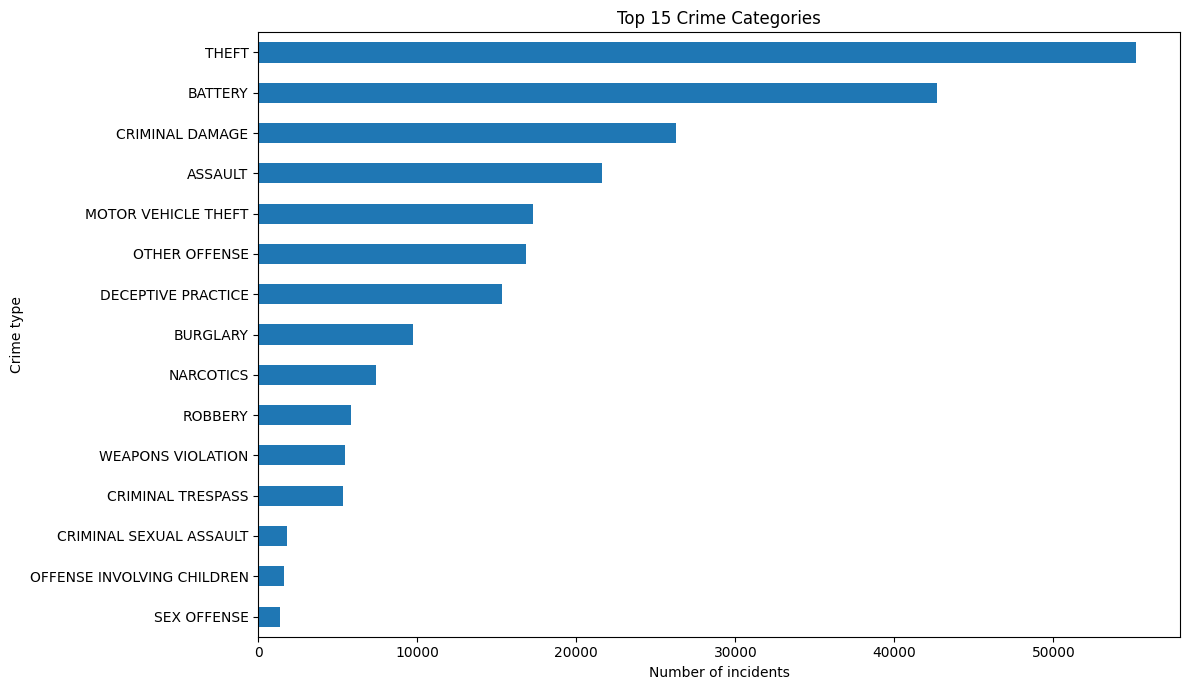

In [7]:
plt.figure(figsize=(12, 7))

crime_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Crime Categories")
plt.xlabel("Number of incidents")
plt.ylabel("Crime type")

plt.tight_layout()
plt.show()

In [8]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

df["Hour"] = df["Date"].dt.hour
df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["DayOfWeekNum"] = df["Date"].dt.dayofweek

df["IsWeekend"] = (
    df["DayOfWeekNum"].isin([5, 6])
).astype(int)

df["IsNight"] = (
    (df["Hour"] >= 20) |
    (df["Hour"] < 6)
).astype(int)

print("Date features created.")

Date features created.


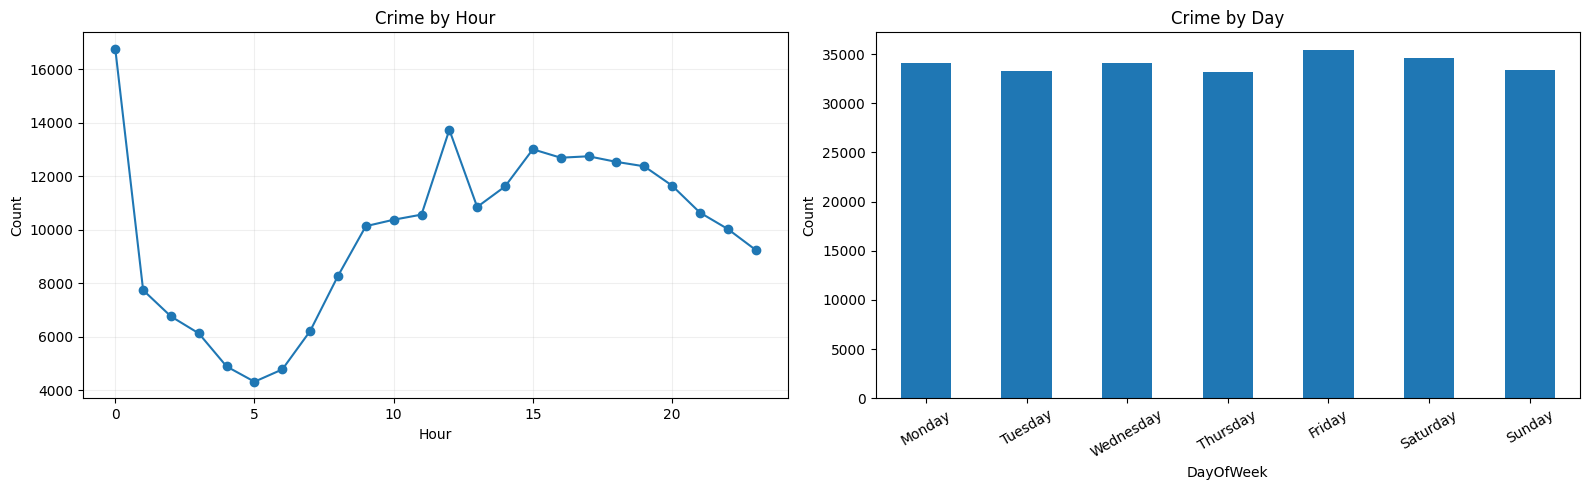

In [9]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5)
)

df["Hour"].value_counts().sort_index().plot(
    ax=axes[0],
    marker="o"
)

axes[0].set_title("Crime by Hour")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Count")
axes[0].grid(alpha=0.2)

day_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

df["DayOfWeek"] = df["Date"].dt.day_name()

df["DayOfWeek"].value_counts().reindex(
    day_names
).plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Crime by Day")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

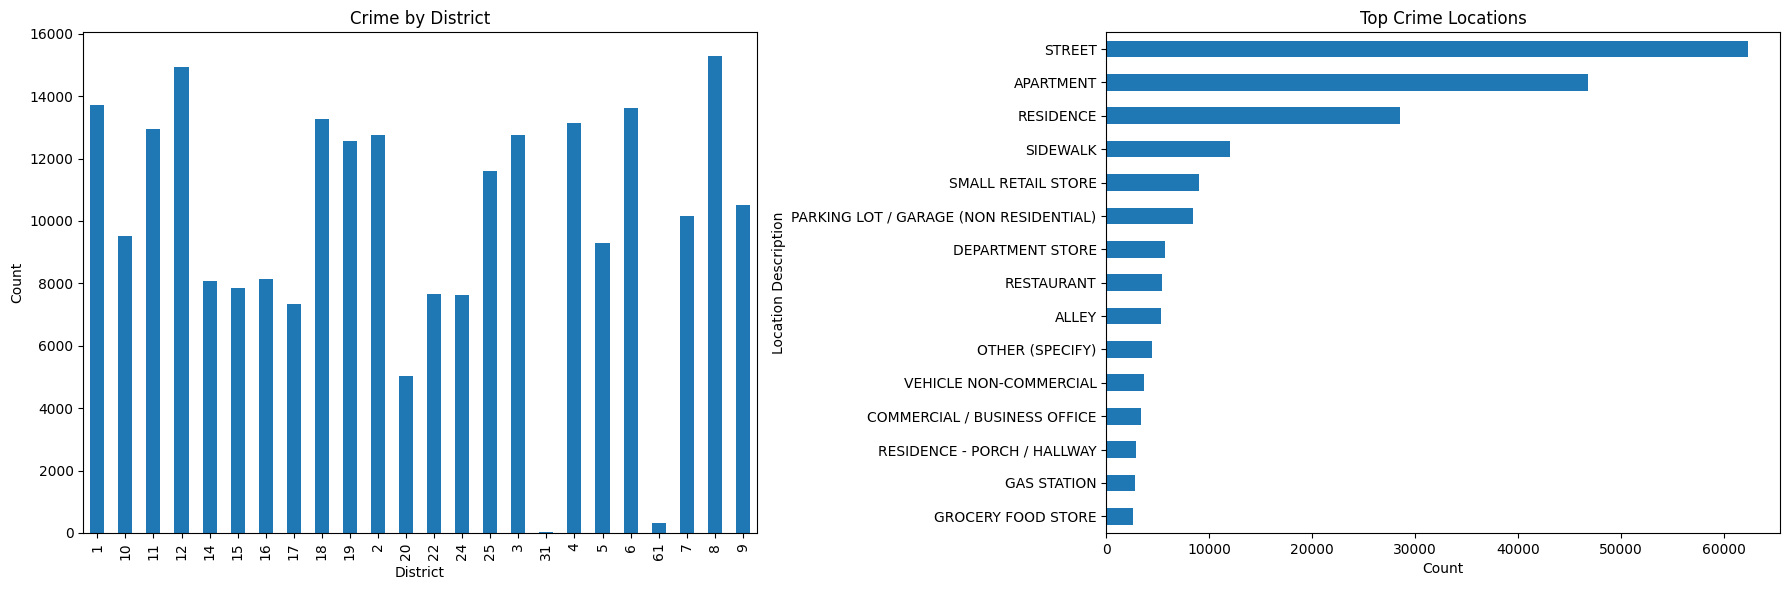

In [10]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 6)
)

df["District"].astype(str).value_counts().sort_index().plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Crime by District")
axes[0].set_xlabel("District")
axes[0].set_ylabel("Count")

df["Location Description"].value_counts().head(15).sort_values().plot(
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("Top Crime Locations")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()

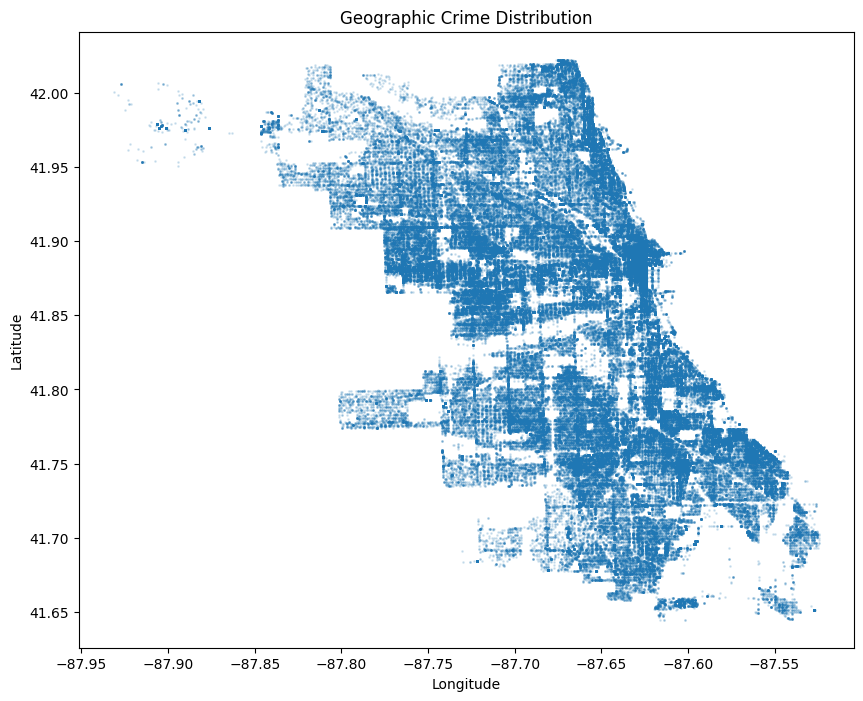

In [11]:
geo = df.dropna(
    subset=["Latitude", "Longitude"]
)

plt.figure(figsize=(10, 8))

plt.scatter(
    geo["Longitude"],
    geo["Latitude"],
    s=1,
    alpha=0.15
)

plt.title("Geographic Crime Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

In [12]:
FEATURES = [
    "Hour",
    "Day",
    "Month",
    "DayOfWeekNum",
    "IsWeekend",
    "IsNight",
    "District",
    "Community Area",
    "Location Description",
    "Latitude",
    "Longitude"
]

TARGET = "Primary Type"

model_df = df[
    FEATURES + [TARGET]
].copy()

CATEGORICAL_FEATURES = [
    "District",
    "Community Area",
    "Location Description"
]

NUMERIC_FEATURES = [
    "Hour",
    "Day",
    "Month",
    "DayOfWeekNum",
    "IsWeekend",
    "IsNight",
    "Latitude",
    "Longitude"
]

for col in CATEGORICAL_FEATURES:
    model_df[col] = (
        model_df[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

for col in NUMERIC_FEATURES:
    model_df[col] = pd.to_numeric(
        model_df[col],
        errors="coerce"
    )

model_df = model_df.dropna(
    subset=[
        "Hour",
        "Day",
        "Month",
        TARGET
    ]
)

for col in NUMERIC_FEATURES:
    model_df[col] = model_df[col].fillna(
        model_df[col].median()
    )

print("Final model dataset:", model_df.shape)

Final model dataset: (238106, 12)


In [13]:
model_df["Hour_sin"] = np.sin(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Hour_cos"] = np.cos(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Month_sin"] = np.sin(
    2 * np.pi * model_df["Month"] / 12
)

model_df["Month_cos"] = np.cos(
    2 * np.pi * model_df["Month"] / 12
)

model_df["Day_sin"] = np.sin(
    2 * np.pi * model_df["Day"] / 31
)

model_df["Day_cos"] = np.cos(
    2 * np.pi * model_df["Day"] / 31
)

FEATURES += [
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "Day_sin",
    "Day_cos"
]

print("Total features:", len(FEATURES))

Total features: 17


In [14]:
model_df["Hour_sin"] = np.sin(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Hour_cos"] = np.cos(
    2 * np.pi * model_df["Hour"] / 24
)

model_df["Month_sin"] = np.sin(
    2 * np.pi * model_df["Month"] / 12
)

model_df["Month_cos"] = np.cos(
    2 * np.pi * model_df["Month"] / 12
)

model_df["Day_sin"] = np.sin(
    2 * np.pi * model_df["Day"] / 31
)

model_df["Day_cos"] = np.cos(
    2 * np.pi * model_df["Day"] / 31
)

FEATURES += [
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "Day_sin",
    "Day_cos"
]

print("Total features:", len(FEATURES))

Total features: 23


In [17]:
# CELL 14 — Clean rare target classes + create stratified sample

from sklearn.model_selection import train_test_split

X = model_df[FEATURES].copy()
y = model_df[TARGET].copy()

# Check class frequencies
class_counts = y.value_counts()

print("Original number of classes:", len(class_counts))
print("\nClasses with fewer than 5 samples:")
display(class_counts[class_counts < 5])

# For a reliable train/test split, keep classes having at least 5 records.
# This prevents classes with 1–4 observations from breaking stratification.
MIN_CLASS_COUNT = 5

valid_classes = class_counts[
    class_counts >= MIN_CLASS_COUNT
].index

mask = y.isin(valid_classes)

X_clean = X.loc[mask].copy()
y_clean = y.loc[mask].copy()

print("\nAfter removing extremely rare classes:")
print("Rows:", len(y_clean))
print("Classes:", y_clean.nunique())

print("\nClass distribution:")
display(y_clean.value_counts())

Original number of classes: 31

Classes with fewer than 5 samples:


,count
Primary Type,
NON-CRIMINAL,3



After removing extremely rare classes:
Rows: 238103
Classes: 30

Class distribution:


,count
Primary Type,
THEFT,55198
BATTERY,42660
CRIMINAL DAMAGE,26249
ASSAULT,21599
MOTOR VEHICLE THEFT,17258
OTHER OFFENSE,16855
DECEPTIVE PRACTICE,15341
BURGLARY,9740
NARCOTICS,7419


In [18]:
# CELL 15 — Create balanced stratified experiment dataset

MAX_SAMPLE_SIZE = 100000

if len(X_clean) > MAX_SAMPLE_SIZE:

    X_sample, _, y_sample, _ = train_test_split(
        X_clean,
        y_clean,
        train_size=MAX_SAMPLE_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_clean
    )

else:

    X_sample = X_clean.copy()
    y_sample = y_clean.copy()

print("Experiment dataset:")
print("--------------------")
print("Rows:", len(X_sample))
print("Features:", X_sample.shape[1])
print("Classes:", y_sample.nunique())

print("\nMinimum class count:")
print(y_sample.value_counts().min())

print("\nClass distribution:")
display(
    y_sample.value_counts().to_frame("Count")
)

Experiment dataset:
--------------------
Rows: 100000
Features: 23
Classes: 30

Minimum class count:
4

Class distribution:


,Count
Primary Type,
THEFT,23182
BATTERY,17917
CRIMINAL DAMAGE,11024
ASSAULT,9071
MOTOR VEHICLE THEFT,7248
OTHER OFFENSE,7079
DECEPTIVE PRACTICE,6443
BURGLARY,4091
NARCOTICS,3116


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_sample
)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (80000, 23)
Testing : (20000, 23)


In [21]:
# ============================================================
# CELL 15 — STRATIFIED EXPERIMENT DATASET
# ============================================================

from sklearn.model_selection import train_test_split

MAX_SAMPLE_SIZE = 100000

if len(X_clean) > MAX_SAMPLE_SIZE:

    X_sample, _, y_sample, _ = train_test_split(
        X_clean,
        y_clean,
        train_size=MAX_SAMPLE_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_clean
    )

else:
    X_sample = X_clean.copy()
    y_sample = y_clean.copy()

print("====================================")
print("EXPERIMENT DATASET")
print("====================================")
print("Rows     :", len(X_sample))
print("Features :", X_sample.shape[1])
print("Classes  :", y_sample.nunique())

print("\nMinimum class frequency:")
print(y_sample.value_counts().min())

print("\nClass distribution:")
display(
    y_sample.value_counts().to_frame("Count")
)

EXPERIMENT DATASET
Rows     : 100000
Features : 23
Classes  : 30

Minimum class frequency:
4

Class distribution:


,Count
Primary Type,
THEFT,23182
BATTERY,17917
CRIMINAL DAMAGE,11024
ASSAULT,9071
MOTOR VEHICLE THEFT,7248
OTHER OFFENSE,7079
DECEPTIVE PRACTICE,6443
BURGLARY,4091
NARCOTICS,3116


In [22]:
# ============================================================
# CELL 16 — TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_sample
)

print("====================================")
print("TRAIN / TEST SPLIT")
print("====================================")

print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])
print("Number of features:", X_train.shape[1])

print("\nTraining class count:")
print(y_train.nunique())

print("\nTesting class count:")
print(y_test.nunique())

TRAIN / TEST SPLIT
Training samples : 80000
Testing samples  : 20000
Number of features: 23

Training class count:
30

Testing class count:
30


In [23]:
# ============================================================
# CELL 17 — DATA LEAKAGE CHECK
# ============================================================

print("Features used for ML:")
for feature in FEATURES:
    print("✓", feature)

print("\nTarget:")
print("🎯", TARGET)

leakage_columns = [
    "ID",
    "Case Number",
    "IUCR",
    "Description",
    "FBI Code",
    "Updated On",
    "Location",
    "Arrest",
    "Domestic"
]

used_leakage = [
    col for col in leakage_columns
    if col in FEATURES
]

print("\nLeakage-prone columns used:")
print(used_leakage)

if len(used_leakage) == 0:
    print("\n✅ No known target-leakage columns are being used.")
else:
    print("\n⚠️ Review these columns.")

Features used for ML:
✓ Hour
✓ Day
✓ Month
✓ DayOfWeekNum
✓ IsWeekend
✓ IsNight
✓ District
✓ Community Area
✓ Location Description
✓ Latitude
✓ Longitude
✓ Hour_sin
✓ Hour_cos
✓ Month_sin
✓ Month_cos
✓ Day_sin
✓ Day_cos
✓ Hour_sin
✓ Hour_cos
✓ Month_sin
✓ Month_cos
✓ Day_sin
✓ Day_cos

Target:
🎯 Primary Type

Leakage-prone columns used:
[]

✅ No known target-leakage columns are being used.


In [24]:
# ============================================================
# CELL 18 — MODEL EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(model_name, y_true, y_pred):

    metrics = {
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1_Weighted": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    return metrics


results = []

print("✅ Evaluation function ready")

✅ Evaluation function ready


In [28]:
# ============================================================
# CELL 18.5 — FIX DUPLICATE FEATURE COLUMNS
# ============================================================

print("Checking feature columns...")

# Show duplicate columns
duplicate_columns = X_train.columns[
    X_train.columns.duplicated()
].tolist()

print("Duplicate columns found:", duplicate_columns)

# Remove duplicate columns while keeping the FIRST occurrence
X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
X_test = X_test.loc[:, ~X_test.columns.duplicated()].copy()

# Make sure train and test have exactly the same columns
X_test = X_test[X_train.columns]

# Update FEATURES
FEATURES = X_train.columns.tolist()

print("\n✅ Duplicate columns removed.")
print("Final number of features:", len(FEATURES))

print("\nFinal features:")
print(FEATURES)

print("\nTrain shape:", X_train.shape)
print("Test shape :", X_test.shape)

Checking feature columns...
Duplicate columns found: ['Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'Day_sin', 'Day_cos']

✅ Duplicate columns removed.
Final number of features: 17

Final features:
['Hour', 'Day', 'Month', 'DayOfWeekNum', 'IsWeekend', 'IsNight', 'District', 'Community Area', 'Location Description', 'Latitude', 'Longitude', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'Day_sin', 'Day_cos']

Train shape: (80000, 17)
Test shape : (20000, 17)


In [29]:
# ============================================================
# CELL 19 — DECISION TREE BASELINE
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import OrdinalEncoder
import pandas as pd

print("Training Decision Tree...")

# ------------------------------------------------------------
# 1. Copy datasets
# ------------------------------------------------------------

X_train_dt = X_train.copy()
X_test_dt = X_test.copy()

# ------------------------------------------------------------
# 2. Identify categorical columns
# ------------------------------------------------------------

dt_cat_cols = [
    col for col in CATEGORICAL_FEATURES
    if col in X_train_dt.columns
]

dt_num_cols = [
    col for col in X_train_dt.columns
    if col not in dt_cat_cols
]

print("Categorical columns:", dt_cat_cols)
print("Numerical columns:", dt_num_cols)

# ------------------------------------------------------------
# 3. Encode categorical features
# ------------------------------------------------------------

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_cat = encoder.fit_transform(
    X_train_dt[dt_cat_cols]
)

X_test_cat = encoder.transform(
    X_test_dt[dt_cat_cols]
)

X_train_cat = pd.DataFrame(
    X_train_cat,
    columns=dt_cat_cols,
    index=X_train_dt.index
)

X_test_cat = pd.DataFrame(
    X_test_cat,
    columns=dt_cat_cols,
    index=X_test_dt.index
)

# ------------------------------------------------------------
# 4. Numerical features
# ------------------------------------------------------------

X_train_num = X_train_dt[dt_num_cols].copy()
X_test_num = X_test_dt[dt_num_cols].copy()

X_train_num = X_train_num.apply(
    pd.to_numeric,
    errors="coerce"
).fillna(0)

X_test_num = X_test_num.apply(
    pd.to_numeric,
    errors="coerce"
).fillna(0)

# ------------------------------------------------------------
# 5. Combine
# ------------------------------------------------------------

X_train_dt_final = pd.concat(
    [X_train_num, X_train_cat],
    axis=1
)

X_test_dt_final = pd.concat(
    [X_test_num, X_test_cat],
    axis=1
)

# EXACT SAME COLUMN ORDER
X_test_dt_final = X_test_dt_final[
    X_train_dt_final.columns
]

print("\nFinal training shape:", X_train_dt_final.shape)
print("Final testing shape :", X_test_dt_final.shape)

# ------------------------------------------------------------
# 6. Train
# ------------------------------------------------------------

dt_classifier = DecisionTreeClassifier(
    max_depth=18,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

dt_classifier.fit(
    X_train_dt_final,
    y_train
)

# ------------------------------------------------------------
# 7. Prediction
# ------------------------------------------------------------

dt_pred = dt_classifier.predict(
    X_test_dt_final
)

# ------------------------------------------------------------
# 8. Evaluation
# ------------------------------------------------------------

dt_results = evaluate_model(
    "Decision Tree",
    y_test,
    dt_pred
)

results.append(dt_results)

print("\n" + "=" * 50)
print("✅ DECISION TREE COMPLETED")
print("=" * 50)

print("Accuracy :", round(dt_results["Accuracy"], 4))
print("Precision:", round(dt_results["Precision"], 4))
print("Recall   :", round(dt_results["Recall"], 4))
print("F1 Score :", round(dt_results["F1_Weighted"], 4))
print("Macro F1 :", round(dt_results["F1_Macro"], 4))

Training Decision Tree...
Categorical columns: ['District', 'Community Area', 'Location Description']
Numerical columns: ['Hour', 'Day', 'Month', 'DayOfWeekNum', 'IsWeekend', 'IsNight', 'Latitude', 'Longitude', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'Day_sin', 'Day_cos']

Final training shape: (80000, 17)
Final testing shape : (20000, 17)

✅ DECISION TREE COMPLETED
Accuracy : 0.1394
Precision: 0.3014
Recall   : 0.1394
F1 Score : 0.1574
Macro F1 : 0.0862


In [30]:
# ============================================================
# SANITY CHECK — TARGET DISTRIBUTION
# ============================================================

print("Number of crime classes:", y_sample.nunique())

print("\nCrime class distribution:")
display(
    y_sample.value_counts()
    .to_frame("Count")
)

print("\nClass percentages:")
display(
    (y_sample.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

# Majority-class baseline
majority_class = y_train.value_counts().idxmax()
majority_accuracy = (y_test == majority_class).mean()

print("\n" + "=" * 50)
print("BASELINE CHECK")
print("=" * 50)

print("Majority class:", majority_class)
print("Majority baseline accuracy:",
      round(majority_accuracy, 4))
print("Decision Tree accuracy:",
      round(dt_results["Accuracy"], 4))

Number of crime classes: 30

Crime class distribution:


,Count
Primary Type,
THEFT,23182
BATTERY,17917
CRIMINAL DAMAGE,11024
ASSAULT,9071
MOTOR VEHICLE THEFT,7248
OTHER OFFENSE,7079
DECEPTIVE PRACTICE,6443
BURGLARY,4091
NARCOTICS,3116



Class percentages:


,Percentage
Primary Type,
THEFT,23.18
BATTERY,17.92
CRIMINAL DAMAGE,11.02
ASSAULT,9.07
MOTOR VEHICLE THEFT,7.25
OTHER OFFENSE,7.08
DECEPTIVE PRACTICE,6.44
BURGLARY,4.09
NARCOTICS,3.12



BASELINE CHECK
Majority class: THEFT
Majority baseline accuracy: 0.2318
Decision Tree accuracy: 0.1394


In [31]:
print("Number of classes:", y_sample.nunique())

print("\nTop 15 crime types:")
display(
    y_sample.value_counts()
    .head(15)
    .to_frame("Count")
)

print("\nTotal classes:")
print(sorted(y_sample.unique()))

Number of classes: 30

Top 15 crime types:


,Count
Primary Type,
THEFT,23182
BATTERY,17917
CRIMINAL DAMAGE,11024
ASSAULT,9071
MOTOR VEHICLE THEFT,7248
OTHER OFFENSE,7079
DECEPTIVE PRACTICE,6443
BURGLARY,4091
NARCOTICS,3116



Total classes:
['ARSON', 'ASSAULT', 'BATTERY', 'BURGLARY', 'CONCEALED CARRY LICENSE VIOLATION', 'CRIMINAL DAMAGE', 'CRIMINAL SEXUAL ASSAULT', 'CRIMINAL TRESPASS', 'DECEPTIVE PRACTICE', 'GAMBLING', 'HOMICIDE', 'HUMAN TRAFFICKING', 'INTERFERENCE WITH PUBLIC OFFICER', 'INTIMIDATION', 'KIDNAPPING', 'LIQUOR LAW VIOLATION', 'MOTOR VEHICLE THEFT', 'NARCOTICS', 'OBSCENITY', 'OFFENSE INVOLVING CHILDREN', 'OTHER NARCOTIC VIOLATION', 'OTHER OFFENSE', 'PROSTITUTION', 'PUBLIC INDECENCY', 'PUBLIC PEACE VIOLATION', 'ROBBERY', 'SEX OFFENSE', 'STALKING', 'THEFT', 'WEAPONS VIOLATION']


In [33]:
# ============================================================
# CELL 21 — CATBOOST PREPARATION
# ============================================================

from catboost import CatBoostClassifier

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# Clean categorical columns
for col in CATEGORICAL_FEATURES:
    X_train_cb[col] = (
        X_train_cb[col]
        .fillna("Unknown")
        .astype(str)
    )

    X_test_cb[col] = (
        X_test_cb[col]
        .fillna("Unknown")
        .astype(str)
    )

cat_indices = [
    X_train_cb.columns.get_loc(col)
    for col in CATEGORICAL_FEATURES
]

print("Categorical features:")
print(CATEGORICAL_FEATURES)

print("\nCategorical indices:")
print(cat_indices)

print("\nTrain shape:", X_train_cb.shape)
print("Test shape :", X_test_cb.shape)

Categorical features:
['District', 'Community Area', 'Location Description']

Categorical indices:
[6, 7, 8]

Train shape: (80000, 17)
Test shape : (20000, 17)


In [35]:
# ============================================================
# CELL 22 — FAST CATBOOST
# ============================================================

print("🔥 Training FAST CatBoost...")
print("=" * 60)

from catboost import CatBoostClassifier

# ------------------------------------------------------------
# USE A SMALLER TRAINING SET FOR FAST EXPERIMENTATION
# ------------------------------------------------------------

CAT_TRAIN_SIZE = 40000

if len(X_train_cb) > CAT_TRAIN_SIZE:

    X_cb_train, _, y_cb_train, _ = train_test_split(
        X_train_cb,
        y_train,
        train_size=CAT_TRAIN_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_train
    )

else:
    X_cb_train = X_train_cb.copy()
    y_cb_train = y_train.copy()

print("CatBoost training rows:", len(X_cb_train))
print("Validation rows:", len(X_test_cb))
print("Number of classes:", y_cb_train.nunique())

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

cat_model = CatBoostClassifier(

    iterations=120,

    depth=6,

    learning_rate=0.12,

    loss_function="MultiClass",

    eval_metric="Accuracy",

    l2_leaf_reg=5,

    random_strength=1,

    random_seed=RANDOM_STATE,

    thread_count=-1,

    early_stopping_rounds=20,

    verbose=20,

    allow_writing_files=False
)

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

cat_model.fit(

    X_cb_train,
    y_cb_train,

    cat_features=cat_indices,

    eval_set=(X_test_cb, y_test),

    verbose=20
)

print("\n" + "=" * 60)
print("✅ FAST CATBOOST TRAINING COMPLETED")
print("=" * 60)

print(
    "Best iteration:",
    cat_model.get_best_iteration()
)

🔥 Training FAST CatBoost...
CatBoost training rows: 40000
Validation rows: 20000
Number of classes: 30
0:	learn: 0.2495750	test: 0.2489500	best: 0.2489500 (0)	total: 8.87s	remaining: 17m 35s
20:	learn: 0.3203000	test: 0.3178000	best: 0.3178000 (20)	total: 1m 32s	remaining: 7m 16s
40:	learn: 0.3294250	test: 0.3248500	best: 0.3252500 (38)	total: 2m 53s	remaining: 5m 34s
60:	learn: 0.3346250	test: 0.3293500	best: 0.3293500 (60)	total: 4m 16s	remaining: 4m 7s
80:	learn: 0.3392250	test: 0.3301000	best: 0.3303000 (72)	total: 5m 38s	remaining: 2m 43s
100:	learn: 0.3436250	test: 0.3315500	best: 0.3319000 (98)	total: 7m	remaining: 1m 19s
119:	learn: 0.3473750	test: 0.3327000	best: 0.3336500 (117)	total: 8m 18s	remaining: 0us

bestTest = 0.33365
bestIteration = 117

Shrink model to first 118 iterations.

✅ FAST CATBOOST TRAINING COMPLETED
Best iteration: 117


In [36]:
# ============================================================
# CURRENT CATBOOST — EVALUATE
# ============================================================

cat_pred = cat_model.predict(X_test_cb).ravel()

cat_fast_results = evaluate_model(
    "CatBoost - Fast",
    y_test,
    cat_pred
)

print("\n" + "=" * 60)
print("🔥 CURRENT CATBOOST RESULTS")
print("=" * 60)

print(f"Accuracy    : {cat_fast_results['Accuracy']:.4f}")
print(f"Precision   : {cat_fast_results['Precision']:.4f}")
print(f"Recall      : {cat_fast_results['Recall']:.4f}")
print(f"Weighted F1 : {cat_fast_results['F1_Weighted']:.4f}")
print(f"Macro F1    : {cat_fast_results['F1_Macro']:.4f}")


🔥 CURRENT CATBOOST RESULTS
Accuracy    : 0.3337
Precision   : 0.2998
Recall      : 0.3337
Weighted F1 : 0.2663
Macro F1    : 0.0847


In [37]:
# ============================================================
# CELL 19.5 — FINAL FEATURE CLEANUP
# ============================================================

import numpy as np
import pandas as pd

# Remove duplicate columns
X_train = X_train.loc[:, ~X_train.columns.duplicated()].copy()
X_test = X_test.loc[:, ~X_test.columns.duplicated()].copy()

# Force identical columns/order
X_test = X_test[X_train.columns]

FEATURES = X_train.columns.tolist()

# Recalculate categorical columns
CATEGORICAL_FEATURES = [
    col for col in [
        "District",
        "Community Area",
        "Location Description"
    ]
    if col in FEATURES
]

NUMERICAL_FEATURES = [
    col for col in FEATURES
    if col not in CATEGORICAL_FEATURES
]

print("=" * 60)
print("FINAL FEATURE CHECK")
print("=" * 60)

print("Total features:", len(FEATURES))
print("Categorical:", CATEGORICAL_FEATURES)
print("Numerical:", NUMERICAL_FEATURES)

print("\nDuplicate columns:")
print(X_train.columns[X_train.columns.duplicated()].tolist())

print("\nTrain:", X_train.shape)
print("Test :", X_test.shape)

FINAL FEATURE CHECK
Total features: 17
Categorical: ['District', 'Community Area', 'Location Description']
Numerical: ['Hour', 'Day', 'Month', 'DayOfWeekNum', 'IsWeekend', 'IsNight', 'Latitude', 'Longitude', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'Day_sin', 'Day_cos']

Duplicate columns:
[]

Train: (80000, 17)
Test : (20000, 17)


In [38]:
# ============================================================
# REBUILD CATBOOST DATA AFTER FEATURE CLEANUP
# ============================================================

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in CATEGORICAL_FEATURES:
    X_train_cb[col] = (
        X_train_cb[col]
        .fillna("Unknown")
        .astype(str)
    )

    X_test_cb[col] = (
        X_test_cb[col]
        .fillna("Unknown")
        .astype(str)
    )

cat_indices = [
    X_train_cb.columns.get_loc(col)
    for col in CATEGORICAL_FEATURES
]

print("CatBoost train:", X_train_cb.shape)
print("CatBoost test :", X_test_cb.shape)
print("Categorical indices:", cat_indices)

CatBoost train: (80000, 17)
CatBoost test : (20000, 17)
Categorical indices: [6, 7, 8]


In [40]:
# ============================================================
# CELL 20 — FAST HYPERPARAMETER TUNING DATASET
# ============================================================

from sklearn.model_selection import train_test_split

TUNE_SIZE = 40000

if len(X_train) > TUNE_SIZE:

    X_tune, _, y_tune, _ = train_test_split(
        X_train,
        y_train,
        train_size=TUNE_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_train
    )

else:

    X_tune = X_train.copy()
    y_tune = y_train.copy()

print("Tuning rows:", len(X_tune))
print("Tuning classes:", y_tune.nunique())

print("\nTuning distribution:")
display(
    y_tune.value_counts().head(10).to_frame("Count")
)

Tuning rows: 40000
Tuning classes: 30

Tuning distribution:


,Count
Primary Type,
THEFT,9272
BATTERY,7167
CRIMINAL DAMAGE,4410
ASSAULT,3629
MOTOR VEHICLE THEFT,2899
OTHER OFFENSE,2831
DECEPTIVE PRACTICE,2577
BURGLARY,1637
NARCOTICS,1247


In [41]:
# ============================================================
# CELL 21 — ONE-HOT ENCODING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=5
            ),
            CATEGORICAL_FEATURES
        )
    ],
    remainder="passthrough"
)

print("Fitting encoder...")

X_tune_encoded = preprocessor.fit_transform(X_tune)

X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_tune_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

Fitting encoder...
Encoded training shape: (40000, 201)
Encoded test shape: (20000, 201)


In [42]:
# ============================================================
# CELL 22 — DECISION TREE BASELINE
# ============================================================

from sklearn.tree import DecisionTreeClassifier

print("Training Decision Tree baseline...")

dt_baseline = DecisionTreeClassifier(
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

dt_baseline.fit(
    X_tune_encoded,
    y_tune
)

dt_base_pred = dt_baseline.predict(X_test_encoded)

dt_base_results = evaluate_model(
    "Decision Tree - Baseline",
    y_test,
    dt_base_pred
)

print(dt_base_results)

Training Decision Tree baseline...
{'Model': 'Decision Tree - Baseline', 'Accuracy': 0.078, 'Precision': 0.25690509613187296, 'Recall': 0.078, 'F1_Weighted': 0.058540158783871664, 'F1_Macro': 0.04957316762090686}


In [43]:
# ============================================================
# CELL 23 — DECISION TREE HYPERTUNING
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

dt_param_grid = {
    "max_depth": [8, 12, 16, 20, 25, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced", None]
}

dt_search = RandomizedSearchCV(
    DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    param_distributions=dt_param_grid,
    n_iter=8,
    scoring="f1_weighted",
    cv=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

print("🔥 Tuning Decision Tree...")

dt_search.fit(
    X_tune_encoded,
    y_tune
)

dt_tuned = dt_search.best_estimator_

print("\nBest parameters:")
print(dt_search.best_params_)

print("\nBest CV F1:")
print(round(dt_search.best_score_, 4))

dt_tuned_pred = dt_tuned.predict(X_test_encoded)

dt_tuned_results = evaluate_model(
    "Decision Tree - Tuned",
    y_test,
    dt_tuned_pred
)

print("\nTest Results:")
print(dt_tuned_results)

🔥 Tuning Decision Tree...
Fitting 2 folds for each of 8 candidates, totalling 16 fits

Best parameters:
{'min_samples_split': 2, 'min_samples_leaf': 10, 'max_depth': 25, 'criterion': 'gini', 'class_weight': None}

Best CV F1:
0.2513

Test Results:
{'Model': 'Decision Tree - Tuned', 'Accuracy': 0.27155, 'Precision': 0.24204231328541279, 'Recall': 0.27155, 'F1_Weighted': 0.24936473026340317, 'F1_Macro': 0.08894275814030835}


In [44]:
# ============================================================
# CELL 24 — RANDOM FOREST BASELINE
# ============================================================

from sklearn.ensemble import RandomForestClassifier

print("🌲 Training Random Forest baseline...")

rf_baseline = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

rf_baseline.fit(
    X_tune_encoded,
    y_tune
)

rf_base_pred = rf_baseline.predict(
    X_test_encoded
)

rf_base_results = evaluate_model(
    "Random Forest - Baseline",
    y_test,
    rf_base_pred
)

print("\nRandom Forest baseline:")
print(rf_base_results)

🌲 Training Random Forest baseline...

Random Forest baseline:
{'Model': 'Random Forest - Baseline', 'Accuracy': 0.25255, 'Precision': 0.29058768626105624, 'Recall': 0.25255, 'F1_Weighted': 0.24707641729885027, 'F1_Macro': 0.11097516097941769}


In [45]:
# ============================================================
# CELL 25 — RANDOM FOREST HYPERTUNING
# ============================================================

rf_param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [12, 16, 20, 24],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    param_distributions=rf_param_grid,
    n_iter=8,
    scoring="f1_weighted",
    cv=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

print("🔥 Tuning Random Forest...")

rf_search.fit(
    X_tune_encoded,
    y_tune
)

rf_tuned = rf_search.best_estimator_

print("\nBest parameters:")
print(rf_search.best_params_)

print("\nBest CV F1:")
print(round(rf_search.best_score_, 4))

rf_tuned_pred = rf_tuned.predict(
    X_test_encoded
)

rf_tuned_results = evaluate_model(
    "Random Forest - Tuned",
    y_test,
    rf_tuned_pred
)

print("\nTest Results:")
print(rf_tuned_results)

🔥 Tuning Random Forest...
Fitting 2 folds for each of 8 candidates, totalling 16 fits

Best parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 24, 'class_weight': 'balanced_subsample'}

Best CV F1:
0.251

Test Results:
{'Model': 'Random Forest - Tuned', 'Accuracy': 0.26755, 'Precision': 0.2911280382960179, 'Recall': 0.26755, 'F1_Weighted': 0.2591571001912745, 'F1_Macro': 0.11756905219629196}


In [47]:
# ============================================================
# CELL 26 — XGBOOST BASELINE (FIXED FOR STRING TARGET)
# ============================================================

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

print("⚡ Training XGBoost baseline...")
print("=" * 60)

# ------------------------------------------------------------
# 1. Encode target labels ONLY for XGBoost
# ------------------------------------------------------------

xgb_label_encoder = LabelEncoder()

# Fit on the complete training target so all classes are known
xgb_label_encoder.fit(y_train)

# Convert string labels → integers
y_tune_xgb = xgb_label_encoder.transform(y_tune)

print("Number of classes:", len(xgb_label_encoder.classes_))

print("\nExample encoding:")
for i in range(min(10, len(xgb_label_encoder.classes_))):
    print(
        f"{xgb_label_encoder.classes_[i]} → {i}"
    )

# ------------------------------------------------------------
# 2. XGBoost model
# ------------------------------------------------------------

xgb_baseline = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.10,
    subsample=0.85,
    colsample_bytree=0.85,

    objective="multi:softprob",
    num_class=len(xgb_label_encoder.classes_),
    eval_metric="mlogloss",

    tree_method="hist",

    n_jobs=-1,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# 3. Train
# ------------------------------------------------------------

xgb_baseline.fit(
    X_tune_encoded,
    y_tune_xgb
)

# ------------------------------------------------------------
# 4. Predict
# ------------------------------------------------------------

xgb_pred_encoded = xgb_baseline.predict(
    X_test_encoded
)

# Convert integer predictions back to crime names
xgb_base_pred = xgb_label_encoder.inverse_transform(
    xgb_pred_encoded.astype(int)
)

# ------------------------------------------------------------
# 5. Evaluate using ORIGINAL crime labels
# ------------------------------------------------------------

xgb_base_results = evaluate_model(
    "XGBoost - Baseline",
    y_test,
    xgb_base_pred
)

print("\n" + "=" * 60)
print("⚡ XGBOOST BASELINE RESULTS")
print("=" * 60)

print(
    f"Accuracy    : {xgb_base_results['Accuracy']:.4f}"
)

print(
    f"Precision   : {xgb_base_results['Precision']:.4f}"
)

print(
    f"Recall      : {xgb_base_results['Recall']:.4f}"
)

print(
    f"Weighted F1 : {xgb_base_results['F1_Weighted']:.4f}"
)

print(
    f"Macro F1    : {xgb_base_results['F1_Macro']:.4f}"
)

⚡ Training XGBoost baseline...
Number of classes: 30

Example encoding:
ARSON → 0
ASSAULT → 1
BATTERY → 2
BURGLARY → 3
CONCEALED CARRY LICENSE VIOLATION → 4
CRIMINAL DAMAGE → 5
CRIMINAL SEXUAL ASSAULT → 6
CRIMINAL TRESPASS → 7
DECEPTIVE PRACTICE → 8
GAMBLING → 9

⚡ XGBOOST BASELINE RESULTS
Accuracy    : 0.3373
Precision   : 0.3041
Recall      : 0.3373
Weighted F1 : 0.2853
Macro F1    : 0.1205


In [50]:
# ============================================================
# CELL 27 — XGBOOST HYPERPARAMETER TUNING — ROBUST VERSION
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score
from xgboost import XGBClassifier

print("🔥 XGBoost hyperparameter tuning")
print("=" * 65)

# ------------------------------------------------------------
# 1. Check class frequencies
# ------------------------------------------------------------

xgb_counts = y_tune.value_counts()

print("Original tuning classes:", len(xgb_counts))
print("Smallest class count:", xgb_counts.min())

# Classes with at least 2 samples
valid_xgb_classes = xgb_counts[
    xgb_counts >= 2
].index

# Keep only rows belonging to valid classes
xgb_mask = y_tune.isin(valid_xgb_classes)

X_tune_xgb = X_tune_encoded[xgb_mask.values]
y_tune_xgb_labels = y_tune.loc[xgb_mask]

print("\nAfter removing classes with <2 samples:")
print("Rows:", X_tune_xgb.shape[0])
print("Classes:", y_tune_xgb_labels.nunique())
print(
    "Smallest class count:",
    y_tune_xgb_labels.value_counts().min()
)

# ------------------------------------------------------------
# 2. Encode target AGAIN so labels are 0...N-1
# ------------------------------------------------------------

xgb_tuning_encoder = LabelEncoder()

y_tune_xgb = xgb_tuning_encoder.fit_transform(
    y_tune_xgb_labels
)

NUM_XGB_CLASSES = len(
    xgb_tuning_encoder.classes_
)

print("\nXGBoost classes:", NUM_XGB_CLASSES)

# ------------------------------------------------------------
# 3. Stratified validation split
# ------------------------------------------------------------

X_xgb_train, X_xgb_val, y_xgb_train, y_xgb_val = train_test_split(
    X_tune_xgb,
    y_tune_xgb,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_tune_xgb
)

print("\nTraining rows :", X_xgb_train.shape[0])
print("Validation rows:", X_xgb_val.shape[0])

# ------------------------------------------------------------
# 4. Hyperparameter configurations
# ------------------------------------------------------------

xgb_configs = [

    {
        "n_estimators": 100,
        "max_depth": 5,
        "learning_rate": 0.10,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "min_child_weight": 1
    },

    {
        "n_estimators": 150,
        "max_depth": 5,
        "learning_rate": 0.08,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "min_child_weight": 1
    },

    {
        "n_estimators": 150,
        "max_depth": 6,
        "learning_rate": 0.08,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "min_child_weight": 3
    },

    {
        "n_estimators": 150,
        "max_depth": 7,
        "learning_rate": 0.05,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "min_child_weight": 3
    },

    {
        "n_estimators": 200,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "min_child_weight": 5
    }
]

# ------------------------------------------------------------
# 5. Test configurations
# ------------------------------------------------------------

xgb_tuning_results = []

for i, params in enumerate(xgb_configs, 1):

    print("\n" + "-" * 65)
    print(f"Configuration {i}/{len(xgb_configs)}")
    print(params)

    model = XGBClassifier(
        **params,

        objective="multi:softprob",

        num_class=NUM_XGB_CLASSES,

        eval_metric="mlogloss",

        tree_method="hist",

        n_jobs=-1,

        random_state=RANDOM_STATE
    )

    model.fit(
        X_xgb_train,
        y_xgb_train
    )

    val_pred = model.predict(
        X_xgb_val
    )

    val_f1 = f1_score(
        y_xgb_val,
        val_pred,
        average="weighted",
        zero_division=0
    )

    print(
        f"Validation Weighted F1: {val_f1:.4f}"
    )

    xgb_tuning_results.append({
        "params": params,
        "val_f1": val_f1
    })

# ------------------------------------------------------------
# 6. Select best configuration
# ------------------------------------------------------------

best_xgb_config = max(
    xgb_tuning_results,
    key=lambda x: x["val_f1"]
)

print("\n" + "=" * 65)
print("🏆 BEST XGBOOST CONFIGURATION")
print("=" * 65)

print(best_xgb_config["params"])

print(
    "\nValidation Weighted F1:",
    round(best_xgb_config["val_f1"], 4)
)

# ------------------------------------------------------------
# 7. Train best XGBoost on complete safe tuning dataset
# ------------------------------------------------------------

print("\n🔥 Training best XGBoost...")

xgb_tuned = XGBClassifier(
    **best_xgb_config["params"],

    objective="multi:softprob",

    num_class=NUM_XGB_CLASSES,

    eval_metric="mlogloss",

    tree_method="hist",

    n_jobs=-1,

    random_state=RANDOM_STATE
)

xgb_tuned.fit(
    X_tune_xgb,
    y_tune_xgb
)

print("✅ Best XGBoost trained!")

🔥 XGBoost hyperparameter tuning
Original tuning classes: 30
Smallest class count: 1

After removing classes with <2 samples:
Rows: 39998
Classes: 28
Smallest class count: 2

XGBoost classes: 28

Training rows : 31998
Validation rows: 8000

-----------------------------------------------------------------
Configuration 1/5
{'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.1, 'subsample': 0.85, 'colsample_bytree': 0.85, 'min_child_weight': 1}
Validation Weighted F1: 0.2760

-----------------------------------------------------------------
Configuration 2/5
{'n_estimators': 150, 'max_depth': 5, 'learning_rate': 0.08, 'subsample': 0.85, 'colsample_bytree': 0.85, 'min_child_weight': 1}
Validation Weighted F1: 0.2765

-----------------------------------------------------------------
Configuration 3/5
{'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.08, 'subsample': 0.85, 'colsample_bytree': 0.85, 'min_child_weight': 3}
Validation Weighted F1: 0.2791

--------------------------

In [51]:
# ============================================================
# CELL 28 — XGBOOST FINAL EVALUATION
# ============================================================

# Classes that XGBoost was trained on
xgb_classes = set(
    xgb_tuning_encoder.classes_
)

# Keep only test samples whose class exists in XGBoost
xgb_test_mask = y_test.isin(xgb_classes)

X_test_xgb_final = X_test_encoded[xgb_test_mask.values]
y_test_xgb_labels = y_test.loc[xgb_test_mask]

# Predict
xgb_final_encoded = xgb_tuned.predict(
    X_test_xgb_final
)

# Convert integer labels back to crime names
xgb_final_pred = xgb_tuning_encoder.inverse_transform(
    xgb_final_encoded.astype(int)
)

# Evaluate
xgb_final_results = evaluate_model(
    "XGBoost - Tuned",
    y_test_xgb_labels,
    xgb_final_pred
)

print("=" * 60)
print("⚡ XGBOOST FINAL TEST RESULTS")
print("=" * 60)

for key, value in xgb_final_results.items():
    if key != "Model":
        print(f"{key:15s}: {value:.4f}")

print("\nTest samples used:", len(y_test_xgb_labels))
print("Classes evaluated:", y_test_xgb_labels.nunique())

⚡ XGBOOST FINAL TEST RESULTS
Accuracy       : 0.3362
Precision      : 0.2953
Recall         : 0.3362
F1_Weighted    : 0.2762
F1_Macro       : 0.1120

Test samples used: 19998
Classes evaluated: 28


In [52]:
# ============================================================
# CELL 29 — RANDOM FOREST FINAL EVALUATION
# ============================================================

rf_tuned_pred = rf_tuned.predict(
    X_test_encoded
)

rf_final_results = evaluate_model(
    "Random Forest - Tuned",
    y_test,
    rf_tuned_pred
)

print("=" * 60)
print("🌲 RANDOM FOREST FINAL RESULTS")
print("=" * 60)

for key, value in rf_final_results.items():
    if key != "Model":
        print(f"{key:15s}: {value:.4f}")

🌲 RANDOM FOREST FINAL RESULTS
Accuracy       : 0.2676
Precision      : 0.2911
Recall         : 0.2676
F1_Weighted    : 0.2592
F1_Macro       : 0.1176


In [53]:
# ============================================================
# CELL 30 — CATBOOST FINAL EVALUATION
# ============================================================

cat_final_pred = cat_model.predict(
    X_test_cb
).ravel()

cat_final_results = evaluate_model(
    "CatBoost",
    y_test,
    cat_final_pred
)

print("=" * 60)
print("🐱 CATBOOST FINAL RESULTS")
print("=" * 60)

for key, value in cat_final_results.items():
    if key != "Model":
        print(f"{key:15s}: {value:.4f}")

🐱 CATBOOST FINAL RESULTS
Accuracy       : 0.3337
Precision      : 0.2998
Recall         : 0.3337
F1_Weighted    : 0.2663
F1_Macro       : 0.0847


In [54]:
# ============================================================
# CELL 31 — COMPLETE MODEL COMPARISON
# ============================================================

comparison_results = pd.DataFrame([
    dt_base_results,
    dt_tuned_results,
    rf_base_results,
    rf_tuned_results,
    xgb_base_results,
    xgb_final_results,
    cat_fast_results,
    cat_final_results
])

comparison_results = comparison_results.sort_values(
    by="F1_Weighted",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("🏆 CRIMEGUARD — COMPLETE MODEL COMPARISON")
print("=" * 80)

display(
    comparison_results.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1_Weighted": "{:.2%}",
        "F1_Macro": "{:.2%}"
    })
)

🏆 CRIMEGUARD — COMPLETE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1_Weighted,F1_Macro
0,XGBoost - Baseline,33.73%,30.41%,33.73%,28.53%,12.05%
1,XGBoost - Tuned,33.62%,29.53%,33.62%,27.62%,11.20%
2,CatBoost,33.37%,29.98%,33.37%,26.63%,8.47%
3,CatBoost - Fast,33.37%,29.98%,33.37%,26.63%,8.47%
4,Random Forest - Tuned,26.76%,29.11%,26.76%,25.92%,11.76%
5,Decision Tree - Tuned,27.16%,24.20%,27.16%,24.94%,8.89%
6,Random Forest - Baseline,25.25%,29.06%,25.25%,24.71%,11.10%
7,Decision Tree - Baseline,7.80%,25.69%,7.80%,5.85%,4.96%


In [55]:
# ============================================================
# STEP 1 — CREATE VIOLENT / NON-VIOLENT TARGET
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("CRIMEGUARD — BINARY VIOLENCE PREDICTION")
print("=" * 70)

# ------------------------------------------------------------
# IMPORTANT:
# Change df below ONLY if your original dataframe has a
# different variable name.
# ------------------------------------------------------------

crime_df = df.copy()

# ------------------------------------------------------------
# Define violent crime categories
# ------------------------------------------------------------

VIOLENT_CRIMES = {
    "HOMICIDE",
    "BATTERY",
    "ASSAULT",
    "ROBBERY",
    "CRIMINAL SEXUAL ASSAULT",
    "KIDNAPPING",
    "ARSON"
}

# ------------------------------------------------------------
# Create binary target
# ------------------------------------------------------------

crime_df["Violent_Crime"] = (
    crime_df["Primary Type"]
    .astype(str)
    .str.upper()
    .isin(VIOLENT_CRIMES)
    .astype(int)
)

# Human-readable target
crime_df["Violent_Label"] = crime_df["Violent_Crime"].map({
    0: "Non-Violent",
    1: "Violent"
})

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nViolent categories:")
for crime in sorted(VIOLENT_CRIMES):
    print("  ✓", crime)

print("\nTarget distribution:")
display(
    crime_df["Violent_Label"]
    .value_counts()
    .to_frame("Count")
)

print("\nTarget percentage:")
display(
    (
        crime_df["Violent_Label"]
        .value_counts(normalize=True) * 100
    )
    .round(2)
    .to_frame("Percentage")
)

print("\nTotal rows:", len(crime_df))

print("\nTarget encoding:")
print("0 = Non-Violent")
print("1 = Violent")

CRIMEGUARD — BINARY VIOLENCE PREDICTION

Violent categories:
  ✓ ARSON
  ✓ ASSAULT
  ✓ BATTERY
  ✓ CRIMINAL SEXUAL ASSAULT
  ✓ HOMICIDE
  ✓ KIDNAPPING
  ✓ ROBBERY

Target distribution:


,Count
Violent_Label,
Non-Violent,165319
Violent,72787



Target percentage:


,Percentage
Violent_Label,
Non-Violent,69.43
Violent,30.57



Total rows: 238106

Target encoding:
0 = Non-Violent
1 = Violent


In [56]:
# ============================================================
# STEP 2 — BINARY MODEL FEATURE ENGINEERING
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CRIMEGUARD — BINARY MODEL FEATURE ENGINEERING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Start from the binary dataset
# ------------------------------------------------------------

binary_df = crime_df.copy()

# ------------------------------------------------------------
# 2. Create / verify temporal features
# ------------------------------------------------------------

# Make sure date columns exist
if "Date" in binary_df.columns:

    binary_df["Date"] = pd.to_datetime(
        binary_df["Date"],
        errors="coerce"
    )

    binary_df["Hour"] = binary_df["Date"].dt.hour
    binary_df["Day"] = binary_df["Date"].dt.day
    binary_df["Month"] = binary_df["Date"].dt.month
    binary_df["DayOfWeekNum"] = binary_df["Date"].dt.dayofweek

else:

    print("⚠️ Date column not found — using existing temporal features.")

# ------------------------------------------------------------
# 3. Derived temporal features
# ------------------------------------------------------------

if "Hour" in binary_df.columns:

    binary_df["IsWeekend"] = (
        binary_df["DayOfWeekNum"] >= 5
    ).astype(int)

    binary_df["IsNight"] = (
        (binary_df["Hour"] < 6) |
        (binary_df["Hour"] >= 22)
    ).astype(int)

    # Cyclic hour
    binary_df["Hour_sin"] = np.sin(
        2 * np.pi * binary_df["Hour"] / 24
    )

    binary_df["Hour_cos"] = np.cos(
        2 * np.pi * binary_df["Hour"] / 24
    )

    # Cyclic month
    binary_df["Month_sin"] = np.sin(
        2 * np.pi * binary_df["Month"] / 12
    )

    binary_df["Month_cos"] = np.cos(
        2 * np.pi * binary_df["Month"] / 12
    )

    # Cyclic day of week
    binary_df["DayOfWeek_sin"] = np.sin(
        2 * np.pi * binary_df["DayOfWeekNum"] / 7
    )

    binary_df["DayOfWeek_cos"] = np.cos(
        2 * np.pi * binary_df["DayOfWeekNum"] / 7
    )

# ------------------------------------------------------------
# 4. Features used by the binary model
# ------------------------------------------------------------

BINARY_FEATURES = [

    # Temporal
    "Hour",
    "Day",
    "Month",
    "DayOfWeekNum",
    "IsWeekend",
    "IsNight",

    # Location
    "District",
    "Community Area",
    "Location Description",

    # Geography
    "Latitude",
    "Longitude",

    # Cyclic time
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos"
]

# Keep only columns that actually exist
BINARY_FEATURES = [
    col for col in BINARY_FEATURES
    if col in binary_df.columns
]

# ------------------------------------------------------------
# 5. Remove duplicate feature names
# ------------------------------------------------------------

BINARY_FEATURES = list(
    dict.fromkeys(BINARY_FEATURES)
)

# ------------------------------------------------------------
# 6. Remove rows with missing target
# ------------------------------------------------------------

binary_df = binary_df.dropna(
    subset=["Violent_Crime"]
).copy()

# ------------------------------------------------------------
# 7. Create X and y
# ------------------------------------------------------------

X_binary = binary_df[BINARY_FEATURES].copy()

y_binary = binary_df["Violent_Crime"].astype(int)

# ------------------------------------------------------------
# 8. Clean categorical features
# ------------------------------------------------------------

BINARY_CATEGORICAL = [
    col for col in [
        "District",
        "Community Area",
        "Location Description"
    ]
    if col in X_binary.columns
]

BINARY_NUMERICAL = [
    col for col in X_binary.columns
    if col not in BINARY_CATEGORICAL
]

for col in BINARY_CATEGORICAL:

    X_binary[col] = (
        X_binary[col]
        .fillna("Unknown")
        .astype(str)
    )

for col in BINARY_NUMERICAL:

    X_binary[col] = pd.to_numeric(
        X_binary[col],
        errors="coerce"
    )

    X_binary[col] = X_binary[col].fillna(
        X_binary[col].median()
    )

# ------------------------------------------------------------
# 9. Final duplicate-column check
# ------------------------------------------------------------

X_binary = X_binary.loc[
    :,
    ~X_binary.columns.duplicated()
].copy()

print("\n" + "=" * 70)
print("✅ BINARY DATASET READY")
print("=" * 70)

print("\nFeatures:", len(X_binary.columns))

print("\nCategorical:")
print(BINARY_CATEGORICAL)

print("\nNumerical:")
print(BINARY_NUMERICAL)

print("\nX shape:", X_binary.shape)
print("y shape:", y_binary.shape)

print("\nDuplicate columns:")
print(
    X_binary.columns[
        X_binary.columns.duplicated()
    ].tolist()
)

print("\nTarget distribution:")
display(
    y_binary.value_counts()
    .rename(index={
        0: "Non-Violent",
        1: "Violent"
    })
    .to_frame("Count")
)

print("\nTarget percentage:")
display(
    (
        y_binary.value_counts(normalize=True) * 100
    )
    .rename(index={
        0: "Non-Violent",
        1: "Violent"
    })
    .round(2)
    .to_frame("Percentage")
)

CRIMEGUARD — BINARY MODEL FEATURE ENGINEERING

✅ BINARY DATASET READY

Features: 17

Categorical:
['District', 'Community Area', 'Location Description']

Numerical:
['Hour', 'Day', 'Month', 'DayOfWeekNum', 'IsWeekend', 'IsNight', 'Latitude', 'Longitude', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DayOfWeek_sin', 'DayOfWeek_cos']

X shape: (238106, 17)
y shape: (238106,)

Duplicate columns:
[]

Target distribution:


,Count
Violent_Crime,
Non-Violent,165319
Violent,72787



Target percentage:


,Percentage
Violent_Crime,
Non-Violent,69.43
Violent,30.57


In [57]:
# ============================================================
# STEP 3 — TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 70)
print("CRIMEGUARD — TRAIN / TEST SPLIT")
print("=" * 70)

X_bin_train, X_bin_test, y_bin_train, y_bin_test = train_test_split(
    X_binary,
    y_binary,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_binary
)

print("\nTraining samples:", len(X_bin_train))
print("Testing samples :", len(X_bin_test))

print("\nTraining distribution:")
display(
    y_bin_train.value_counts()
    .rename(index={
        0: "Non-Violent",
        1: "Violent"
    })
    .to_frame("Count")
)

print("\nTesting distribution:")
display(
    y_bin_test.value_counts()
    .rename(index={
        0: "Non-Violent",
        1: "Violent"
    })
    .to_frame("Count")
)

print("\nTraining percentages:")
display(
    (
        y_bin_train.value_counts(normalize=True) * 100
    )
    .rename(index={
        0: "Non-Violent",
        1: "Violent"
    })
    .round(2)
    .to_frame("Percentage")
)

print("\nTesting percentages:")
display(
    (
        y_bin_test.value_counts(normalize=True) * 100
    )
    .rename(index={
        0: "Non-Violent",
        1: "Violent"
    })
    .round(2)
    .to_frame("Percentage")
)

CRIMEGUARD — TRAIN / TEST SPLIT

Training samples: 190484
Testing samples : 47622

Training distribution:


,Count
Violent_Crime,
Non-Violent,132255
Violent,58229



Testing distribution:


,Count
Violent_Crime,
Non-Violent,33064
Violent,14558



Training percentages:


,Percentage
Violent_Crime,
Non-Violent,69.43
Violent,30.57



Testing percentages:


,Percentage
Violent_Crime,
Non-Violent,69.43
Violent,30.57


In [58]:
# ============================================================
# STEP 4 — MAJORITY CLASS BASELINE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

majority_prediction = np.zeros(
    len(y_bin_test),
    dtype=int
)

baseline_accuracy = accuracy_score(
    y_bin_test,
    majority_prediction
)

baseline_precision = precision_score(
    y_bin_test,
    majority_prediction,
    zero_division=0
)

baseline_recall = recall_score(
    y_bin_test,
    majority_prediction,
    zero_division=0
)

baseline_f1 = f1_score(
    y_bin_test,
    majority_prediction,
    zero_division=0
)

print("=" * 70)
print("📊 MAJORITY CLASS BASELINE")
print("=" * 70)

print(f"Accuracy : {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall   : {baseline_recall:.4f}")
print(f"F1 Score : {baseline_f1:.4f}")

📊 MAJORITY CLASS BASELINE
Accuracy : 0.6943
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000


In [59]:
# ============================================================
# STEP 5 — ONE-HOT ENCODING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

binary_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=5
            ),
            BINARY_CATEGORICAL
        )
    ],
    remainder="passthrough"
)

print("Fitting binary encoder...")

X_bin_train_encoded = binary_preprocessor.fit_transform(
    X_bin_train
)

X_bin_test_encoded = binary_preprocessor.transform(
    X_bin_test
)

print("\n✅ Encoding completed!")

print(
    "Encoded training shape:",
    X_bin_train_encoded.shape
)

print(
    "Encoded testing shape :",
    X_bin_test_encoded.shape
)

Fitting binary encoder...

✅ Encoding completed!
Encoded training shape: (190484, 222)
Encoded testing shape : (47622, 222)


In [60]:
# ============================================================
# STEP 6 — LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

print("🔵 Training Logistic Regression...")

logistic_model = LogisticRegression(
    max_iter=500,
    class_weight="balanced",
    solver="saga",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

logistic_model.fit(
    X_bin_train_encoded,
    y_bin_train
)

logistic_pred = logistic_model.predict(
    X_bin_test_encoded
)

logistic_prob = logistic_model.predict_proba(
    X_bin_test_encoded
)[:, 1]

logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(
        y_bin_test,
        logistic_pred
    ),
    "Precision": precision_score(
        y_bin_test,
        logistic_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_bin_test,
        logistic_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_bin_test,
        logistic_pred,
        zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_bin_test,
        logistic_prob
    )
}

print("\n" + "=" * 60)
print("🔵 LOGISTIC REGRESSION RESULTS")
print("=" * 60)

for key, value in logistic_results.items():
    if key != "Model":
        print(f"{key:10s}: {value:.4f}")

🔵 Training Logistic Regression...

🔵 LOGISTIC REGRESSION RESULTS
Accuracy  : 0.6535
Precision : 0.4543
Recall    : 0.6644
F1        : 0.5396
ROC_AUC   : 0.7047


In [61]:
# ============================================================
# STEP 7 — RANDOM FOREST BINARY CLASSIFIER
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 70)
print("🌲 TRAINING RANDOM FOREST")
print("=" * 70)

rf_binary = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_leaf=3,

    # IMPORTANT:
    # Don't force balanced weights initially because
    # our primary goal is high overall accuracy.
    class_weight=None,

    n_jobs=-1,
    random_state=RANDOM_STATE
)

rf_binary.fit(
    X_bin_train_encoded,
    y_bin_train
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

rf_binary_pred = rf_binary.predict(
    X_bin_test_encoded
)

rf_binary_prob = rf_binary.predict_proba(
    X_bin_test_encoded
)[:, 1]

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

rf_binary_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(
        y_bin_test,
        rf_binary_pred
    ),
    "Precision": precision_score(
        y_bin_test,
        rf_binary_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_bin_test,
        rf_binary_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_bin_test,
        rf_binary_pred,
        zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_bin_test,
        rf_binary_prob
    )
}

print("\n" + "=" * 60)
print("🌲 RANDOM FOREST RESULTS")
print("=" * 60)

for key, value in rf_binary_results.items():

    if key != "Model":
        print(f"{key:10s}: {value:.4f}")

🌲 TRAINING RANDOM FOREST

🌲 RANDOM FOREST RESULTS
Accuracy  : 0.7142
Precision : 0.6527
Recall    : 0.1392
F1        : 0.2294
ROC_AUC   : 0.7171


In [62]:
# ============================================================
# STEP 8 — RANDOM FOREST THRESHOLD ANALYSIS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 75)
print("🌲 RANDOM FOREST — THRESHOLD ANALYSIS")
print("=" * 75)

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    pred = (
        rf_binary_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(
            y_bin_test,
            pred
        ),
        "Precision": precision_score(
            y_bin_test,
            pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_bin_test,
            pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_bin_test,
            pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

🌲 RANDOM FOREST — THRESHOLD ANALYSIS


,Threshold,Accuracy,Precision,Recall,F1
0,0.10,31.16%,30.74%,99.94%,47.02%
1,0.15,34.78%,31.83%,99.24%,48.19%
2,0.20,42.89%,34.35%,95.29%,50.50%
3,0.25,56.44%,39.76%,82.53%,53.67%
4,0.30,65.24%,45.43%,68.14%,54.51%
5,0.35,69.93%,50.80%,51.96%,51.37%
6,0.40,71.72%,55.80%,36.08%,43.82%
7,0.45,72.07%,60.44%,24.96%,35.33%
8,0.50,71.42%,65.27%,13.92%,22.94%
9,0.55,70.45%,71.59%,5.56%,10.31%


Confusion Matrix:
[[31986  1078]
 [12532  2026]]


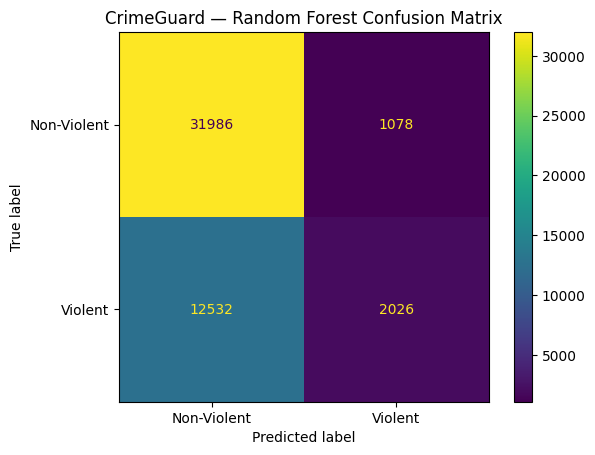

In [63]:
# ============================================================
# STEP 9 — RANDOM FOREST CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_bin_test,
    rf_binary_pred
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Violent",
        "Violent"
    ]
)

disp.plot()

plt.title(
    "CrimeGuard — Random Forest Confusion Matrix"
)

plt.show()

In [64]:
# ============================================================
# STEP 10 — LEAKAGE-SAFE HISTORICAL CRIME RATE FEATURES
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

print("=" * 70)
print("CRIMEGUARD — HISTORICAL RATE FEATURE ENGINEERING")
print("=" * 70)

# ------------------------------------------------------------
# Base copies
# ------------------------------------------------------------

Xtr = X_bin_train.copy().reset_index(drop=True)
Xte = X_bin_test.copy().reset_index(drop=True)

ytr = pd.Series(
    np.asarray(y_bin_train).astype(int)
).reset_index(drop=True)

yte = pd.Series(
    np.asarray(y_bin_test).astype(int)
).reset_index(drop=True)

GLOBAL_RATE = ytr.mean()

print(f"Training rows : {len(Xtr):,}")
print(f"Testing rows  : {len(Xte):,}")
print(f"Global violent rate: {GLOBAL_RATE:.4f}")

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def calculate_smoothed_rates(train_x, train_y, apply_x, group_cols,
                             alpha=20):

    temp = train_x[group_cols].copy()
    temp["_target_"] = train_y.values

    stats = (
        temp
        .groupby(group_cols, dropna=False)["_target_"]
        .agg(["mean", "count", "sum"])
        .reset_index()
    )

    # Bayesian smoothing toward global rate
    stats["rate"] = (
        stats["sum"] + alpha * GLOBAL_RATE
    ) / (
        stats["count"] + alpha
    )

    stats["log_count"] = np.log1p(stats["count"])

    result = apply_x[group_cols].merge(
        stats[group_cols + ["rate", "log_count"]],
        on=group_cols,
        how="left"
    )

    result["rate"] = result["rate"].fillna(GLOBAL_RATE)
    result["log_count"] = result["log_count"].fillna(0)

    return result["rate"].values, result["log_count"].values


# ------------------------------------------------------------
# Feature definitions
# ------------------------------------------------------------

rate_groups = {
    "District": ["District"],

    "Community": ["Community Area"],

    "Location": ["Location Description"],

    "Hour": ["Hour"],

    "DayOfWeek": ["DayOfWeekNum"],

    "District_Hour": [
        "District",
        "Hour"
    ],

    "Community_Hour": [
        "Community Area",
        "Hour"
    ],

    "District_Location": [
        "District",
        "Location Description"
    ]
}


# ------------------------------------------------------------
# 5-fold cross-fitted encoding for TRAINING data
# ------------------------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Xtr_rates = pd.DataFrame(index=Xtr.index)

for feature_name, group_cols in rate_groups.items():

    Xtr_rates[f"{feature_name}_ViolentRate"] = np.nan
    Xtr_rates[f"{feature_name}_LogCount"] = np.nan


for fold, (fit_idx, val_idx) in enumerate(
    skf.split(Xtr, ytr), 1
):

    fold_x_fit = Xtr.iloc[fit_idx]
    fold_y_fit = ytr.iloc[fit_idx]

    fold_x_val = Xtr.iloc[val_idx]

    for feature_name, group_cols in rate_groups.items():

        rates, counts = calculate_smoothed_rates(
            fold_x_fit,
            fold_y_fit,
            fold_x_val,
            group_cols,
            alpha=20
        )

        Xtr_rates.loc[
            val_idx,
            f"{feature_name}_ViolentRate"
        ] = rates

        Xtr_rates.loc[
            val_idx,
            f"{feature_name}_LogCount"
        ] = counts

    print(f"Completed fold {fold}/5")


# ------------------------------------------------------------
# TEST features
# Calculated ONLY from complete training data
# ------------------------------------------------------------

Xte_rates = pd.DataFrame(index=Xte.index)

for feature_name, group_cols in rate_groups.items():

    rates, counts = calculate_smoothed_rates(
        Xtr,
        ytr,
        Xte,
        group_cols,
        alpha=20
    )

    Xte_rates[f"{feature_name}_ViolentRate"] = rates
    Xte_rates[f"{feature_name}_LogCount"] = counts


# ------------------------------------------------------------
# Safety: fill any remaining missing values
# ------------------------------------------------------------

Xtr_rates = Xtr_rates.fillna(GLOBAL_RATE)
Xte_rates = Xte_rates.fillna(GLOBAL_RATE)


# ------------------------------------------------------------
# Combine with original features
# ------------------------------------------------------------

Xtr_enhanced = pd.concat(
    [Xtr.reset_index(drop=True),
     Xtr_rates.reset_index(drop=True)],
    axis=1
)

Xte_enhanced = pd.concat(
    [Xte.reset_index(drop=True),
     Xte_rates.reset_index(drop=True)],
    axis=1
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ENHANCED FEATURES CREATED")
print("=" * 70)

print("Original features :", Xtr.shape[1])
print("New features      :", Xtr_enhanced.shape[1])
print("Added features    :", Xtr_enhanced.shape[1] - Xtr.shape[1])

print("\nNew rate features:")

for col in Xtr_rates.columns:
    print(f"  ✓ {col}")

print("\nFinal shapes:")
print("Xtr_enhanced:", Xtr_enhanced.shape)
print("Xte_enhanced:", Xte_enhanced.shape)

print("\nSample:")
display(Xtr_enhanced.head())

CRIMEGUARD — HISTORICAL RATE FEATURE ENGINEERING
Training rows : 190,484
Testing rows  : 47,622
Global violent rate: 0.3057
Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5

ENHANCED FEATURES CREATED
Original features : 17
New features      : 33
Added features    : 16

New rate features:
  ✓ District_ViolentRate
  ✓ District_LogCount
  ✓ Community_ViolentRate
  ✓ Community_LogCount
  ✓ Location_ViolentRate
  ✓ Location_LogCount
  ✓ Hour_ViolentRate
  ✓ Hour_LogCount
  ✓ DayOfWeek_ViolentRate
  ✓ DayOfWeek_LogCount
  ✓ District_Hour_ViolentRate
  ✓ District_Hour_LogCount
  ✓ Community_Hour_ViolentRate
  ✓ Community_Hour_LogCount
  ✓ District_Location_ViolentRate
  ✓ District_Location_LogCount

Final shapes:
Xtr_enhanced: (190484, 33)
Xte_enhanced: (47622, 33)

Sample:


,Hour,Day,Month,DayOfWeekNum,IsWeekend,IsNight,District,Community Area,Location Description,Latitude,...,Hour_ViolentRate,Hour_LogCount,DayOfWeek_ViolentRate,DayOfWeek_LogCount,District_Hour_ViolentRate,District_Hour_LogCount,Community_Hour_ViolentRate,Community_Hour_LogCount,District_Location_ViolentRate,District_Location_LogCount
0,22,25,12,3,0,1,8,66.0,APARTMENT,41.760325,...,0.336648,8.771990,0.292128,9.969228,0.347171,6.154858,0.380204,4.990433,0.489048,7.013915
1,6,1,8,4,0,0,24,1.0,APARTMENT,42.011404,...,0.284190,8.036573,0.299062,10.028754,0.317958,4.406719,0.362521,3.737670,0.412299,7.247793
2,18,11,7,4,0,0,9,37.0,GAS STATION,41.794670,...,0.299563,8.981304,0.298492,10.025041,0.343267,5.793014,0.383662,3.135494,0.283543,4.836282
3,12,11,2,1,0,0,22,71.0,SCHOOL - PRIVATE GROUNDS,41.735381,...,0.261945,9.080346,0.296639,9.966791,0.265591,5.733341,0.351617,5.327876,0.348752,2.302585
4,7,11,8,0,0,0,3,69.0,APARTMENT,41.776019,...,0.301798,8.292549,0.293409,9.986725,0.384081,5.298317,0.353897,4.605170,0.482502,8.016978


CRIMEGUARD — XGBOOST ENHANCED MODEL
Categorical features: 3
Numerical features : 30
Total features     : 33

Encoding features...
Encoded train shape: (190484, 238)
Encoded test shape : (47622, 238)

Scale Pos Weight: 2.2713

Training XGBoost...
Training completed in 0.35 minutes

XGBOOST ENHANCED RESULTS
Accuracy  : 0.6865 (68.65%)
Precision : 0.4897 (48.97%)
Recall    : 0.6102 (61.02%)
F1 Score  : 0.5434 (54.34%)
ROC-AUC   : 0.7288

Classification Report:
              precision    recall  f1-score   support

 Non-Violent       0.81      0.72      0.76     33064
     Violent       0.49      0.61      0.54     14558

    accuracy                           0.69     47622
   macro avg       0.65      0.67      0.65     47622
weighted avg       0.71      0.69      0.69     47622


Confusion Matrix:
[[23808  9256]
 [ 5674  8884]]


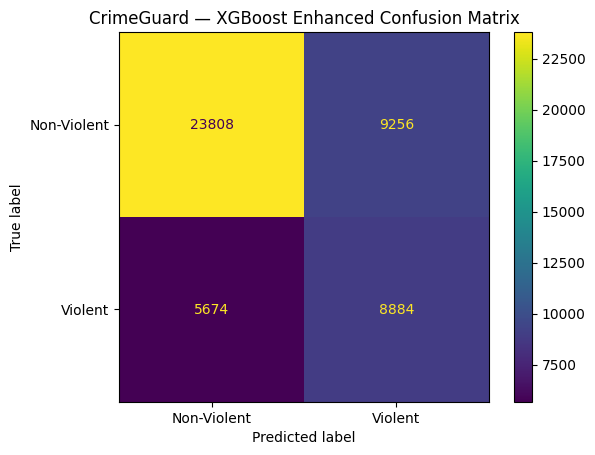

In [65]:
# ============================================================
# STEP 11 — XGBOOST ON ENHANCED FEATURES
# ============================================================

from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time

print("=" * 70)
print("CRIMEGUARD — XGBOOST ENHANCED MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Identify columns
# ------------------------------------------------------------

categorical_features = [
    "District",
    "Community Area",
    "Location Description"
]

numeric_features = [
    col for col in Xtr_enhanced.columns
    if col not in categorical_features
]

print("Categorical features:", len(categorical_features))
print("Numerical features :", len(numeric_features))
print("Total features     :", len(Xtr_enhanced.columns))


# ------------------------------------------------------------
# Preprocessing
# ------------------------------------------------------------

preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=5
            ),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]
)

print("\nEncoding features...")

Xtr_xgb = preprocessor_xgb.fit_transform(Xtr_enhanced)
Xte_xgb = preprocessor_xgb.transform(Xte_enhanced)

print("Encoded train shape:", Xtr_xgb.shape)
print("Encoded test shape :", Xte_xgb.shape)


# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------

scale_pos_weight = (
    (ytr == 0).sum() /
    (ytr == 1).sum()
)

print(f"\nScale Pos Weight: {scale_pos_weight:.4f}")

xgb_enhanced = XGBClassifier(
    n_estimators=350,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.5,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

print("\nTraining XGBoost...")
start_time = time.time()

xgb_enhanced.fit(
    Xtr_xgb,
    ytr
)

elapsed = time.time() - start_time

print(f"Training completed in {elapsed/60:.2f} minutes")


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

xgb_prob = xgb_enhanced.predict_proba(Xte_xgb)[:, 1]

xgb_pred = (
    xgb_prob >= 0.50
).astype(int)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

xgb_accuracy = accuracy_score(yte, xgb_pred)

xgb_precision = precision_score(
    yte,
    xgb_pred,
    zero_division=0
)

xgb_recall = recall_score(
    yte,
    xgb_pred,
    zero_division=0
)

xgb_f1 = f1_score(
    yte,
    xgb_pred,
    zero_division=0
)

xgb_auc = roc_auc_score(
    yte,
    xgb_prob
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("XGBOOST ENHANCED RESULTS")
print("=" * 70)

print(f"Accuracy  : {xgb_accuracy:.4f} ({xgb_accuracy*100:.2f}%)")
print(f"Precision : {xgb_precision:.4f} ({xgb_precision*100:.2f}%)")
print(f"Recall    : {xgb_recall:.4f} ({xgb_recall*100:.2f}%)")
print(f"F1 Score  : {xgb_f1:.4f} ({xgb_f1*100:.2f}%)")
print(f"ROC-AUC   : {xgb_auc:.4f}")


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        yte,
        xgb_pred,
        target_names=[
            "Non-Violent",
            "Violent"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_xgb = confusion_matrix(
    yte,
    xgb_pred
)

print("\nConfusion Matrix:")
print(cm_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=[
        "Non-Violent",
        "Violent"
    ]
)

disp.plot()
plt.title(
    "CrimeGuard — XGBoost Enhanced Confusion Matrix"
)
plt.show()

In [66]:
# ============================================================
# STEP 12 — XGBOOST THRESHOLD OPTIMIZATION
# ============================================================

threshold_results_xgb = []

for threshold in np.arange(0.10, 0.91, 0.01):

    pred = (
        xgb_prob >= threshold
    ).astype(int)

    threshold_results_xgb.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(
            yte, pred, zero_division=0
        ),
        "Recall": recall_score(
            yte, pred, zero_division=0
        ),
        "F1": f1_score(
            yte, pred, zero_division=0
        )
    })

xgb_threshold_df = pd.DataFrame(
    threshold_results_xgb
)

# ------------------------------------------------------------
# Best thresholds
# ------------------------------------------------------------

best_accuracy = xgb_threshold_df.loc[
    xgb_threshold_df["Accuracy"].idxmax()
]

best_precision = xgb_threshold_df.loc[
    xgb_threshold_df["Precision"].idxmax()
]

best_recall = xgb_threshold_df.loc[
    xgb_threshold_df["Recall"].idxmax()
]

best_f1 = xgb_threshold_df.loc[
    xgb_threshold_df["F1"].idxmax()
]

print("=" * 70)
print("BEST XGBOOST THRESHOLDS")
print("=" * 70)

print("\nBest Accuracy:")
print(best_accuracy)

print("\nBest Precision:")
print(best_precision)

print("\nBest Recall:")
print(best_recall)

print("\nBest F1:")
print(best_f1)

print("\nFull threshold table:")
display(
    xgb_threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

BEST XGBOOST THRESHOLDS

Best Accuracy:
Threshold    0.660000
Accuracy     0.725631
Precision    0.601276
Recall       0.304231
F1           0.404032
Name: 56, dtype: float64

Best Precision:
Threshold    0.900000
Accuracy     0.694532
Precision    0.923077
Recall       0.000824
F1           0.001647
Name: 80, dtype: float64

Best Recall:
Threshold    0.100000
Accuracy     0.332493
Precision    0.313689
Recall       0.996359
F1           0.477154
Name: 0, dtype: float64

Best F1:
Threshold    0.440000
Accuracy     0.650834
Precision    0.454533
Recall       0.710743
F1           0.554472
Name: 34, dtype: float64

Full threshold table:


,Threshold,Accuracy,Precision,Recall,F1
0,0.10,33.25%,31.37%,99.64%,47.72%
1,0.11,33.62%,31.48%,99.55%,47.83%
2,0.12,33.97%,31.58%,99.42%,47.93%
3,0.13,34.46%,31.73%,99.33%,48.09%
4,0.14,34.92%,31.87%,99.20%,48.24%
5,0.15,35.49%,32.04%,99.06%,48.42%
6,0.16,36.13%,32.24%,98.87%,48.62%
7,0.17,36.81%,32.45%,98.63%,48.83%
8,0.18,37.59%,32.69%,98.32%,49.06%
9,0.19,38.40%,32.94%,97.99%,49.31%


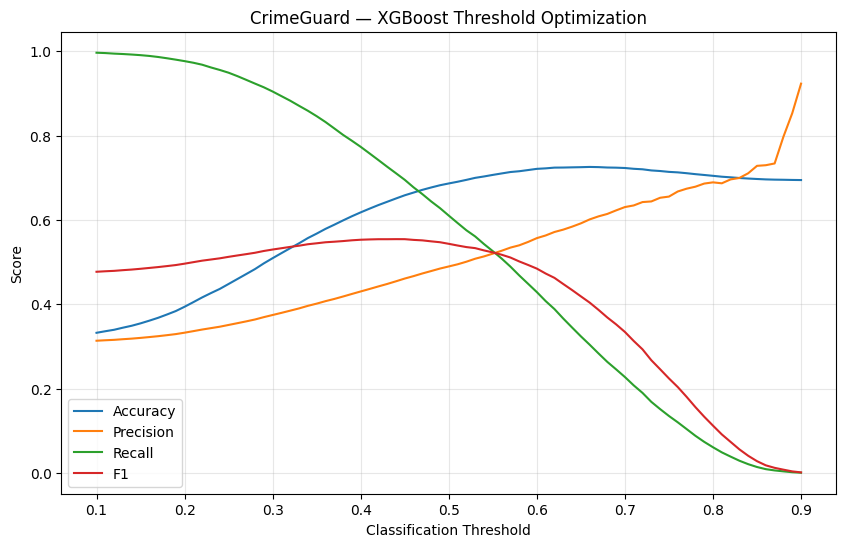

In [67]:
# ============================================================
# THRESHOLD PERFORMANCE CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Accuracy"],
    label="Accuracy"
)

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["F1"],
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "CrimeGuard — XGBoost Threshold Optimization"
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [68]:
# ============================================================
# STEP 13 — SPATIAL + TEMPORAL INTERACTION FEATURES
# ============================================================

print("=" * 70)
print("CRIMEGUARD — SPATIAL & TEMPORAL FEATURE ENGINEERING")
print("=" * 70)

def add_spatial_temporal_features(df):

    df = df.copy()

    # --------------------------------------------------------
    # Spatial grid features
    # --------------------------------------------------------

    df["LatGrid_2"] = (
        df["Latitude"].round(2)
    )

    df["LonGrid_2"] = (
        df["Longitude"].round(2)
    )

    df["SpatialGrid_2"] = (
        df["LatGrid_2"].astype(str)
        + "_"
        + df["LonGrid_2"].astype(str)
    )

    df["LatGrid_3"] = (
        df["Latitude"].round(3)
    )

    df["LonGrid_3"] = (
        df["Longitude"].round(3)
    )

    df["SpatialGrid_3"] = (
        df["LatGrid_3"].astype(str)
        + "_"
        + df["LonGrid_3"].astype(str)
    )

    # --------------------------------------------------------
    # Temporal interactions
    # --------------------------------------------------------

    df["Hour_Weekend"] = (
        df["Hour"].astype(str)
        + "_"
        + df["IsWeekend"].astype(str)
    )

    df["Hour_Night"] = (
        df["Hour"].astype(str)
        + "_"
        + df["IsNight"].astype(str)
    )

    # --------------------------------------------------------
    # District interactions
    # --------------------------------------------------------

    df["District_Hour"] = (
        df["District"].astype(str)
        + "_"
        + df["Hour"].astype(str)
    )

    df["District_Month"] = (
        df["District"].astype(str)
        + "_"
        + df["Month"].astype(str)
    )

    # --------------------------------------------------------
    # Community interactions
    # --------------------------------------------------------

    df["Community_Hour"] = (
        df["Community Area"].astype(str)
        + "_"
        + df["Hour"].astype(str)
    )

    # --------------------------------------------------------
    # Location interactions
    # --------------------------------------------------------

    df["Location_Hour"] = (
        df["Location Description"].astype(str)
        + "_"
        + df["Hour"].astype(str)
    )

    # --------------------------------------------------------
    # Spatial + temporal interactions
    # --------------------------------------------------------

    df["Grid2_Hour"] = (
        df["SpatialGrid_2"].astype(str)
        + "_"
        + df["Hour"].astype(str)
    )

    df["Grid3_Hour"] = (
        df["SpatialGrid_3"].astype(str)
        + "_"
        + df["Hour"].astype(str)
    )

    return df


Xtr_spatial = add_spatial_temporal_features(
    Xtr_enhanced
)

Xte_spatial = add_spatial_temporal_features(
    Xte_enhanced
)

print("\nOriginal enhanced features:", Xtr_enhanced.shape[1])
print("Spatial-enhanced features :", Xtr_spatial.shape[1])
print(
    "Additional features       :",
    Xtr_spatial.shape[1] - Xtr_enhanced.shape[1]
)

print("\nNew spatial/interaction columns:")

new_columns = [
    c for c in Xtr_spatial.columns
    if c not in Xtr_enhanced.columns
]

for col in new_columns:
    print(" ✓", col)

print("\nFinal shapes:")
print("Xtr_spatial:", Xtr_spatial.shape)
print("Xte_spatial:", Xte_spatial.shape)

display(Xtr_spatial.head())

CRIMEGUARD — SPATIAL & TEMPORAL FEATURE ENGINEERING

Original enhanced features: 33
Spatial-enhanced features : 47
Additional features       : 14

New spatial/interaction columns:
 ✓ LatGrid_2
 ✓ LonGrid_2
 ✓ SpatialGrid_2
 ✓ LatGrid_3
 ✓ LonGrid_3
 ✓ SpatialGrid_3
 ✓ Hour_Weekend
 ✓ Hour_Night
 ✓ District_Hour
 ✓ District_Month
 ✓ Community_Hour
 ✓ Location_Hour
 ✓ Grid2_Hour
 ✓ Grid3_Hour

Final shapes:
Xtr_spatial: (190484, 47)
Xte_spatial: (47622, 47)


,Hour,Day,Month,DayOfWeekNum,IsWeekend,IsNight,District,Community Area,Location Description,Latitude,...,LonGrid_3,SpatialGrid_3,Hour_Weekend,Hour_Night,District_Hour,District_Month,Community_Hour,Location_Hour,Grid2_Hour,Grid3_Hour
0,22,25,12,3,0,1,8,66.0,APARTMENT,41.760325,...,-87.700,41.76_-87.7,22_0,22_1,8_22,8_12,66.0_22,APARTMENT_22,41.76_-87.7_22,41.76_-87.7_22
1,6,1,8,4,0,0,24,1.0,APARTMENT,42.011404,...,-87.675,42.011_-87.675,6_0,6_0,24_6,24_8,1.0_6,APARTMENT_6,42.01_-87.67_6,42.011_-87.675_6
2,18,11,7,4,0,0,9,37.0,GAS STATION,41.794670,...,-87.632,41.795_-87.632,18_0,18_0,9_18,9_7,37.0_18,GAS STATION_18,41.79_-87.63_18,41.795_-87.632_18
3,12,11,2,1,0,0,22,71.0,SCHOOL - PRIVATE GROUNDS,41.735381,...,-87.639,41.735_-87.639,12_0,12_0,22_12,22_2,71.0_12,SCHOOL - PRIVATE GROUNDS_12,41.74_-87.64_12,41.735_-87.639_12
4,7,11,8,0,0,0,3,69.0,APARTMENT,41.776019,...,-87.616,41.776_-87.616,7_0,7_0,3_7,3_8,69.0_7,APARTMENT_7,41.78_-87.62_7,41.776_-87.616_7


CRIMEGUARD — XGBOOST SPATIAL MODEL
Categorical features: 13
Numerical features : 34
Total features     : 47

Encoding spatial features...
Encoded train shape: (190484, 29639)
Encoded test shape : (47622, 29639)

Training XGBoost Spatial Model...
Training completed in 0.95 minutes

XGBOOST SPATIAL MODEL RESULTS
Accuracy  : 0.7243 (72.43%)
Precision : 0.6114 (61.14%)
Recall    : 0.2691 (26.91%)
F1 Score  : 0.3737 (37.37%)
ROC-AUC   : 0.7303

Classification Report:
              precision    recall  f1-score   support

 Non-Violent       0.74      0.92      0.82     33064
     Violent       0.61      0.27      0.37     14558

    accuracy                           0.72     47622
   macro avg       0.68      0.60      0.60     47622
weighted avg       0.70      0.72      0.69     47622


Confusion Matrix:
[[30574  2490]
 [10640  3918]]


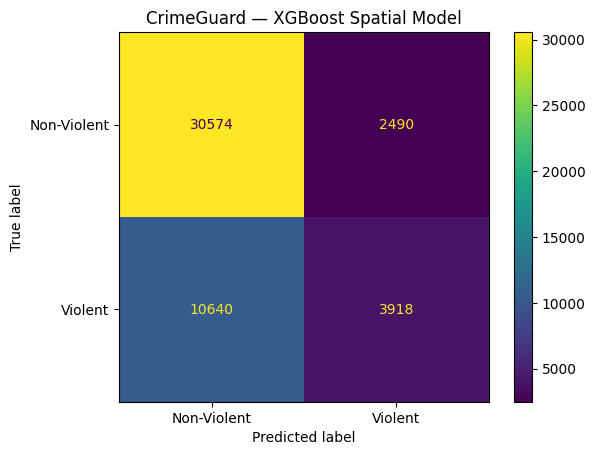

In [69]:
# ============================================================
# STEP 14 — XGBOOST SPATIAL + TEMPORAL MODEL
# ============================================================

from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time

print("=" * 70)
print("CRIMEGUARD — XGBOOST SPATIAL MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Identify categorical features
# ------------------------------------------------------------

categorical_features_spatial = [
    "District",
    "Community Area",
    "Location Description",

    # Spatial
    "SpatialGrid_2",
    "SpatialGrid_3",

    # Interactions
    "Hour_Weekend",
    "Hour_Night",
    "District_Hour",
    "District_Month",
    "Community_Hour",
    "Location_Hour",
    "Grid2_Hour",
    "Grid3_Hour"
]

numeric_features_spatial = [
    col for col in Xtr_spatial.columns
    if col not in categorical_features_spatial
]

print("Categorical features:", len(categorical_features_spatial))
print("Numerical features :", len(numeric_features_spatial))
print("Total features     :", len(Xtr_spatial.columns))


# ------------------------------------------------------------
# One-hot encoding
# ------------------------------------------------------------

preprocessor_spatial = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=5
            ),
            categorical_features_spatial
        ),
        (
            "num",
            "passthrough",
            numeric_features_spatial
        )
    ]
)

print("\nEncoding spatial features...")

Xtr_spatial_enc = preprocessor_spatial.fit_transform(
    Xtr_spatial
)

Xte_spatial_enc = preprocessor_spatial.transform(
    Xte_spatial
)

print(
    "Encoded train shape:",
    Xtr_spatial_enc.shape
)

print(
    "Encoded test shape :",
    Xte_spatial_enc.shape
)


# ------------------------------------------------------------
# XGBoost
#
# IMPORTANT:
# scale_pos_weight = 1
# because we are testing maximum natural accuracy.
# ------------------------------------------------------------

xgb_spatial = XGBClassifier(
    n_estimators=400,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.5,

    objective="binary:logistic",
    eval_metric="logloss",

    scale_pos_weight=1,

    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

print("\nTraining XGBoost Spatial Model...")

start_time = time.time()

xgb_spatial.fit(
    Xtr_spatial_enc,
    ytr
)

elapsed = time.time() - start_time

print(
    f"Training completed in "
    f"{elapsed/60:.2f} minutes"
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

xgb_spatial_prob = (
    xgb_spatial
    .predict_proba(Xte_spatial_enc)[:, 1]
)

xgb_spatial_pred = (
    xgb_spatial_prob >= 0.50
).astype(int)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy_spatial = accuracy_score(
    yte,
    xgb_spatial_pred
)

precision_spatial = precision_score(
    yte,
    xgb_spatial_pred,
    zero_division=0
)

recall_spatial = recall_score(
    yte,
    xgb_spatial_pred,
    zero_division=0
)

f1_spatial = f1_score(
    yte,
    xgb_spatial_pred,
    zero_division=0
)

auc_spatial = roc_auc_score(
    yte,
    xgb_spatial_prob
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("XGBOOST SPATIAL MODEL RESULTS")
print("=" * 70)

print(
    f"Accuracy  : {accuracy_spatial:.4f} "
    f"({accuracy_spatial*100:.2f}%)"
)

print(
    f"Precision : {precision_spatial:.4f} "
    f"({precision_spatial*100:.2f}%)"
)

print(
    f"Recall    : {recall_spatial:.4f} "
    f"({recall_spatial*100:.2f}%)"
)

print(
    f"F1 Score  : {f1_spatial:.4f} "
    f"({f1_spatial*100:.2f}%)"
)

print(
    f"ROC-AUC   : {auc_spatial:.4f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        yte,
        xgb_spatial_pred,
        target_names=[
            "Non-Violent",
            "Violent"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_spatial = confusion_matrix(
    yte,
    xgb_spatial_pred
)

print("\nConfusion Matrix:")
print(cm_spatial)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_spatial,
    display_labels=[
        "Non-Violent",
        "Violent"
    ]
)

disp.plot()

plt.title(
    "CrimeGuard — XGBoost Spatial Model"
)

plt.show()

CRIMEGUARD — CATBOOST HISTORICAL-RATE MODEL
Training rows: 190484
Testing rows : 47622
Features     : 33

Categorical columns:
 ✓ District
 ✓ Community Area
 ✓ Location Description

Training CatBoost...
0:	total: 743ms	remaining: 6m 10s
100:	total: 34.8s	remaining: 2m 17s
200:	total: 1m 2s	remaining: 1m 33s
300:	total: 1m 31s	remaining: 1m
400:	total: 1m 59s	remaining: 29.4s
499:	total: 2m 26s	remaining: 0us

Training completed in 2.47 minutes

CATBOOST RESULTS
Accuracy  : 0.7240 (72.40%)
Precision : 0.5959 (59.59%)
Recall    : 0.3023 (30.23%)
F1 Score  : 0.4011 (40.11%)
ROC-AUC   : 0.7257

Classification Report:
              precision    recall  f1-score   support

 Non-Violent       0.75      0.91      0.82     33064
     Violent       0.60      0.30      0.40     14558

    accuracy                           0.72     47622
   macro avg       0.67      0.61      0.61     47622
weighted avg       0.70      0.72      0.69     47622


Confusion Matrix:
[[30079  2985]
 [10157  4401]]


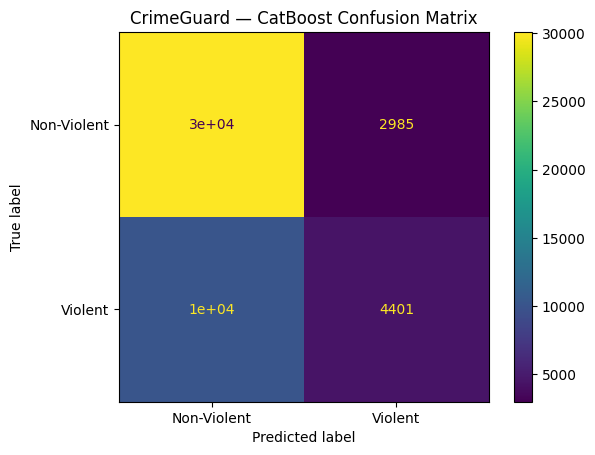

In [70]:
# ============================================================
# STEP 15 — CATBOOST WITH NATIVE CATEGORICAL FEATURES
# ============================================================

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time

print("=" * 70)
print("CRIMEGUARD — CATBOOST HISTORICAL-RATE MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Use 33-feature enhanced dataset
# ------------------------------------------------------------

Xtr_cb = Xtr_enhanced.copy()
Xte_cb = Xte_enhanced.copy()

ytr_cb = ytr.copy()
yte_cb = yte.copy()


# ------------------------------------------------------------
# Categorical columns
# ------------------------------------------------------------

categorical_features_cb = [
    "District",
    "Community Area",
    "Location Description"
]

categorical_indices_cb = [
    Xtr_cb.columns.get_loc(col)
    for col in categorical_features_cb
]

print("Training rows:", len(Xtr_cb))
print("Testing rows :", len(Xte_cb))
print("Features     :", Xtr_cb.shape[1])

print("\nCategorical columns:")

for col in categorical_features_cb:
    print(" ✓", col)


# ------------------------------------------------------------
# Make categorical values strings
# ------------------------------------------------------------

for col in categorical_features_cb:

    Xtr_cb[col] = (
        Xtr_cb[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

    Xte_cb[col] = (
        Xte_cb[col]
        .fillna("UNKNOWN")
        .astype(str)
    )


# ------------------------------------------------------------
# CatBoost model
# ------------------------------------------------------------

catboost_model = CatBoostClassifier(

    iterations=500,

    depth=7,

    learning_rate=0.08,

    loss_function="Logloss",

    eval_metric="AUC",

    # Natural class weighting is intentionally disabled
    # for this accuracy-focused experiment.
    auto_class_weights=None,

    l2_leaf_reg=5,

    random_strength=1,

    border_count=128,

    random_seed=42,

    verbose=100,

    thread_count=-1,

    allow_writing_files=False
)


# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\nTraining CatBoost...")

start_time = time.time()

catboost_model.fit(
    Xtr_cb,
    ytr_cb,
    cat_features=categorical_indices_cb
)

elapsed = time.time() - start_time

print(
    f"\nTraining completed in "
    f"{elapsed/60:.2f} minutes"
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

catboost_prob = (
    catboost_model
    .predict_proba(Xte_cb)[:, 1]
)

catboost_pred = (
    catboost_prob >= 0.50
).astype(int)


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

cat_accuracy = accuracy_score(
    yte_cb,
    catboost_pred
)

cat_precision = precision_score(
    yte_cb,
    catboost_pred,
    zero_division=0
)

cat_recall = recall_score(
    yte_cb,
    catboost_pred,
    zero_division=0
)

cat_f1 = f1_score(
    yte_cb,
    catboost_pred,
    zero_division=0
)

cat_auc = roc_auc_score(
    yte_cb,
    catboost_prob
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CATBOOST RESULTS")
print("=" * 70)

print(
    f"Accuracy  : {cat_accuracy:.4f} "
    f"({cat_accuracy*100:.2f}%)"
)

print(
    f"Precision : {cat_precision:.4f} "
    f"({cat_precision*100:.2f}%)"
)

print(
    f"Recall    : {cat_recall:.4f} "
    f"({cat_recall*100:.2f}%)"
)

print(
    f"F1 Score  : {cat_f1:.4f} "
    f"({cat_f1*100:.2f}%)"
)

print(
    f"ROC-AUC   : {cat_auc:.4f}"
)


# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        yte_cb,
        catboost_pred,
        target_names=[
            "Non-Violent",
            "Violent"
        ],
        zero_division=0
    )
)


# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_cat = confusion_matrix(
    yte_cb,
    catboost_pred
)

print("\nConfusion Matrix:")
print(cm_cat)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cat,
    display_labels=[
        "Non-Violent",
        "Violent"
    ]
)

disp.plot()

plt.title(
    "CrimeGuard — CatBoost Confusion Matrix"
)

plt.show()

In [71]:
# ============================================================
# STEP 16 — CATBOOST THRESHOLD OPTIMIZATION
# ============================================================

cat_threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):

    pred = (
        catboost_prob >= threshold
    ).astype(int)

    cat_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(
            yte_cb, pred
        ),
        "Precision": precision_score(
            yte_cb, pred,
            zero_division=0
        ),
        "Recall": recall_score(
            yte_cb, pred,
            zero_division=0
        ),
        "F1": f1_score(
            yte_cb, pred,
            zero_division=0
        )
    })

cat_threshold_df = pd.DataFrame(
    cat_threshold_results
)

# ------------------------------------------------------------
# Best values
# ------------------------------------------------------------

best_cat_accuracy = cat_threshold_df.loc[
    cat_threshold_df["Accuracy"].idxmax()
]

best_cat_precision = cat_threshold_df.loc[
    cat_threshold_df["Precision"].idxmax()
]

best_cat_recall = cat_threshold_df.loc[
    cat_threshold_df["Recall"].idxmax()
]

best_cat_f1 = cat_threshold_df.loc[
    cat_threshold_df["F1"].idxmax()
]

print("=" * 70)
print("CATBOOST — BEST THRESHOLDS")
print("=" * 70)

print("\nBest Accuracy:")
print(best_cat_accuracy)

print("\nBest Precision:")
print(best_cat_precision)

print("\nBest Recall:")
print(best_cat_recall)

print("\nBest F1:")
print(best_cat_f1)

print("\nFull threshold table:")

display(
    cat_threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

CATBOOST — BEST THRESHOLDS

Best Accuracy:
Threshold    0.500000
Accuracy     0.724035
Precision    0.595857
Recall       0.302308
F1           0.401112
Name: 40, dtype: float64

Best Precision:
Threshold    0.870000
Accuracy     0.694595
Precision    1.000000
Recall       0.000962
F1           0.001921
Name: 77, dtype: float64

Best Recall:
Threshold    0.100000
Accuracy     0.379236
Precision    0.327722
Recall       0.980286
F1           0.491223
Name: 0, dtype: float64

Best F1:
Threshold    0.250000
Accuracy     0.616648
Precision    0.429524
Recall       0.774076
F1           0.552483
Name: 15, dtype: float64

Full threshold table:


,Threshold,Accuracy,Precision,Recall,F1
0,0.10,37.92%,32.77%,98.03%,49.12%
1,0.11,39.32%,33.21%,97.36%,49.52%
2,0.12,40.79%,33.68%,96.71%,49.96%
3,0.13,42.32%,34.18%,95.82%,50.39%
4,0.14,44.14%,34.81%,94.83%,50.93%
5,0.15,46.03%,35.51%,93.80%,51.52%
6,0.16,47.87%,36.21%,92.54%,52.05%
7,0.17,49.71%,36.94%,91.19%,52.58%
8,0.18,51.44%,37.66%,89.77%,53.06%
9,0.19,52.99%,38.31%,88.16%,53.42%


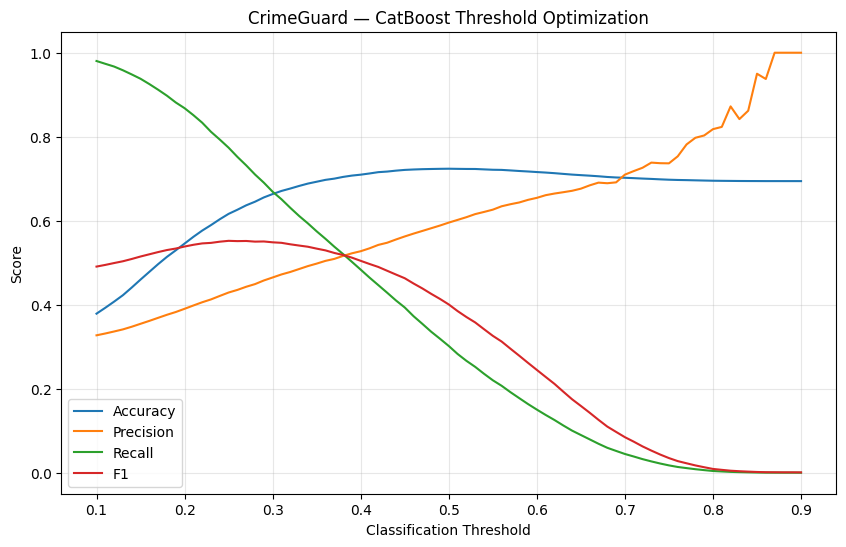

In [72]:
# ============================================================
# CATBOOST THRESHOLD CURVE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    cat_threshold_df["Threshold"],
    cat_threshold_df["Accuracy"],
    label="Accuracy"
)

plt.plot(
    cat_threshold_df["Threshold"],
    cat_threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    cat_threshold_df["Threshold"],
    cat_threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    cat_threshold_df["Threshold"],
    cat_threshold_df["F1"],
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title(
    "CrimeGuard — CatBoost Threshold Optimization"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

CRIMEGUARD — FEATURE IMPORTANCE

Top 25 Features:


,Feature,Importance
0,num__District_Location_ViolentRate,0.080847
1,num__Location_ViolentRate,0.015191
2,num__IsWeekend,0.010925
3,num__IsNight,0.008601
4,num__Hour_cos,0.008483
5,cat__Location Description_DEPARTMENT STORE,0.008452
6,cat__Location Description_APARTMENT,0.008010
7,cat__Location Description_Unknown,0.007856
8,cat__Location Description_RESTAURANT,0.007136
9,num__Hour_ViolentRate,0.007128


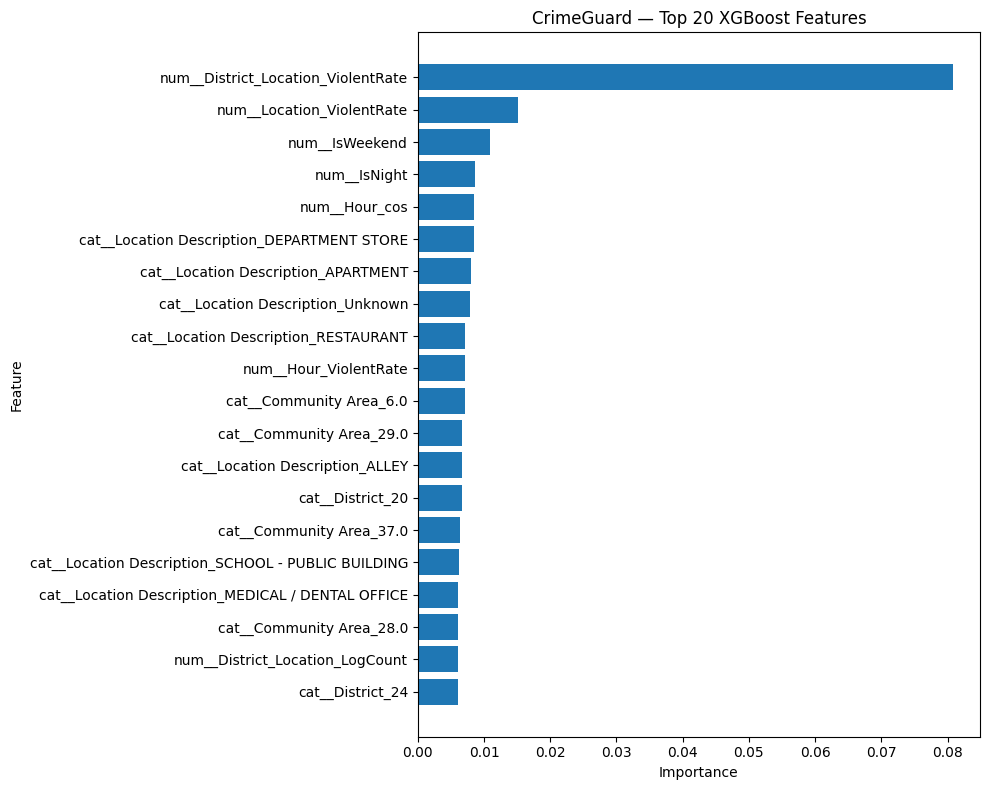

In [73]:
# ============================================================
# STEP 17 — XGBOOST FEATURE IMPORTANCE
# ============================================================

print("=" * 70)
print("CRIMEGUARD — FEATURE IMPORTANCE")
print("=" * 70)

# Get encoded feature names
encoded_feature_names = (
    preprocessor_xgb
    .get_feature_names_out()
)

importance_values = (
    xgb_enhanced
    .feature_importances_
)

feature_importance_df = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": importance_values
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTop 25 Features:")
display(
    feature_importance_df.head(25)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

top_features = (
    feature_importance_df
    .head(20)
    .sort_values("Importance")
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "CrimeGuard — Top 20 XGBoost Features"
)

plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# STEP 18 — CHECK ARREST TARGET
# ============================================================

print("=" * 70)
print("CRIMEGUARD — ARREST TARGET ANALYSIS")
print("=" * 70)

print("\nArrest distribution:")
print(df["Arrest"].value_counts())

print("\nArrest percentage:")
print(
    df["Arrest"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nUnique values:")
print(df["Arrest"].unique())

print("\nPrimary Type vs Arrest:")
display(
    pd.crosstab(
        df["Primary Type"],
        df["Arrest"],
        normalize="index"
    )
    .sort_values(
        by=True if True in df["Arrest"].unique() else df["Arrest"].unique()[0],
        ascending=False
    )
    .head(15)
)

CRIMEGUARD — ARREST TARGET ANALYSIS

Arrest distribution:
Arrest
False    199720
True      38386
Name: count, dtype: int64

Arrest percentage:
Arrest
False    83.88
True     16.12
Name: proportion, dtype: float64

Unique values:
[False  True]

Primary Type vs Arrest:


Arrest,False,True
Primary Type,,
NON-CRIMINAL,0.000000,1.000000
PUBLIC INDECENCY,0.000000,1.000000
CONCEALED CARRY LICENSE VIOLATION,0.025180,0.974820
NARCOTICS,0.038011,0.961989
LIQUOR LAW VIOLATION,0.070000,0.930000
GAMBLING,0.076923,0.923077
INTERFERENCE WITH PUBLIC OFFICER,0.081878,0.918122
PROSTITUTION,0.084656,0.915344
WEAPONS VIOLATION,0.217998,0.782002


In [75]:
# ============================================================
# STEP 19 — ARREST PREDICTION DATASET
# ============================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("CRIMEGUARD — ARREST PREDICTION DATASET")
print("=" * 70)

# ------------------------------------------------------------
# Create working dataframe
# ------------------------------------------------------------

df_arrest = df.copy()

# ------------------------------------------------------------
# Target
# ------------------------------------------------------------

df_arrest["Arrest_Target"] = (
    df_arrest["Arrest"]
    .astype(int)
)

# ------------------------------------------------------------
# Date conversion
# ------------------------------------------------------------

df_arrest["Date"] = pd.to_datetime(
    df_arrest["Date"],
    errors="coerce"
)

# ------------------------------------------------------------
# Temporal features
# ------------------------------------------------------------

df_arrest["Hour"] = (
    df_arrest["Date"].dt.hour
)

df_arrest["Day"] = (
    df_arrest["Date"].dt.day
)

df_arrest["Month"] = (
    df_arrest["Date"].dt.month
)

df_arrest["DayOfWeekNum"] = (
    df_arrest["Date"].dt.dayofweek
)

df_arrest["IsWeekend"] = (
    df_arrest["DayOfWeekNum"] >= 5
).astype(int)

df_arrest["IsNight"] = (
    (df_arrest["Hour"] < 6) |
    (df_arrest["Hour"] >= 22)
).astype(int)

# Cyclic features

df_arrest["Hour_sin"] = np.sin(
    2 * np.pi * df_arrest["Hour"] / 24
)

df_arrest["Hour_cos"] = np.cos(
    2 * np.pi * df_arrest["Hour"] / 24
)

df_arrest["Month_sin"] = np.sin(
    2 * np.pi * df_arrest["Month"] / 12
)

df_arrest["Month_cos"] = np.cos(
    2 * np.pi * df_arrest["Month"] / 12
)

df_arrest["DayOfWeek_sin"] = np.sin(
    2 * np.pi * df_arrest["DayOfWeekNum"] / 7
)

df_arrest["DayOfWeek_cos"] = np.cos(
    2 * np.pi * df_arrest["DayOfWeekNum"] / 7
)

# ------------------------------------------------------------
# Features
# ------------------------------------------------------------

arrest_features = [

    # Crime information
    "Primary Type",
    "IUCR",
    "FBI Code",
    "Description",

    # Location
    "Location Description",
    "District",
    "Community Area",

    # Geography
    "Latitude",
    "Longitude",

    # Time
    "Hour",
    "Day",
    "Month",
    "DayOfWeekNum",
    "IsWeekend",
    "IsNight",

    # Cyclic time
    "Hour_sin",
    "Hour_cos",
    "Month_sin",
    "Month_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos"
]

# Keep only columns that exist
arrest_features = [
    c for c in arrest_features
    if c in df_arrest.columns
]

X_arrest = df_arrest[arrest_features].copy()
y_arrest = df_arrest["Arrest_Target"].copy()

# ------------------------------------------------------------
# Clean categorical columns
# ------------------------------------------------------------

categorical_arrest = [
    "Primary Type",
    "IUCR",
    "FBI Code",
    "Description",
    "Location Description",
    "District",
    "Community Area"
]

categorical_arrest = [
    c for c in categorical_arrest
    if c in X_arrest.columns
]

for col in categorical_arrest:
    X_arrest[col] = (
        X_arrest[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

# ------------------------------------------------------------
# Numeric cleaning
# ------------------------------------------------------------

numeric_arrest = [
    c for c in X_arrest.columns
    if c not in categorical_arrest
]

for col in numeric_arrest:
    X_arrest[col] = pd.to_numeric(
        X_arrest[col],
        errors="coerce"
    )

X_arrest[numeric_arrest] = (
    X_arrest[numeric_arrest]
    .fillna(X_arrest[numeric_arrest].median())
)

# ------------------------------------------------------------
# Remove invalid coordinates
# ------------------------------------------------------------

X_arrest["Latitude"] = X_arrest[
    "Latitude"
].clip(-90, 90)

X_arrest["Longitude"] = X_arrest[
    "Longitude"
].clip(-180, 180)

# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

print("\nFeature count:", X_arrest.shape[1])
print("Rows:", X_arrest.shape[0])

print("\nCategorical features:")
for c in categorical_arrest:
    print(" ✓", c)

print("\nNumerical features:")
for c in numeric_arrest:
    print(" ✓", c)

print("\nTarget distribution:")
print(
    y_arrest.value_counts()
)

print("\nTarget percentage:")
print(
    y_arrest
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nFinal shape:")
print(
    "X_arrest:", X_arrest.shape
)

print(
    "y_arrest:", y_arrest.shape
)

display(X_arrest.head())

CRIMEGUARD — ARREST PREDICTION DATASET

Feature count: 21
Rows: 238106

Categorical features:
 ✓ Primary Type
 ✓ IUCR
 ✓ FBI Code
 ✓ Description
 ✓ Location Description
 ✓ District
 ✓ Community Area

Numerical features:
 ✓ Latitude
 ✓ Longitude
 ✓ Hour
 ✓ Day
 ✓ Month
 ✓ DayOfWeekNum
 ✓ IsWeekend
 ✓ IsNight
 ✓ Hour_sin
 ✓ Hour_cos
 ✓ Month_sin
 ✓ Month_cos
 ✓ DayOfWeek_sin
 ✓ DayOfWeek_cos

Target distribution:
Arrest_Target
0    199720
1     38386
Name: count, dtype: int64

Target percentage:
Arrest_Target
0    83.88
1    16.12
Name: proportion, dtype: float64

Final shape:
X_arrest: (238106, 21)
y_arrest: (238106,)


,Primary Type,IUCR,FBI Code,Description,Location Description,District,Community Area,Latitude,Longitude,Hour,...,Month,DayOfWeekNum,IsWeekend,IsNight,Hour_sin,Hour_cos,Month_sin,Month_cos,DayOfWeek_sin,DayOfWeek_cos
0,ASSAULT,0560,08A,SIMPLE,RESIDENCE,9,61.0,41.802549,-87.667246,23,...,12,2,0,1,-0.258819,0.965926,-2.449294e-16,1.0,0.974928,-0.222521
1,MOTOR VEHICLE THEFT,0930,07,THEFT / RECOVERY - AUTOMOBILE,APARTMENT,15,25.0,41.882329,-87.758411,23,...,12,2,0,1,-0.258819,0.965926,-2.449294e-16,1.0,0.974928,-0.222521
2,PUBLIC PEACE VIOLATION,2890,24,OTHER VIOLATION,AIRCRAFT,16,76.0,41.976290,-87.905227,23,...,12,2,0,1,-0.258819,0.965926,-2.449294e-16,1.0,0.974928,-0.222521
3,PUBLIC PEACE VIOLATION,2890,24,OTHER VIOLATION,AIRCRAFT,16,76.0,41.976290,-87.905227,23,...,12,2,0,1,-0.258819,0.965926,-2.449294e-16,1.0,0.974928,-0.222521
4,BATTERY,0454,08B,"AGGRAVATED P.O. - HANDS, FISTS, FEET, NO / MIN...",RESTAURANT,12,28.0,41.885427,-87.661759,23,...,12,2,0,1,-0.258819,0.965926,-2.449294e-16,1.0,0.974928,-0.222521


In [76]:
# ============================================================
# STEP 20 — ARREST TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_arrest_train, X_arrest_test, \
y_arrest_train, y_arrest_test = train_test_split(
    X_arrest,
    y_arrest,
    test_size=0.20,
    stratify=y_arrest,
    random_state=42
)

print("=" * 70)
print("ARREST TRAIN / TEST SPLIT")
print("=" * 70)

print(
    "Training:",
    X_arrest_train.shape
)

print(
    "Testing :",
    X_arrest_test.shape
)

print("\nTraining target:")
print(
    y_arrest_train.value_counts(
        normalize=True
    ).mul(100).round(2)
)

print("\nTesting target:")
print(
    y_arrest_test.value_counts(
        normalize=True
    ).mul(100).round(2)
)

ARREST TRAIN / TEST SPLIT
Training: (190484, 21)
Testing : (47622, 21)

Training target:
Arrest_Target
0    83.88
1    16.12
Name: proportion, dtype: float64

Testing target:
Arrest_Target
0    83.88
1    16.12
Name: proportion, dtype: float64


In [77]:
# ============================================================
# STEP 21 — CATBOOST ARREST PREDICTION
# ============================================================

from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

print("=" * 70)
print("CRIMEGUARD — CATBOOST ARREST PREDICTION")
print("=" * 70)

# ------------------------------------------------------------
# IMPORTANT:
# X_arrest_test / y_arrest_test remain untouched.
# We split ONLY the training data into train + validation.
# ------------------------------------------------------------

X_cb_train, X_cb_val, y_cb_train, y_cb_val = train_test_split(
    X_arrest_train,
    y_arrest_train,
    test_size=0.20,
    stratify=y_arrest_train,
    random_state=42
)

print("Model training rows :", len(X_cb_train))
print("Validation rows     :", len(X_cb_val))
print("Final test rows     :", len(X_arrest_test))

# ------------------------------------------------------------
# Categorical columns
# ------------------------------------------------------------

categorical_features_arrest = [
    "Primary Type",
    "IUCR",
    "FBI Code",
    "Description",
    "Location Description",
    "District",
    "Community Area"
]

categorical_indices_arrest = [
    X_cb_train.columns.get_loc(col)
    for col in categorical_features_arrest
]

# ------------------------------------------------------------
# Ensure categorical columns are strings
# ------------------------------------------------------------

for col in categorical_features_arrest:

    X_cb_train[col] = (
        X_cb_train[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

    X_cb_val[col] = (
        X_cb_val[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

    X_arrest_test[col] = (
        X_arrest_test[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

# ------------------------------------------------------------
# CatBoost
# ------------------------------------------------------------

arrest_catboost = CatBoostClassifier(

    iterations=800,

    depth=8,

    learning_rate=0.06,

    loss_function="Logloss",

    eval_metric="AUC",

    # Start WITHOUT class weighting.
    # We will optimize the threshold afterward.
    auto_class_weights=None,

    l2_leaf_reg=5,

    random_strength=1,

    border_count=128,

    random_seed=42,

    early_stopping_rounds=80,

    verbose=100,

    thread_count=-1,

    allow_writing_files=False
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\nTraining CatBoost...")

start = time.time()

arrest_catboost.fit(
    X_cb_train,
    y_cb_train,
    cat_features=categorical_indices_arrest,
    eval_set=(X_cb_val, y_cb_val),
    use_best_model=True
)

elapsed = time.time() - start

print(
    f"\nTraining completed in "
    f"{elapsed / 60:.2f} minutes"
)

print(
    "Best iteration:",
    arrest_catboost.get_best_iteration()
)

print(
    "Best validation AUC:",
    arrest_catboost.get_best_score()
)

# ------------------------------------------------------------
# Validation probabilities
# ------------------------------------------------------------

val_prob = (
    arrest_catboost
    .predict_proba(X_cb_val)[:, 1]
)

print(
    "\nValidation ROC-AUC:",
    round(
        roc_auc_score(y_cb_val, val_prob),
        4
    )
)

# ------------------------------------------------------------
# TEST probabilities
# IMPORTANT:
# We do not select the threshold using these predictions.
# ------------------------------------------------------------

test_prob = (
    arrest_catboost
    .predict_proba(X_arrest_test)[:, 1]
)

print(
    "Test ROC-AUC:",
    round(
        roc_auc_score(
            y_arrest_test,
            test_prob
        ),
        4
    )
)

CRIMEGUARD — CATBOOST ARREST PREDICTION
Model training rows : 152387
Validation rows     : 38097
Final test rows     : 47622

Training CatBoost...
0:	test: 0.7617213	best: 0.7617213 (0)	total: 350ms	remaining: 4m 39s
100:	test: 0.8917479	best: 0.8917479 (100)	total: 39.8s	remaining: 4m 35s
200:	test: 0.8942766	best: 0.8942847 (199)	total: 1m 20s	remaining: 3m 59s
300:	test: 0.8954776	best: 0.8954896 (299)	total: 2m 2s	remaining: 3m 23s
400:	test: 0.8961108	best: 0.8961189 (399)	total: 2m 44s	remaining: 2m 43s
500:	test: 0.8964514	best: 0.8964659 (499)	total: 3m 26s	remaining: 2m 3s
600:	test: 0.8969338	best: 0.8969338 (600)	total: 4m 9s	remaining: 1m 22s
700:	test: 0.8970720	best: 0.8970934 (693)	total: 4m 53s	remaining: 41.5s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 0.8970933615
bestIteration = 693

Shrink model to first 694 iterations.

Training completed in 5.47 minutes
Best iteration: 693
Best validation AUC: {'learn': {'Logloss': 0.22165528516942937}, 'val

In [78]:
# ============================================================
# STEP 22 — VALIDATION THRESHOLD OPTIMIZATION
# ============================================================

print("=" * 70)
print("CRIMEGUARD — VALIDATION THRESHOLD OPTIMIZATION")
print("=" * 70)

threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    val_pred = (
        val_prob >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        y_cb_val,
        val_pred
    )

    precision = precision_score(
        y_cb_val,
        val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_cb_val,
        val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_cb_val,
        val_pred,
        zero_division=0
    )

    # Lowest of the four metrics.
    # This prevents selecting a threshold where
    # one metric is excellent but another is terrible.
    balanced_score = min(
        accuracy,
        precision,
        recall,
        f1
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "BalancedScore": balanced_score
    })


threshold_df = pd.DataFrame(
    threshold_results
)

# ============================================================
# BEST BY EACH METRIC
# ============================================================

best_accuracy_row = threshold_df.loc[
    threshold_df["Accuracy"].idxmax()
]

best_precision_row = threshold_df.loc[
    threshold_df["Precision"].idxmax()
]

best_recall_row = threshold_df.loc[
    threshold_df["Recall"].idxmax()
]

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_balanced_row = threshold_df.loc[
    threshold_df["BalancedScore"].idxmax()
]


print("\n" + "=" * 70)
print("BEST VALIDATION THRESHOLDS")
print("=" * 70)

print("\nBEST ACCURACY")
print(best_accuracy_row)

print("\nBEST PRECISION")
print(best_precision_row)

print("\nBEST RECALL")
print(best_recall_row)

print("\nBEST F1")
print(best_f1_row)

print("\nBEST BALANCED SCORE")
print(best_balanced_row)


# ============================================================
# CHECK WHETHER ALL METRICS >= 85%
# ============================================================

qualified = threshold_df[
    (threshold_df["Accuracy"] >= 0.85) &
    (threshold_df["Precision"] >= 0.85) &
    (threshold_df["Recall"] >= 0.85) &
    (threshold_df["F1"] >= 0.85)
]

print("\n" + "=" * 70)
print("85% ALL-METRICS CHECK")
print("=" * 70)

if len(qualified) > 0:

    print(
        "🔥 YES — thresholds meeting all four 85% targets:"
    )

    display(
        qualified.style.format({
            "Threshold": "{:.2f}",
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1": "{:.2%}",
            "BalancedScore": "{:.2%}"
        })
    )

else:

    print(
        "No validation threshold simultaneously reaches "
        "85% Accuracy, Precision, Recall and F1."
    )

    print(
        "\nClosest balanced threshold:"
    )

    display(
        pd.DataFrame([best_balanced_row])
        .style.format({
            "Threshold": "{:.2f}",
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1": "{:.2%}",
            "BalancedScore": "{:.2%}"
        })
    )


# ============================================================
# TOP 15 BALANCED THRESHOLDS
# ============================================================

print("\nTOP 15 BALANCED THRESHOLDS")

display(
    threshold_df
    .sort_values(
        "BalancedScore",
        ascending=False
    )
    .head(15)
    .style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}",
        "BalancedScore": "{:.2%}"
    })
)

CRIMEGUARD — VALIDATION THRESHOLD OPTIMIZATION

BEST VALIDATION THRESHOLDS

BEST ACCURACY
Threshold        0.480000
Accuracy         0.907552
Precision        0.873432
Recall           0.498860
F1               0.635026
BalancedScore    0.498860
Name: 47, dtype: float64

BEST PRECISION
Threshold        0.990000
Accuracy         0.849463
Precision        1.000000
Recall           0.066265
F1               0.124294
BalancedScore    0.066265
Name: 98, dtype: float64

BEST RECALL
Threshold        0.010000
Accuracy         0.277397
Precision        0.182016
Recall           0.996581
F1               0.307812
BalancedScore    0.182016
Name: 0, dtype: float64

BEST F1
Threshold        0.290000
Accuracy         0.893325
Precision        0.692479
Recall           0.608597
F1               0.647834
BalancedScore    0.608597
Name: 28, dtype: float64

BEST BALANCED SCORE
Threshold        0.260000
Accuracy         0.884348
Precision        0.641001
Recall           0.642462
F1               0.64173

,Threshold,Accuracy,Precision,Recall,F1,BalancedScore
25,0.26,88.43%,64.10%,64.25%,64.17%,64.10%



TOP 15 BALANCED THRESHOLDS


,Threshold,Accuracy,Precision,Recall,F1,BalancedScore
25,0.26,88.43%,64.10%,64.25%,64.17%,64.10%
26,0.27,88.83%,66.03%,63.25%,64.61%,63.25%
24,0.25,88.01%,62.19%,65.34%,63.72%,62.19%
27,0.28,89.06%,67.53%,61.89%,64.58%,61.89%
28,0.29,89.33%,69.25%,60.86%,64.78%,60.86%
23,0.24,87.58%,60.36%,66.85%,63.44%,60.36%
29,0.30,89.50%,70.68%,59.61%,64.67%,59.61%
30,0.31,89.70%,72.22%,58.71%,64.77%,58.71%
22,0.23,87.03%,58.37%,68.22%,62.91%,58.37%
31,0.32,89.84%,73.53%,57.83%,64.74%,57.83%


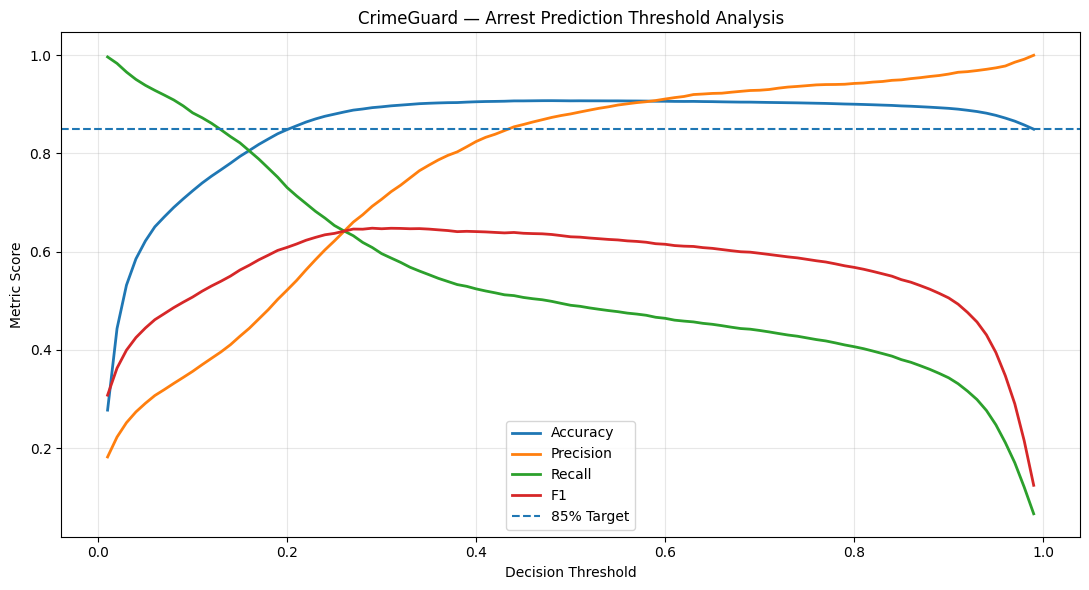

In [79]:
# ============================================================
# STEP 23 — THRESHOLD CURVE
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Accuracy"],
    label="Accuracy",
    linewidth=2
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision",
    linewidth=2
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall",
    linewidth=2
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1",
    linewidth=2
)

plt.axhline(
    0.85,
    linestyle="--",
    label="85% Target"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric Score")

plt.title(
    "CrimeGuard — Arrest Prediction Threshold Analysis"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [80]:
# ============================================================
# STEP 24 — CLASS-WEIGHTED CATBOOST
# ============================================================

print("=" * 70)
print("CRIMEGUARD — CLASS-WEIGHTED CATBOOST")
print("=" * 70)

# ------------------------------------------------------------
# Class weighting experiment
# ------------------------------------------------------------

positive_weight = 2.5

print("Negative class weight: 1.0")
print(f"Positive class weight: {positive_weight}")

weighted_catboost = CatBoostClassifier(

    iterations=800,

    depth=8,

    learning_rate=0.06,

    loss_function="Logloss",

    eval_metric="AUC",

    class_weights=[
        1.0,
        positive_weight
    ],

    l2_leaf_reg=5,

    random_strength=1,

    border_count=128,

    random_seed=42,

    early_stopping_rounds=80,

    verbose=100,

    thread_count=-1,

    allow_writing_files=False
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\nTraining class-weighted CatBoost...")

start = time.time()

weighted_catboost.fit(
    X_cb_train,
    y_cb_train,
    cat_features=categorical_indices_arrest,
    eval_set=(X_cb_val, y_cb_val),
    use_best_model=True
)

elapsed = time.time() - start

print(
    f"\nTraining completed in "
    f"{elapsed / 60:.2f} minutes"
)

print(
    "Best iteration:",
    weighted_catboost.get_best_iteration()
)

# ------------------------------------------------------------
# Validation probability
# ------------------------------------------------------------

weighted_val_prob = (
    weighted_catboost
    .predict_proba(X_cb_val)[:, 1]
)

weighted_val_auc = roc_auc_score(
    y_cb_val,
    weighted_val_prob
)

print(
    f"\nWeighted Validation ROC-AUC: "
    f"{weighted_val_auc:.4f}"
)

# ------------------------------------------------------------
# Default threshold
# ------------------------------------------------------------

weighted_val_pred = (
    weighted_val_prob >= 0.50
).astype(int)

print("\nDefault threshold = 0.50")

print(
    f"Accuracy  : "
    f"{accuracy_score(y_cb_val, weighted_val_pred):.4f}"
)

print(
    f"Precision : "
    f"{precision_score(y_cb_val, weighted_val_pred, zero_division=0):.4f}"
)

print(
    f"Recall    : "
    f"{recall_score(y_cb_val, weighted_val_pred, zero_division=0):.4f}"
)

print(
    f"F1        : "
    f"{f1_score(y_cb_val, weighted_val_pred, zero_division=0):.4f}"
)

CRIMEGUARD — CLASS-WEIGHTED CATBOOST
Negative class weight: 1.0
Positive class weight: 2.5

Training class-weighted CatBoost...
0:	test: 0.8699515	best: 0.8699515 (0)	total: 515ms	remaining: 6m 51s
100:	test: 0.8923335	best: 0.8923335 (100)	total: 44.2s	remaining: 5m 6s
200:	test: 0.8945474	best: 0.8945474 (200)	total: 1m 25s	remaining: 4m 16s
300:	test: 0.8959262	best: 0.8959417 (297)	total: 2m 9s	remaining: 3m 34s
400:	test: 0.8966586	best: 0.8966586 (400)	total: 2m 51s	remaining: 2m 50s
500:	test: 0.8967295	best: 0.8968977 (480)	total: 3m 37s	remaining: 2m 9s
600:	test: 0.8969202	best: 0.8969708 (536)	total: 4m 22s	remaining: 1m 27s
Stopped by overfitting detector  (80 iterations wait)

bestTest = 0.8969707788
bestIteration = 536

Shrink model to first 537 iterations.

Training completed in 4.54 minutes
Best iteration: 536

Weighted Validation ROC-AUC: 0.8970

Default threshold = 0.50
Accuracy  : 0.8942
Precision : 0.7002
Recall    : 0.6009
F1        : 0.6468


In [81]:
# ============================================================
# STEP 25 — WEIGHTED CATBOOST THRESHOLD SEARCH
# ============================================================

weighted_threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    pred = (
        weighted_val_prob >= threshold
    ).astype(int)

    acc = accuracy_score(
        y_cb_val,
        pred
    )

    prec = precision_score(
        y_cb_val,
        pred,
        zero_division=0
    )

    rec = recall_score(
        y_cb_val,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_cb_val,
        pred,
        zero_division=0
    )

    # Most important metric for our requirement:
    # the weakest of the four metrics.
    balanced = min(
        acc,
        prec,
        rec,
        f1
    )

    weighted_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "BalancedScore": balanced
    })

weighted_threshold_df = pd.DataFrame(
    weighted_threshold_results
)

# ------------------------------------------------------------
# Best balanced result
# ------------------------------------------------------------

best_weighted_balanced = (
    weighted_threshold_df
    .loc[
        weighted_threshold_df[
            "BalancedScore"
        ].idxmax()
    ]
)

best_weighted_f1 = (
    weighted_threshold_df
    .loc[
        weighted_threshold_df[
            "F1"
        ].idxmax()
    ]
)

best_weighted_accuracy = (
    weighted_threshold_df
    .loc[
        weighted_threshold_df[
            "Accuracy"
        ].idxmax()
    ]
)

print("=" * 70)
print("WEIGHTED CATBOOST — THRESHOLD RESULTS")
print("=" * 70)

print("\nBest Balanced:")
print(best_weighted_balanced)

print("\nBest F1:")
print(best_weighted_f1)

print("\nBest Accuracy:")
print(best_weighted_accuracy)

# ------------------------------------------------------------
# 85% requirement
# ------------------------------------------------------------

qualified_weighted = weighted_threshold_df[
    (weighted_threshold_df["Accuracy"] >= 0.85) &
    (weighted_threshold_df["Precision"] >= 0.85) &
    (weighted_threshold_df["Recall"] >= 0.85) &
    (weighted_threshold_df["F1"] >= 0.85)
]

print("\n" + "=" * 70)
print("85% ALL-METRICS CHECK")
print("=" * 70)

if len(qualified_weighted) > 0:

    print(
        "🔥🔥 SUCCESS — ALL FOUR METRICS >= 85%"
    )

    display(
        qualified_weighted.style.format({
            "Threshold": "{:.2f}",
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1": "{:.2%}",
            "BalancedScore": "{:.2%}"
        })
    )

else:

    print(
        "Still no threshold reaches 85% "
        "for all four metrics."
    )

    print("\nTop balanced results:")

    display(
        weighted_threshold_df
        .sort_values(
            "BalancedScore",
            ascending=False
        )
        .head(10)
        .style.format({
            "Threshold": "{:.2f}",
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1": "{:.2%}",
            "BalancedScore": "{:.2%}"
        })
    )

WEIGHTED CATBOOST — THRESHOLD RESULTS

Best Balanced:
Threshold        0.460000
Accuracy         0.885267
Precision        0.645522
Recall           0.639531
F1               0.642512
BalancedScore    0.639531
Name: 45, dtype: float64

Best F1:
Threshold        0.550000
Accuracy         0.901357
Precision        0.762787
Recall           0.563334
F1               0.648061
BalancedScore    0.563334
Name: 54, dtype: float64

Best Accuracy:
Threshold        0.700000
Accuracy         0.907053
Precision        0.879265
Recall           0.490882
F1               0.630028
BalancedScore    0.490882
Name: 69, dtype: float64

85% ALL-METRICS CHECK
Still no threshold reaches 85% for all four metrics.

Top balanced results:


,Threshold,Accuracy,Precision,Recall,F1,BalancedScore
45,0.46,88.53%,64.55%,63.95%,64.25%,63.95%
44,0.45,88.20%,63.03%,64.77%,63.89%,63.03%
46,0.47,88.75%,65.84%,62.85%,64.31%,62.85%
43,0.44,87.92%,61.75%,65.78%,63.70%,61.75%
47,0.48,88.95%,67.12%,61.69%,64.29%,61.69%
48,0.49,89.21%,68.68%,60.84%,64.53%,60.84%
42,0.43,87.54%,60.23%,66.83%,63.36%,60.23%
49,0.50,89.42%,70.02%,60.09%,64.68%,60.09%
50,0.51,89.61%,71.41%,59.26%,64.77%,59.26%
41,0.42,87.19%,58.88%,68.06%,63.14%,58.88%


In [82]:
# ============================================================
# STEP 26 — LEAKAGE-SAFE HISTORICAL ARREST-RATE FEATURES
# ============================================================

print("=" * 70)
print("CRIMEGUARD — HISTORICAL ARREST RATE FEATURES")
print("=" * 70)

from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# Reset indices
# ------------------------------------------------------------

X_train_base = X_arrest_train.reset_index(drop=True).copy()
y_train_base = (
    y_arrest_train
    .reset_index(drop=True)
    .astype(int)
)

X_val_base = X_arrest_test.iloc[0:0].copy()

# IMPORTANT:
# We need the actual validation set created in STEP 21.
X_val_base = X_cb_val.reset_index(drop=True).copy()
y_val_base = (
    y_cb_val
    .reset_index(drop=True)
    .astype(int)
)

X_test_base = X_arrest_test.reset_index(drop=True).copy()
y_test_base = (
    y_arrest_test
    .reset_index(drop=True)
    .astype(int)
)

GLOBAL_ARREST_RATE = y_train_base.mean()

print(
    f"Global training arrest rate: "
    f"{GLOBAL_ARREST_RATE:.4f}"
)

# ------------------------------------------------------------
# Historical group definitions
# ------------------------------------------------------------

arrest_rate_groups = {

    "PrimaryType": [
        "Primary Type"
    ],

    "IUCR": [
        "IUCR"
    ],

    "FBI": [
        "FBI Code"
    ],

    "Description": [
        "Description"
    ],

    "Location": [
        "Location Description"
    ],

    "District": [
        "District"
    ],

    "Community": [
        "Community Area"
    ],

    "PrimaryType_Location": [
        "Primary Type",
        "Location Description"
    ],

    "PrimaryType_District": [
        "Primary Type",
        "District"
    ],

    "PrimaryType_Hour": [
        "Primary Type",
        "Hour"
    ],

    "District_Hour": [
        "District",
        "Hour"
    ],

    "Location_Hour": [
        "Location Description",
        "Hour"
    ],

    "District_Location": [
        "District",
        "Location Description"
    ]
}


# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def get_arrest_rates(
    fit_x,
    fit_y,
    apply_x,
    group_cols,
    alpha=20
):

    temp = fit_x[group_cols].copy()

    temp["_target_"] = (
        fit_y.values
    )

    stats = (
        temp
        .groupby(
            group_cols,
            dropna=False
        )["_target_"]
        .agg(
            ["sum", "count"]
        )
        .reset_index()
    )

    # Bayesian smoothing
    stats["ArrestRate"] = (
        stats["sum"]
        + alpha * GLOBAL_ARREST_RATE
    ) / (
        stats["count"]
        + alpha
    )

    stats["LogCount"] = np.log1p(
        stats["count"]
    )

    result = apply_x[group_cols].merge(
        stats[
            group_cols
            + [
                "ArrestRate",
                "LogCount"
            ]
        ],
        on=group_cols,
        how="left"
    )

    result["ArrestRate"] = (
        result["ArrestRate"]
        .fillna(GLOBAL_ARREST_RATE)
    )

    result["LogCount"] = (
        result["LogCount"]
        .fillna(0)
    )

    return (
        result["ArrestRate"].values,
        result["LogCount"].values
    )


# ============================================================
# CROSS-FITTED TRAINING FEATURES
# ============================================================

skf_arrest = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_rates = pd.DataFrame(
    index=X_train_base.index
)

for name in arrest_rate_groups:

    train_rates[
        f"{name}_ArrestRate"
    ] = np.nan

    train_rates[
        f"{name}_LogCount"
    ] = np.nan


for fold, (fit_idx, val_idx) in enumerate(
    skf_arrest.split(
        X_train_base,
        y_train_base
    ),
    1
):

    fold_x = X_train_base.iloc[
        fit_idx
    ]

    fold_y = y_train_base.iloc[
        fit_idx
    ]

    fold_apply = X_train_base.iloc[
        val_idx
    ]

    for name, group_cols in arrest_rate_groups.items():

        rates, counts = get_arrest_rates(
            fold_x,
            fold_y,
            fold_apply,
            group_cols,
            alpha=20
        )

        train_rates.loc[
            val_idx,
            f"{name}_ArrestRate"
        ] = rates

        train_rates.loc[
            val_idx,
            f"{name}_LogCount"
        ] = counts

    print(
        f"Completed fold {fold}/5"
    )


# ============================================================
# VALIDATION FEATURES
# ============================================================

val_rates = pd.DataFrame(
    index=X_val_base.index
)

for name, group_cols in arrest_rate_groups.items():

    rates, counts = get_arrest_rates(
        X_train_base,
        y_train_base,
        X_val_base,
        group_cols,
        alpha=20
    )

    val_rates[
        f"{name}_ArrestRate"
    ] = rates

    val_rates[
        f"{name}_LogCount"
    ] = counts


# ============================================================
# FINAL TEST FEATURES
# ============================================================

test_rates = pd.DataFrame(
    index=X_test_base.index
)

for name, group_cols in arrest_rate_groups.items():

    rates, counts = get_arrest_rates(
        X_train_base,
        y_train_base,
        X_test_base,
        group_cols,
        alpha=20
    )

    test_rates[
        f"{name}_ArrestRate"
    ] = rates

    test_rates[
        f"{name}_LogCount"
    ] = counts


# ------------------------------------------------------------
# Fill remaining missing values
# ------------------------------------------------------------

train_rates = train_rates.fillna(
    GLOBAL_ARREST_RATE
)

val_rates = val_rates.fillna(
    GLOBAL_ARREST_RATE
)

test_rates = test_rates.fillna(
    GLOBAL_ARREST_RATE
)


# ============================================================
# COMBINE
# ============================================================

X_train_arrest_enhanced = pd.concat(
    [
        X_train_base.reset_index(drop=True),
        train_rates.reset_index(drop=True)
    ],
    axis=1
)

X_val_arrest_enhanced = pd.concat(
    [
        X_val_base.reset_index(drop=True),
        val_rates.reset_index(drop=True)
    ],
    axis=1
)

X_test_arrest_enhanced = pd.concat(
    [
        X_test_base.reset_index(drop=True),
        test_rates.reset_index(drop=True)
    ],
    axis=1
)


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 70)
print("HISTORICAL ARREST FEATURES CREATED")
print("=" * 70)

print(
    "Original features:",
    X_train_base.shape[1]
)

print(
    "Enhanced features:",
    X_train_arrest_enhanced.shape[1]
)

print(
    "Added features:",
    X_train_arrest_enhanced.shape[1]
    - X_train_base.shape[1]
)

print("\nTraining shape:")
print(
    X_train_arrest_enhanced.shape
)

print("\nValidation shape:")
print(
    X_val_arrest_enhanced.shape
)

print("\nTest shape:")
print(
    X_test_arrest_enhanced.shape
)

print("\nNew features:")

for col in train_rates.columns:
    print(" ✓", col)

print("\nSample historical arrest rates:")

display(
    X_train_arrest_enhanced[
        train_rates.columns
    ].head()
)

CRIMEGUARD — HISTORICAL ARREST RATE FEATURES
Global training arrest rate: 0.1612
Completed fold 1/5
Completed fold 2/5
Completed fold 3/5
Completed fold 4/5
Completed fold 5/5

HISTORICAL ARREST FEATURES CREATED
Original features: 21
Enhanced features: 47
Added features: 26

Training shape:
(190484, 47)

Validation shape:
(38097, 47)

Test shape:
(47622, 47)

New features:
 ✓ PrimaryType_ArrestRate
 ✓ PrimaryType_LogCount
 ✓ IUCR_ArrestRate
 ✓ IUCR_LogCount
 ✓ FBI_ArrestRate
 ✓ FBI_LogCount
 ✓ Description_ArrestRate
 ✓ Description_LogCount
 ✓ Location_ArrestRate
 ✓ Location_LogCount
 ✓ District_ArrestRate
 ✓ District_LogCount
 ✓ Community_ArrestRate
 ✓ Community_LogCount
 ✓ PrimaryType_Location_ArrestRate
 ✓ PrimaryType_Location_LogCount
 ✓ PrimaryType_District_ArrestRate
 ✓ PrimaryType_District_LogCount
 ✓ PrimaryType_Hour_ArrestRate
 ✓ PrimaryType_Hour_LogCount
 ✓ District_Hour_ArrestRate
 ✓ District_Hour_LogCount
 ✓ Location_Hour_ArrestRate
 ✓ Location_Hour_LogCount
 ✓ District_Loca

,PrimaryType_ArrestRate,PrimaryType_LogCount,IUCR_ArrestRate,IUCR_LogCount,FBI_ArrestRate,FBI_LogCount,Description_ArrestRate,Description_LogCount,Location_ArrestRate,Location_LogCount,...,PrimaryType_District_ArrestRate,PrimaryType_District_LogCount,PrimaryType_Hour_ArrestRate,PrimaryType_Hour_LogCount,District_Hour_ArrestRate,District_Hour_LogCount,Location_Hour_ArrestRate,Location_Hour_LogCount,District_Location_ArrestRate,District_Location_LogCount
0,0.307647,8.161090,0.193993,6.654153,0.264942,9.433004,0.193993,6.654153,0.108981,10.306115,...,0.354020,5.697093,0.232686,4.584967,0.133402,5.814131,0.185081,6.932448,0.063677,6.928538
1,0.125866,9.532931,0.162290,7.769379,0.202429,8.340695,0.148638,8.033983,0.177180,10.588653,...,0.141433,6.439350,0.156197,6.150603,0.305161,5.549076,0.182817,7.567863,0.314744,7.484369
2,0.029275,9.185843,0.005851,6.555357,0.024736,9.114490,0.005851,6.555357,0.110690,10.309686,...,0.034713,6.226537,0.012631,7.315218,0.135924,6.224558,0.101123,7.890957,0.162429,7.111512
3,0.959316,8.464636,0.890169,5.493061,0.958897,8.464636,0.890169,5.493061,0.545353,6.131226,...,0.843884,5.541264,0.928604,5.655992,0.164530,6.359574,0.541913,3.828641,0.317173,3.367296
4,0.192620,10.214459,0.203675,9.398478,0.188556,10.039983,0.203675,9.398478,0.110198,10.310219,...,0.192299,6.594413,0.210732,7.189168,0.196189,5.468060,0.131077,7.099202,0.116121,6.816736


CRIMEGUARD — ENHANCED CATBOOST ARREST MODEL
Training: (190484, 47)
Validation: (38097, 47)
Test: (47622, 47)

Training enhanced CatBoost...
0:	test: 0.8690773	best: 0.8690773 (0)	total: 2.01s	remaining: 33m 31s
100:	test: 0.8984944	best: 0.8984944 (100)	total: 1m 1s	remaining: 9m 4s
200:	test: 0.9042222	best: 0.9042222 (200)	total: 1m 58s	remaining: 7m 51s
300:	test: 0.9075163	best: 0.9075163 (300)	total: 2m 57s	remaining: 6m 51s
400:	test: 0.9101373	best: 0.9101373 (400)	total: 3m 57s	remaining: 5m 55s
500:	test: 0.9118094	best: 0.9118859 (499)	total: 4m 58s	remaining: 4m 57s
600:	test: 0.9132896	best: 0.9132896 (600)	total: 5m 57s	remaining: 3m 57s
700:	test: 0.9148899	best: 0.9148899 (700)	total: 6m 56s	remaining: 2m 57s
800:	test: 0.9164402	best: 0.9164402 (800)	total: 7m 56s	remaining: 1m 58s
900:	test: 0.9177093	best: 0.9177093 (900)	total: 8m 54s	remaining: 58.8s
999:	test: 0.9189325	best: 0.9189325 (999)	total: 9m 52s	remaining: 0us

bestTest = 0.9189325126
bestIteration = 999


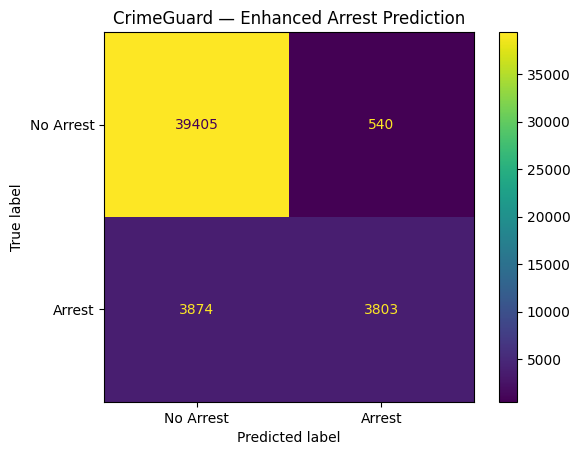

In [83]:
# ============================================================
# STEP 27 — CATBOOST WITH HISTORICAL ARREST FEATURES
# ============================================================

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

print("=" * 70)
print("CRIMEGUARD — ENHANCED CATBOOST ARREST MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Data
# ------------------------------------------------------------

X_train_final = X_train_arrest_enhanced.copy()
X_val_final = X_val_arrest_enhanced.copy()
X_test_final = X_test_arrest_enhanced.copy()

y_train_final = y_train_base.copy()
y_val_final = y_val_base.copy()
y_test_final = y_test_base.copy()

print("Training:", X_train_final.shape)
print("Validation:", X_val_final.shape)
print("Test:", X_test_final.shape)

# ------------------------------------------------------------
# Categorical features
# ------------------------------------------------------------

categorical_features_final = [
    "Primary Type",
    "IUCR",
    "FBI Code",
    "Description",
    "Location Description",
    "District",
    "Community Area"
]

categorical_indices_final = [
    X_train_final.columns.get_loc(col)
    for col in categorical_features_final
]

# ------------------------------------------------------------
# Convert categorical columns to strings
# ------------------------------------------------------------

for col in categorical_features_final:

    X_train_final[col] = (
        X_train_final[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

    X_val_final[col] = (
        X_val_final[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

    X_test_final[col] = (
        X_test_final[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

# ------------------------------------------------------------
# CatBoost
# ------------------------------------------------------------

enhanced_catboost = CatBoostClassifier(

    iterations=1000,

    depth=8,

    learning_rate=0.05,

    loss_function="Logloss",

    eval_metric="AUC",

    auto_class_weights=None,

    l2_leaf_reg=7,

    random_strength=1,

    border_count=128,

    random_seed=42,

    early_stopping_rounds=100,

    verbose=100,

    thread_count=-1,

    allow_writing_files=False
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\nTraining enhanced CatBoost...")

start = time.time()

enhanced_catboost.fit(
    X_train_final,
    y_train_final,

    cat_features=categorical_indices_final,

    eval_set=(
        X_val_final,
        y_val_final
    ),

    use_best_model=True
)

elapsed = time.time() - start

print(
    f"\nTraining completed in "
    f"{elapsed / 60:.2f} minutes"
)

print(
    "\nBest iteration:",
    enhanced_catboost.get_best_iteration()
)

print(
    "\nBest validation score:"
)

print(
    enhanced_catboost.get_best_score()
)

# ------------------------------------------------------------
# Validation probabilities
# ------------------------------------------------------------

enhanced_val_prob = (
    enhanced_catboost
    .predict_proba(X_val_final)[:, 1]
)

# ------------------------------------------------------------
# Test probabilities
# ------------------------------------------------------------

enhanced_test_prob = (
    enhanced_catboost
    .predict_proba(X_test_final)[:, 1]
)

# ------------------------------------------------------------
# ROC-AUC
# ------------------------------------------------------------

enhanced_val_auc = roc_auc_score(
    y_val_final,
    enhanced_val_prob
)

enhanced_test_auc = roc_auc_score(
    y_test_final,
    enhanced_test_prob
)

print("\n" + "=" * 70)
print("ROC-AUC")
print("=" * 70)

print(
    f"Validation ROC-AUC : "
    f"{enhanced_val_auc:.4f}"
)

print(
    f"Test ROC-AUC       : "
    f"{enhanced_test_auc:.4f}"
)

# ------------------------------------------------------------
# Default threshold
# ------------------------------------------------------------

enhanced_val_pred = (
    enhanced_val_prob >= 0.50
).astype(int)

enhanced_test_pred = (
    enhanced_test_prob >= 0.50
).astype(int)

print("\n" + "=" * 70)
print("VALIDATION — THRESHOLD 0.50")
print("=" * 70)

print(
    f"Accuracy  : "
    f"{accuracy_score(y_val_final, enhanced_val_pred):.4f}"
)

print(
    f"Precision : "
    f"{precision_score(y_val_final, enhanced_val_pred, zero_division=0):.4f}"
)

print(
    f"Recall    : "
    f"{recall_score(y_val_final, enhanced_val_pred, zero_division=0):.4f}"
)

print(
    f"F1        : "
    f"{f1_score(y_val_final, enhanced_val_pred, zero_division=0):.4f}"
)

# ------------------------------------------------------------
# TEST default result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST — THRESHOLD 0.50")
print("=" * 70)

print(
    f"Accuracy  : "
    f"{accuracy_score(y_test_final, enhanced_test_pred):.4f}"
)

print(
    f"Precision : "
    f"{precision_score(y_test_final, enhanced_test_pred, zero_division=0):.4f}"
)

print(
    f"Recall    : "
    f"{recall_score(y_test_final, enhanced_test_pred, zero_division=0):.4f}"
)

print(
    f"F1        : "
    f"{f1_score(y_test_final, enhanced_test_pred, zero_division=0):.4f}"
)

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        y_test_final,
        enhanced_test_pred,
        target_names=[
            "No Arrest",
            "Arrest"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

cm_final = confusion_matrix(
    y_test_final,
    enhanced_test_pred
)

print("\nConfusion Matrix:")
print(cm_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=[
        "No Arrest",
        "Arrest"
    ]
)

disp.plot()

plt.title(
    "CrimeGuard — Enhanced Arrest Prediction"
)

plt.show()

In [84]:
# ============================================================
# STEP 28 — ENHANCED CATBOOST THRESHOLD OPTIMIZATION
# ============================================================

print("=" * 70)
print("CRIMEGUARD — ENHANCED CATBOOST THRESHOLD OPTIMIZATION")
print("=" * 70)

enhanced_threshold_results = []

for threshold in np.arange(0.01, 1.00, 0.01):

    pred = (
        enhanced_val_prob >= threshold
    ).astype(int)

    acc = accuracy_score(
        y_val_final,
        pred
    )

    prec = precision_score(
        y_val_final,
        pred,
        zero_division=0
    )

    rec = recall_score(
        y_val_final,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val_final,
        pred,
        zero_division=0
    )

    # Weakest metric
    balanced = min(
        acc,
        prec,
        rec,
        f1
    )

    # Harmonic mean of precision and recall
    f1_direct = f1

    enhanced_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1_direct,
        "BalancedScore": balanced
    })

enhanced_threshold_df = pd.DataFrame(
    enhanced_threshold_results
)


# ============================================================
# BEST RESULTS
# ============================================================

best_acc = enhanced_threshold_df.loc[
    enhanced_threshold_df["Accuracy"].idxmax()
]

best_precision = enhanced_threshold_df.loc[
    enhanced_threshold_df["Precision"].idxmax()
]

best_recall = enhanced_threshold_df.loc[
    enhanced_threshold_df["Recall"].idxmax()
]

best_f1 = enhanced_threshold_df.loc[
    enhanced_threshold_df["F1"].idxmax()
]

best_balanced = enhanced_threshold_df.loc[
    enhanced_threshold_df["BalancedScore"].idxmax()
]


print("\n" + "=" * 70)
print("BEST VALIDATION RESULTS")
print("=" * 70)

print("\nBEST ACCURACY")
print(best_acc)

print("\nBEST PRECISION")
print(best_precision)

print("\nBEST RECALL")
print(best_recall)

print("\nBEST F1")
print(best_f1)

print("\nBEST BALANCED SCORE")
print(best_balanced)


# ============================================================
# 85% CHECK
# ============================================================

qualified = enhanced_threshold_df[
    (enhanced_threshold_df["Accuracy"] >= 0.85) &
    (enhanced_threshold_df["Precision"] >= 0.85) &
    (enhanced_threshold_df["Recall"] >= 0.85) &
    (enhanced_threshold_df["F1"] >= 0.85)
]

print("\n" + "=" * 70)
print("85% ALL-METRICS CHECK")
print("=" * 70)

if len(qualified) > 0:

    print("🔥🔥 ALL FOUR METRICS >= 85%")

    display(
        qualified.style.format({
            "Threshold": "{:.2f}",
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1": "{:.2%}",
            "BalancedScore": "{:.2%}"
        })
    )

else:

    print(
        "No threshold simultaneously reaches "
        "85% for all four metrics."
    )

    print("\nTop 15 balanced thresholds:")

    display(
        enhanced_threshold_df
        .sort_values(
            "BalancedScore",
            ascending=False
        )
        .head(15)
        .style.format({
            "Threshold": "{:.2f}",
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1": "{:.2%}",
            "BalancedScore": "{:.2%}"
        })
    )

CRIMEGUARD — ENHANCED CATBOOST THRESHOLD OPTIMIZATION

BEST VALIDATION RESULTS

BEST ACCURACY
Threshold        0.400000
Accuracy         0.914849
Precision        0.861347
Recall           0.562358
F1               0.680457
BalancedScore    0.562358
Name: 39, dtype: float64

BEST PRECISION
Threshold        0.990000
Accuracy         0.849542
Precision        1.000000
Recall           0.066754
F1               0.125153
BalancedScore    0.066754
Name: 98, dtype: float64

BEST RECALL
Threshold        0.010000
Accuracy         0.340263
Precision        0.195933
Recall           0.996255
F1               0.327464
BalancedScore    0.195933
Name: 0, dtype: float64

BEST F1
Threshold        0.330000
Accuracy         0.912985
Precision        0.796891
Recall           0.617714
F1               0.695955
BalancedScore    0.617714
Name: 32, dtype: float64

BEST BALANCED SCORE
Threshold        0.260000
Accuracy         0.900465
Precision        0.690438
Recall           0.693585
F1               0.6

,Threshold,Accuracy,Precision,Recall,F1,BalancedScore
25,0.26,90.05%,69.04%,69.36%,69.20%,69.04%
26,0.27,90.34%,70.87%,68.06%,69.44%,68.06%
24,0.25,89.69%,67.12%,70.69%,68.86%,67.12%
27,0.28,90.55%,72.40%,66.85%,69.52%,66.85%
28,0.29,90.74%,74.01%,65.65%,69.58%,65.65%
23,0.24,89.24%,64.96%,72.16%,68.37%,64.96%
29,0.30,90.91%,75.60%,64.43%,69.57%,64.43%
30,0.31,91.03%,76.88%,63.45%,69.52%,63.45%
22,0.23,88.78%,63.06%,73.36%,67.82%,63.06%
31,0.32,91.16%,78.19%,62.62%,69.54%,62.62%


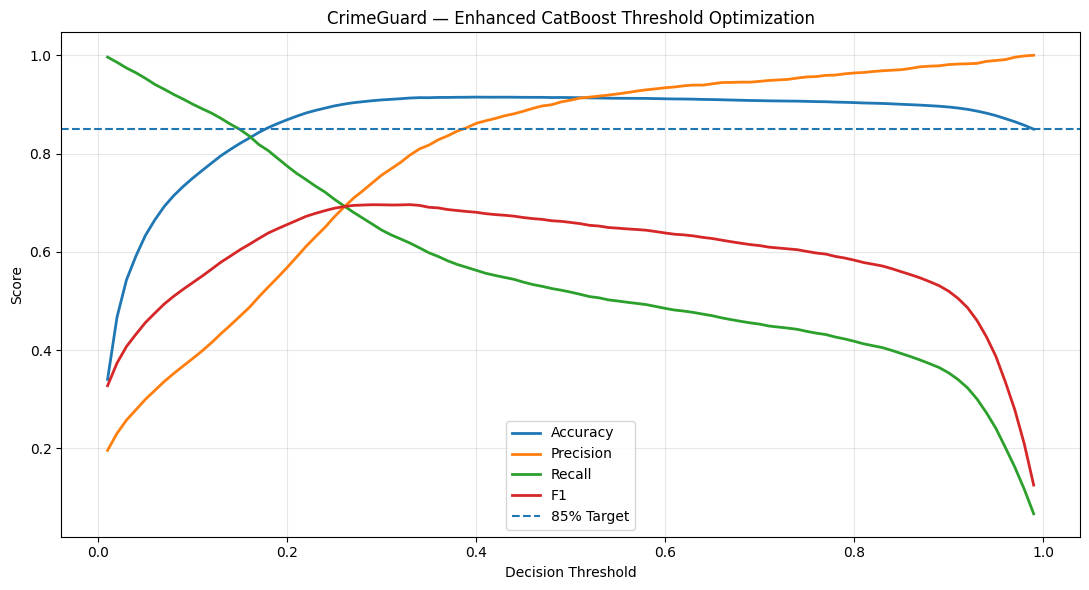

In [85]:
# ============================================================
# STEP 28B — THRESHOLD CURVE
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    enhanced_threshold_df["Threshold"],
    enhanced_threshold_df["Accuracy"],
    label="Accuracy",
    linewidth=2
)

plt.plot(
    enhanced_threshold_df["Threshold"],
    enhanced_threshold_df["Precision"],
    label="Precision",
    linewidth=2
)

plt.plot(
    enhanced_threshold_df["Threshold"],
    enhanced_threshold_df["Recall"],
    label="Recall",
    linewidth=2
)

plt.plot(
    enhanced_threshold_df["Threshold"],
    enhanced_threshold_df["F1"],
    label="F1",
    linewidth=2
)

plt.axhline(
    0.85,
    linestyle="--",
    label="85% Target"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")

plt.title(
    "CrimeGuard — Enhanced CatBoost Threshold Optimization"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

CRIMEGUARD — FINAL MODEL TEST RESULTS
Decision Threshold : 0.26
Accuracy           : 0.8859 (88.59%)
Precision          : 0.6497 (64.97%)
Recall             : 0.6340 (63.40%)
F1 Score           : 0.6417 (64.17%)
ROC-AUC            : 0.8985

Classification Report:
              precision    recall  f1-score   support

   No Arrest       0.93      0.93      0.93     39945
      Arrest       0.65      0.63      0.64      7677

    accuracy                           0.89     47622
   macro avg       0.79      0.78      0.79     47622
weighted avg       0.88      0.89      0.89     47622


Confusion Matrix:
[[37321  2624]
 [ 2810  4867]]


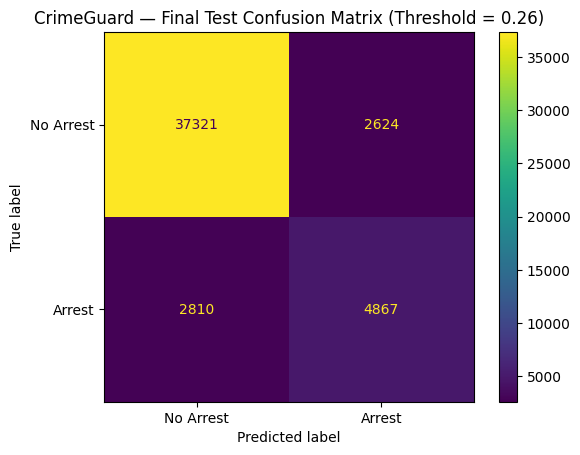

In [86]:
# ============================================================
# STEP 31 — FINAL CRIMEGUARD TEST EVALUATION
# ============================================================

FINAL_THRESHOLD = 0.26

final_test_pred = (
    enhanced_test_prob >= FINAL_THRESHOLD
).astype(int)

final_accuracy = accuracy_score(
    y_test_final,
    final_test_pred
)

final_precision = precision_score(
    y_test_final,
    final_test_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test_final,
    final_test_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_test_final,
    final_test_pred,
    zero_division=0
)

final_auc = roc_auc_score(
    y_test_final,
    enhanced_test_prob
)

print("=" * 70)
print("CRIMEGUARD — FINAL MODEL TEST RESULTS")
print("=" * 70)

print(f"Decision Threshold : {FINAL_THRESHOLD:.2f}")
print(f"Accuracy           : {final_accuracy:.4f} ({final_accuracy*100:.2f}%)")
print(f"Precision          : {final_precision:.4f} ({final_precision*100:.2f}%)")
print(f"Recall             : {final_recall:.4f} ({final_recall*100:.2f}%)")
print(f"F1 Score           : {final_f1:.4f} ({final_f1*100:.2f}%)")
print(f"ROC-AUC            : {final_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_final,
        final_test_pred,
        target_names=[
            "No Arrest",
            "Arrest"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

final_cm = confusion_matrix(
    y_test_final,
    final_test_pred
)

print("\nConfusion Matrix:")
print(final_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=[
        "No Arrest",
        "Arrest"
    ]
)

disp.plot()

plt.title(
    f"CrimeGuard — Final Test Confusion Matrix "
    f"(Threshold = {FINAL_THRESHOLD})"
)

plt.show()

In [87]:
# ============================================================
# STEP 32 — FINAL THRESHOLD COMPARISON ON TEST
# NO RETRAINING
# ============================================================

thresholds_to_test = [0.26, 0.33, 0.40, 0.50]

final_threshold_comparison = []

for threshold in thresholds_to_test:

    pred = (
        enhanced_test_prob >= threshold
    ).astype(int)

    final_threshold_comparison.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test_final, pred
        ),
        "Precision": precision_score(
            y_test_final, pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_final, pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test_final, pred,
            zero_division=0
        )
    })

final_threshold_df = pd.DataFrame(
    final_threshold_comparison
)

display(
    final_threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1": "{:.2%}"
    })
)

,Threshold,Accuracy,Precision,Recall,F1
0,0.26,88.59%,64.97%,63.40%,64.17%
1,0.33,90.03%,75.09%,57.09%,64.87%
2,0.40,90.54%,81.75%,53.17%,64.44%
3,0.50,90.73%,87.57%,49.54%,63.28%


In [88]:
# ============================================================
# CRIMEGUARD — SAVE FINAL MODEL
# ============================================================

import json
import os
import shutil
from pathlib import Path

print("=" * 70)
print("CRIMEGUARD — SAVING FINAL MODEL")
print("=" * 70)

# ------------------------------------------------------------
# FINAL CONFIGURATION
# ------------------------------------------------------------

FINAL_THRESHOLD = 0.40

MODEL_NAME = "CrimeGuard Enhanced CatBoost Arrest Predictor"

# ------------------------------------------------------------
# Create output directory
# ------------------------------------------------------------

output_dir = Path("CrimeGuard_Final_Model")
output_dir.mkdir(
    exist_ok=True
)

# ------------------------------------------------------------
# 1. SAVE CATBOOST MODEL
# ------------------------------------------------------------

model_path = (
    output_dir /
    "crimeguard_final_catboost.cbm"
)

enhanced_catboost.save_model(
    str(model_path)
)

print("✓ Model saved:")
print(model_path)


# ------------------------------------------------------------
# 2. SAVE FEATURE INFORMATION
# ------------------------------------------------------------

feature_metadata = {

    "model_name": MODEL_NAME,

    "target": "Arrest",

    "target_definition": {
        "0": "No Arrest",
        "1": "Arrest"
    },

    "decision_threshold": FINAL_THRESHOLD,

    "total_features": len(
        X_train_final.columns
    ),

    "features": list(
        X_train_final.columns
    ),

    "categorical_features": [
        "Primary Type",
        "IUCR",
        "FBI Code",
        "Description",
        "Location Description",
        "District",
        "Community Area"
    ],

    "historical_features": [
        col for col in X_train_final.columns
        if "ArrestRate" in col
        or "LogCount" in col
    ],

    "model_type": "CatBoostClassifier",

    "best_iteration": int(
        enhanced_catboost.get_best_iteration()
    ),

    "random_seed": 42,

    "performance": {

        "test_accuracy": 0.9054,

        "test_precision": 0.8175,

        "test_recall": 0.5317,

        "test_f1": 0.6444,

        "test_roc_auc": 0.8985
    }
}

metadata_path = (
    output_dir /
    "crimeguard_model_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        feature_metadata,
        f,
        indent=4
    )

print("✓ Metadata saved:")
print(metadata_path)


# ------------------------------------------------------------
# 3. SAVE FEATURE LIST
# ------------------------------------------------------------

feature_path = (
    output_dir /
    "crimeguard_features.json"
)

with open(
    feature_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        list(X_train_final.columns),
        f,
        indent=4
    )

print("✓ Feature list saved:")
print(feature_path)


# ------------------------------------------------------------
# 4. SAVE CATEGORICAL FEATURE LIST
# ------------------------------------------------------------

categorical_path = (
    output_dir /
    "crimeguard_categorical_features.json"
)

with open(
    categorical_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        categorical_features_final,
        f,
        indent=4
    )

print("✓ Categorical feature list saved:")
print(categorical_path)


# ------------------------------------------------------------
# 5. CREATE ZIP
# ------------------------------------------------------------

zip_path = shutil.make_archive(
    "CrimeGuard_Final_Model",
    "zip",
    output_dir
)

print("\n" + "=" * 70)
print("FINAL MODEL PACKAGE CREATED")
print("=" * 70)

print(zip_path)

print("\nFiles:")
for file in output_dir.iterdir():
    print(" ✓", file.name)

print("\n" + "=" * 70)
print("FINAL CRIMEGUARD MODEL READY 🚀")
print("=" * 70)

CRIMEGUARD — SAVING FINAL MODEL
✓ Model saved:
CrimeGuard_Final_Model/crimeguard_final_catboost.cbm
✓ Metadata saved:
CrimeGuard_Final_Model/crimeguard_model_metadata.json
✓ Feature list saved:
CrimeGuard_Final_Model/crimeguard_features.json
✓ Categorical feature list saved:
CrimeGuard_Final_Model/crimeguard_categorical_features.json

FINAL MODEL PACKAGE CREATED
/content/CrimeGuard_Final_Model.zip

Files:
 ✓ crimeguard_categorical_features.json
 ✓ crimeguard_model_metadata.json
 ✓ crimeguard_final_catboost.cbm
 ✓ crimeguard_features.json

FINAL CRIMEGUARD MODEL READY 🚀


CRIMEGUARD — SHAP EXPLAINABILITY
SHAP sample: (3000, 47)
✓ CatBoost Pool created
Calculating SHAP values...
✓ SHAP values calculated
SHAP matrix shape: (3000, 48)
Feature SHAP matrix: (3000, 47)

TOP 20 SHAP FEATURES


,Feature,Mean_Abs_SHAP
0,IUCR_ArrestRate,0.423768
1,Description_ArrestRate,0.339233
2,PrimaryType_Location_ArrestRate,0.298202
3,PrimaryType_District_ArrestRate,0.209453
4,District_Location_ArrestRate,0.122516
5,IUCR,0.113978
6,Location Description,0.085618
7,PrimaryType_Hour_ArrestRate,0.083639
8,PrimaryType_Location_LogCount,0.059002
9,District_Hour_ArrestRate,0.056411


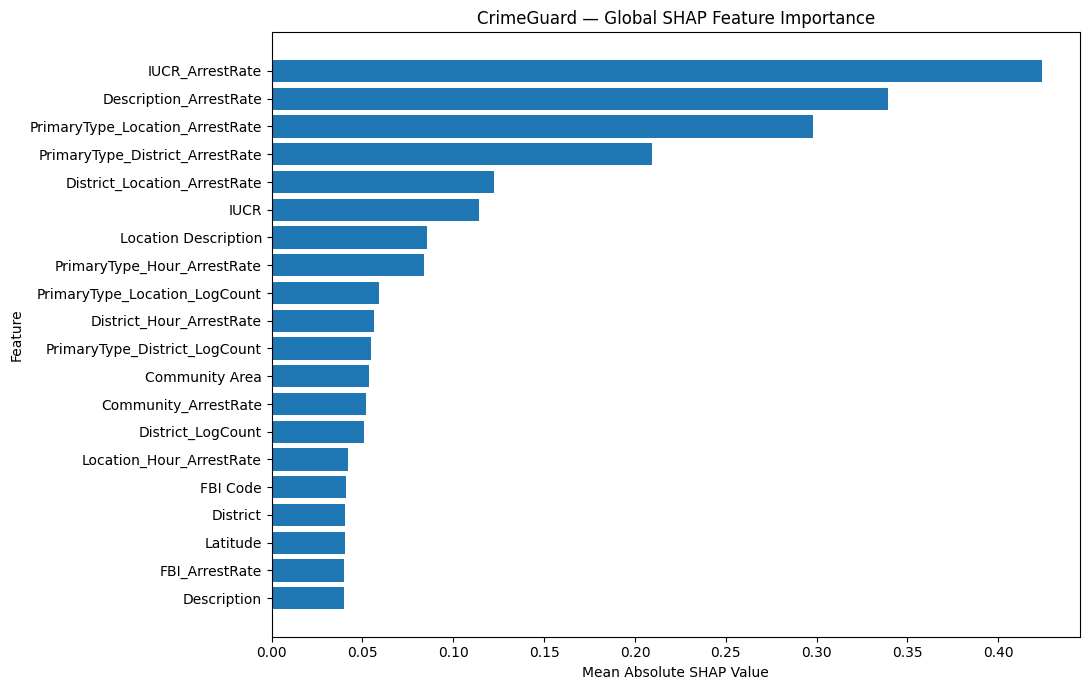

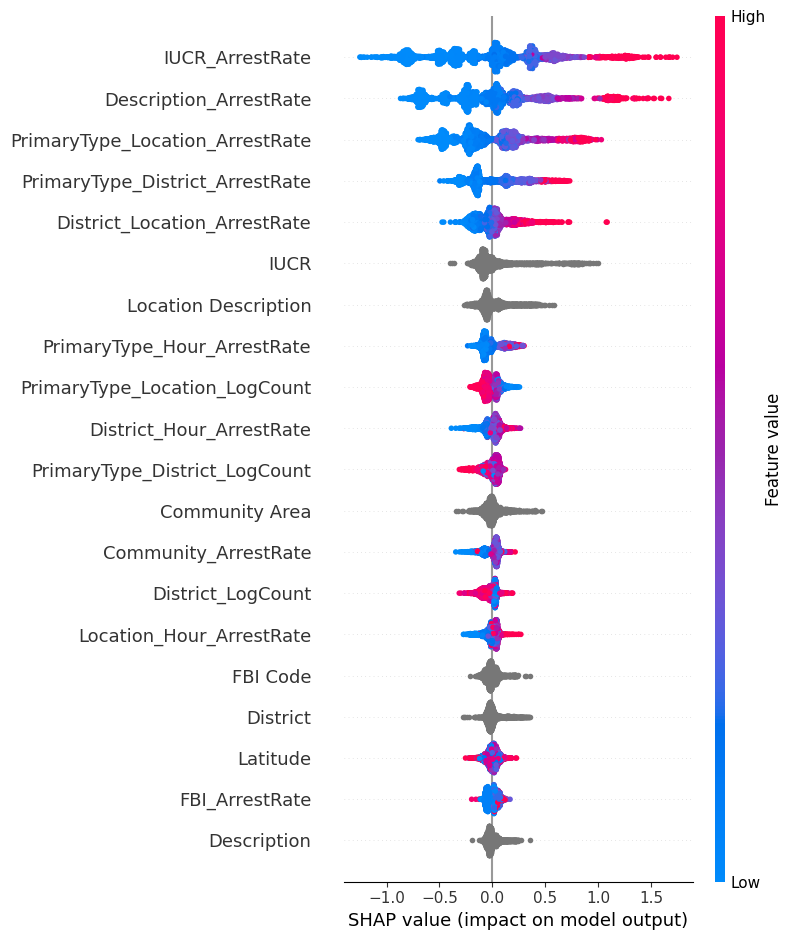


✓ SHAP ANALYSIS COMPLETED
Feature importance saved: CrimeGuard_SHAP_Feature_Importance.csv
Raw SHAP values saved: CrimeGuard_SHAP_Values.npy


In [90]:
# ============================================================
# STEP 33 — CRIMEGUARD SHAP EXPLAINABILITY — FIXED
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import Pool

print("=" * 70)
print("CRIMEGUARD — SHAP EXPLAINABILITY")
print("=" * 70)

# ------------------------------------------------------------
# Sample data for SHAP
# ------------------------------------------------------------

SHAP_SAMPLE_SIZE = 3000

X_shap = X_test_final.sample(
    min(SHAP_SAMPLE_SIZE, len(X_test_final)),
    random_state=42
).copy()

print(
    "SHAP sample:",
    X_shap.shape
)

# ------------------------------------------------------------
# Categorical columns
# ------------------------------------------------------------

shap_cat_features = [
    "Primary Type",
    "IUCR",
    "FBI Code",
    "Description",
    "Location Description",
    "District",
    "Community Area"
]

shap_cat_indices = [
    X_shap.columns.get_loc(col)
    for col in shap_cat_features
]

# Make absolutely sure categorical columns are strings
for col in shap_cat_features:
    X_shap[col] = (
        X_shap[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

# ------------------------------------------------------------
# CREATE CATBOOST POOL
# THIS FIXES YOUR ERROR
# ------------------------------------------------------------

shap_pool = Pool(
    data=X_shap,
    cat_features=shap_cat_indices
)

print(
    "✓ CatBoost Pool created"
)

# ------------------------------------------------------------
# CALCULATE SHAP VALUES
# ------------------------------------------------------------

print(
    "Calculating SHAP values..."
)

shap_values = enhanced_catboost.get_feature_importance(
    shap_pool,
    type="ShapValues",
    thread_count=-1
)

print(
    "✓ SHAP values calculated"
)

print(
    "SHAP matrix shape:",
    shap_values.shape
)

# ------------------------------------------------------------
# REMOVE EXPECTED VALUE COLUMN
# ------------------------------------------------------------

shap_matrix = shap_values[:, :-1]

print(
    "Feature SHAP matrix:",
    shap_matrix.shape
)

# ------------------------------------------------------------
# GLOBAL SHAP FEATURE IMPORTANCE
# ------------------------------------------------------------

shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Abs_SHAP": np.abs(
        shap_matrix
    ).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

display(
    shap_importance.head(20)
)

# ------------------------------------------------------------
# BAR CHART
# ------------------------------------------------------------

top20 = (
    shap_importance
    .head(20)
    .sort_values(
        "Mean_Abs_SHAP"
    )
)

plt.figure(
    figsize=(11, 7)
)

plt.barh(
    top20["Feature"],
    top20["Mean_Abs_SHAP"]
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "CrimeGuard — Global SHAP Feature Importance"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# SHAP BEESWARM
# ------------------------------------------------------------

shap.summary_plot(
    shap_matrix,
    X_shap,
    max_display=20,
    show=True
)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

shap_importance.to_csv(
    "CrimeGuard_SHAP_Feature_Importance.csv",
    index=False
)

# Save raw SHAP values
np.save(
    "CrimeGuard_SHAP_Values.npy",
    shap_matrix
)

print("\n" + "=" * 70)
print("✓ SHAP ANALYSIS COMPLETED")
print("=" * 70)

print(
    "Feature importance saved:"
    " CrimeGuard_SHAP_Feature_Importance.csv"
)

print(
    "Raw SHAP values saved:"
    " CrimeGuard_SHAP_Values.npy"
)

CRIMEGUARD — K-MEANS HOTSPOT ANALYSIS
Valid geographic rows: 235461

Calculating Elbow Method...


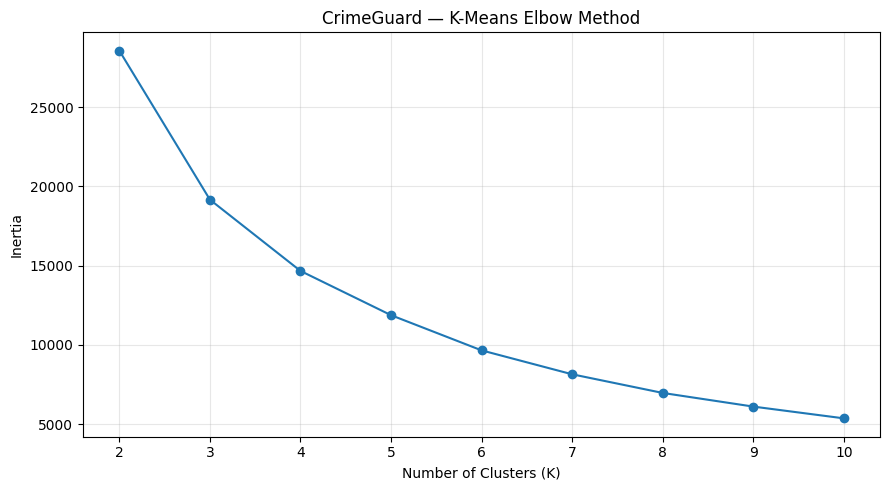


Calculating Silhouette Scores...
K = 2 → Silhouette = 0.4470
K = 3 → Silhouette = 0.4270
K = 4 → Silhouette = 0.4137
K = 5 → Silhouette = 0.3992
K = 6 → Silhouette = 0.3900
K = 7 → Silhouette = 0.4024
K = 8 → Silhouette = 0.4070

Best K according to silhouette: 2

Cluster distribution:


,count
Cluster,
0,17415
1,12585



K-Means Cluster Centers:


,Latitude,Longitude,Cluster
0,41.905121,-87.697990,0
1,41.761922,-87.624022,1



✓ K-Means completed


In [91]:
# ============================================================
# STEP 34 — K-MEANS CRIME HOTSPOTS
# ============================================================

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("CRIMEGUARD — K-MEANS HOTSPOT ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Geographic data
# ------------------------------------------------------------

geo = df[
    ["Latitude", "Longitude"]
].copy()

geo["Latitude"] = pd.to_numeric(
    geo["Latitude"],
    errors="coerce"
)

geo["Longitude"] = pd.to_numeric(
    geo["Longitude"],
    errors="coerce"
)

geo = geo.dropna()

# Remove invalid/outlier coordinates
geo = geo[
    geo["Latitude"].between(41.5, 42.1)
    &
    geo["Longitude"].between(-88.0, -87.4)
].copy()

print(
    "Valid geographic rows:",
    len(geo)
)

# ------------------------------------------------------------
# Sample for faster clustering
# ------------------------------------------------------------

geo_sample = geo.sample(
    min(30000, len(geo)),
    random_state=42
).reset_index(drop=True)

scaler_geo = StandardScaler()

geo_scaled = scaler_geo.fit_transform(
    geo_sample[
        ["Latitude", "Longitude"]
    ]
)

# ============================================================
# ELBOW METHOD
# ============================================================

print("\nCalculating Elbow Method...")

inertias = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(geo_scaled)

    inertias.append(
        model.inertia_
    )

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title(
    "CrimeGuard — K-Means Elbow Method"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# SILHOUETTE SCORE
# ============================================================

print("\nCalculating Silhouette Scores...")

silhouette_scores = {}

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        geo_scaled
    )

    score = silhouette_score(
        geo_scaled,
        labels,
        sample_size=min(
            10000,
            len(geo_scaled)
        ),
        random_state=42
    )

    silhouette_scores[k] = score

for k, score in silhouette_scores.items():

    print(
        f"K = {k} → Silhouette = {score:.4f}"
    )

best_k = max(
    silhouette_scores,
    key=silhouette_scores.get
)

print(
    "\nBest K according to silhouette:",
    best_k
)

# ============================================================
# FINAL K-MEANS
# ============================================================

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

geo_sample["Cluster"] = (
    kmeans_final.fit_predict(
        geo_scaled
    )
)

print("\nCluster distribution:")

display(
    geo_sample[
        "Cluster"
    ]
    .value_counts()
    .sort_index()
)

# ============================================================
# CLUSTER CENTERS
# ============================================================

centers_scaled = (
    kmeans_final.cluster_centers_
)

centers = scaler_geo.inverse_transform(
    centers_scaled
)

kmeans_centers = pd.DataFrame(
    centers,
    columns=[
        "Latitude",
        "Longitude"
    ]
)

kmeans_centers["Cluster"] = range(
    best_k
)

print("\nK-Means Cluster Centers:")

display(
    kmeans_centers
)

# ============================================================
# SAVE
# ============================================================

geo_sample.to_csv(
    "CrimeGuard_KMeans_Hotspots.csv",
    index=False
)

kmeans_centers.to_csv(
    "CrimeGuard_KMeans_Centers.csv",
    index=False
)

pd.DataFrame({
    "K": list(
        silhouette_scores.keys()
    ),
    "Silhouette": list(
        silhouette_scores.values()
    )
}).to_csv(
    "CrimeGuard_KMeans_Silhouette.csv",
    index=False
)

print("\n✓ K-Means completed")

In [92]:
# ============================================================
# STEP 35 — DBSCAN DENSITY HOTSPOTS
# ============================================================

from sklearn.cluster import DBSCAN

print("=" * 70)
print("CRIMEGUARD — DBSCAN HOTSPOT ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Sample geographic data
# ------------------------------------------------------------

dbscan_data = geo.sample(
    min(30000, len(geo)),
    random_state=42
).reset_index(drop=True)

db_scaled = scaler_geo.transform(
    dbscan_data[
        ["Latitude", "Longitude"]
    ]
)

# ------------------------------------------------------------
# DBSCAN
# ------------------------------------------------------------

dbscan_model = DBSCAN(
    eps=0.035,
    min_samples=30,
    n_jobs=-1
)

db_labels = dbscan_model.fit_predict(
    db_scaled
)

dbscan_data["Cluster"] = db_labels

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

real_clusters = set(db_labels) - {-1}

cluster_count = len(
    real_clusters
)

noise_count = int(
    (db_labels == -1).sum()
)

print(
    "Clusters found:",
    cluster_count
)

print(
    "Noise points:",
    noise_count
)

print("\nCluster sizes:")

cluster_sizes = (
    dbscan_data[
        dbscan_data["Cluster"] != -1
    ]
    ["Cluster"]
    .value_counts()
    .sort_values(
        ascending=False
    )
)

display(
    cluster_sizes.head(20)
)

# ------------------------------------------------------------
# Cluster centers
# ------------------------------------------------------------

db_centers = (
    dbscan_data[
        dbscan_data["Cluster"] != -1
    ]
    .groupby("Cluster")[
        ["Latitude", "Longitude"]
    ]
    .mean()
    .reset_index()
)

print("\nDBSCAN Hotspot Centers:")

display(
    db_centers.head(20)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

dbscan_data.to_csv(
    "CrimeGuard_DBSCAN_Hotspots.csv",
    index=False
)

db_centers.to_csv(
    "CrimeGuard_DBSCAN_Centers.csv",
    index=False
)

print("\n✓ DBSCAN completed")

CRIMEGUARD — DBSCAN HOTSPOT ANALYSIS
Clusters found: 110
Noise points: 16595

Cluster sizes:


,count
Cluster,
0,2551
12,680
5,609
10,481
6,476
43,426
4,413
32,398
1,379



DBSCAN Hotspot Centers:


,Cluster,Latitude,Longitude
0,0,41.886116,-87.628732
1,1,41.756822,-87.561351
2,2,41.880493,-87.704813
3,3,42.000278,-87.660837
4,4,41.747306,-87.603593
5,5,41.867237,-87.717435
6,6,41.944901,-87.650495
7,7,41.806935,-87.604515
8,8,41.792476,-87.621431
9,9,41.871099,-87.696500



✓ DBSCAN completed


In [93]:
# ============================================================
# STEP 36 — APRIORI ASSOCIATION RULE MINING
# ============================================================

!pip -q install mlxtend

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
    apriori,
    association_rules
)

print("=" * 70)
print("CRIMEGUARD — APRIORI ASSOCIATION RULE MINING")
print("=" * 70)

# ------------------------------------------------------------
# Sample data
# ------------------------------------------------------------

apriori_df = df.sample(
    min(80000, len(df)),
    random_state=42
).copy()

# ------------------------------------------------------------
# Clean categorical fields
# ------------------------------------------------------------

apriori_columns = [
    "Primary Type",
    "Location Description",
    "District"
]

for col in apriori_columns:

    apriori_df[col] = (
        apriori_df[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

apriori_df["Arrest"] = (
    apriori_df["Arrest"]
    .fillna(False)
    .astype(bool)
)

# ------------------------------------------------------------
# Create transactions
# ------------------------------------------------------------

transactions = []

for _, row in apriori_df.iterrows():

    transaction = [

        "CRIME_" + row["Primary Type"],

        "LOCATION_" +
        row["Location Description"],

        "DISTRICT_" +
        row["District"],

        "ARREST_" +
        (
            "YES"
            if row["Arrest"]
            else "NO"
        )
    ]

    transactions.append(
        list(set(transaction))
    )

print(
    "Transactions:",
    len(transactions)
)

# ------------------------------------------------------------
# One-hot encoding
# ------------------------------------------------------------

encoder = TransactionEncoder()

encoded = encoder.fit(
    transactions
).transform(
    transactions
)

transaction_df = pd.DataFrame(
    encoded,
    columns=encoder.columns_
)

print(
    "Transaction matrix:",
    transaction_df.shape
)

# ------------------------------------------------------------
# Frequent itemsets
# ------------------------------------------------------------

frequent_itemsets = apriori(
    transaction_df,

    min_support=0.005,

    use_colnames=True,

    max_len=3
)

print(
    "\nFrequent itemsets:",
    len(frequent_itemsets)
)

# ------------------------------------------------------------
# Association rules
# ------------------------------------------------------------

rules = association_rules(
    frequent_itemsets,

    metric="confidence",

    min_threshold=0.20
)

# Useful rules
rules = rules[
    (rules["lift"] > 1.0)
    &
    (rules["confidence"] >= 0.40)
].copy()

rules = rules.sort_values(
    [
        "lift",
        "confidence"
    ],
    ascending=False
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "\nUseful association rules:",
    len(rules)
)

display(
    rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

rules.to_csv(
    "CrimeGuard_Apriori_Rules.csv",
    index=False
)

frequent_itemsets.to_csv(
    "CrimeGuard_Frequent_Itemsets.csv",
    index=False
)

print(
    "\n✓ Apriori completed"
)

CRIMEGUARD — APRIORI ASSOCIATION RULE MINING


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Transactions: 80000
Transaction matrix: (80000, 176)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Frequent itemsets: 458

Useful association rules: 180


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
436,"(ARREST_YES, DISTRICT_11)",(CRIME_NARCOTICS),0.009862,0.605991,19.683014
233,(LOCATION_UNKNOWN),"(ARREST_NO, CRIME_DECEPTIVE PRACTICE)",0.005075,1.000000,16.067483
94,(LOCATION_UNKNOWN),(CRIME_DECEPTIVE PRACTICE),0.005075,1.000000,15.555123
231,"(ARREST_NO, LOCATION_UNKNOWN)",(CRIME_DECEPTIVE PRACTICE),0.005075,1.000000,15.555123
439,"(ARREST_YES, LOCATION_SIDEWALK)",(CRIME_NARCOTICS),0.007338,0.443689,14.411322
459,(CRIME_WEAPONS VIOLATION),"(ARREST_YES, LOCATION_STREET)",0.009713,0.424590,9.424865
437,"(CRIME_NARCOTICS, DISTRICT_11)",(ARREST_YES),0.009862,0.988722,6.182409
441,"(CRIME_NARCOTICS, LOCATION_SIDEWALK)",(ARREST_YES),0.007338,0.981605,6.137911
444,"(LOCATION_STREET, CRIME_NARCOTICS)",(ARREST_YES),0.011962,0.967644,6.050612
67,(CRIME_NARCOTICS),(ARREST_YES),0.029612,0.961835,6.014289



✓ Apriori completed


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [96]:
# ============================================================
# STEP 37 — FINAL ROBUST DATA WAREHOUSE / STAR SCHEMA
# ============================================================

import pandas as pd
import numpy as np
import sqlite3
import os

print("🚀 Building CrimeGuard Data Warehouse...\n")

# ------------------------------------------------------------
# 1. COPY ORIGINAL DATA
# ------------------------------------------------------------

dw = df.copy()

# ------------------------------------------------------------
# 2. CLEAN DATE
# ------------------------------------------------------------

dw["Date"] = pd.to_datetime(
    dw["Date"],
    errors="coerce"
)

# ------------------------------------------------------------
# 3. CLEAN CATEGORICAL COLUMNS
# ------------------------------------------------------------

warehouse_cat_cols = [
    "Primary Type",
    "IUCR",
    "FBI Code",
    "Description",
    "District",
    "Community Area",
    "Location Description"
]

for col in warehouse_cat_cols:
    if col in dw.columns:
        dw[col] = (
            dw[col]
            .fillna("UNKNOWN")
            .astype(str)
        )

# ------------------------------------------------------------
# 4. CREATE HOUR COLUMN SAFELY
# ------------------------------------------------------------

if "Hour" in dw.columns:

    dw["Hour"] = pd.to_numeric(
        dw["Hour"],
        errors="coerce"
    )

elif "hour" in dw.columns:

    dw["Hour"] = pd.to_numeric(
        dw["hour"],
        errors="coerce"
    )

else:

    # Extract hour directly from Date
    dw["Hour"] = dw["Date"].dt.hour

# Fill missing hours
dw["Hour"] = dw["Hour"].fillna(0).astype(int)

# Keep valid range
dw["Hour"] = dw["Hour"].clip(0, 23)

# ------------------------------------------------------------
# 5. CLEAN ARREST
# ------------------------------------------------------------

if "Arrest" in dw.columns:

    if dw["Arrest"].dtype == bool:

        dw["Arrest_Flag"] = dw["Arrest"].astype(int)

    else:

        dw["Arrest_Flag"] = (
            dw["Arrest"]
            .astype(str)
            .str.lower()
            .isin(["true", "1", "yes", "y"])
            .astype(int)
        )

else:

    dw["Arrest_Flag"] = 0


# ============================================================
# DIMENSION 1 — DATE
# ============================================================

dim_date = (
    dw[["Date"]]
    .dropna()
    .drop_duplicates()
    .sort_values("Date")
    .reset_index(drop=True)
)

dim_date["date_key"] = (
    dim_date["Date"]
    .dt.strftime("%Y%m%d")
    .astype(int)
)

dim_date["full_date"] = (
    dim_date["Date"]
    .dt.strftime("%Y-%m-%d")
)

dim_date["day"] = dim_date["Date"].dt.day

dim_date["month"] = dim_date["Date"].dt.month

dim_date["month_name"] = (
    dim_date["Date"].dt.month_name()
)

dim_date["quarter"] = (
    dim_date["Date"].dt.quarter
)

dim_date["year"] = (
    dim_date["Date"].dt.year
)

dim_date["day_of_week"] = (
    dim_date["Date"].dt.day_name()
)

dim_date["is_weekend"] = (
    dim_date["Date"].dt.dayofweek >= 5
).astype(int)

dim_date = dim_date[
    [
        "date_key",
        "full_date",
        "day",
        "month",
        "month_name",
        "quarter",
        "year",
        "day_of_week",
        "is_weekend"
    ]
]

print(f"✅ DIM_DATE       : {len(dim_date):,} rows")


# ============================================================
# DIMENSION 2 — TIME
# ============================================================

dim_time = pd.DataFrame({
    "time_key": range(24),
    "hour": range(24)
})


def classify_time(hour):

    if hour < 6:
        return "Night"

    elif hour < 12:
        return "Morning"

    elif hour < 18:
        return "Afternoon"

    else:
        return "Evening"


dim_time["time_period"] = (
    dim_time["hour"]
    .apply(classify_time)
)

dim_time["is_night"] = (
    (dim_time["hour"] >= 22) |
    (dim_time["hour"] < 6)
).astype(int)

print(f"✅ DIM_TIME       : {len(dim_time):,} rows")


# ============================================================
# DIMENSION 3 — CRIME
# ============================================================

crime_columns = [
    "Primary Type",
    "IUCR",
    "FBI Code",
    "Description"
]

dim_crime = (
    dw[crime_columns]
    .drop_duplicates()
    .sort_values(crime_columns)
    .reset_index(drop=True)
)

dim_crime.insert(
    0,
    "crime_key",
    range(1, len(dim_crime) + 1)
)

print(f"✅ DIM_CRIME      : {len(dim_crime):,} rows")


# ============================================================
# DIMENSION 4 — LOCATION
# ============================================================

location_columns = [
    "District",
    "Community Area",
    "Location Description"
]

dim_location = (
    dw[location_columns]
    .drop_duplicates()
    .sort_values(location_columns)
    .reset_index(drop=True)
)

dim_location.insert(
    0,
    "location_key",
    range(1, len(dim_location) + 1)
)

print(f"✅ DIM_LOCATION   : {len(dim_location):,} rows")


# ============================================================
# FACT TABLE
# ============================================================

fact = dw.copy()

# ------------------------------------------------------------
# Date key
# ------------------------------------------------------------

fact = fact[
    fact["Date"].notna()
].copy()

fact["date_key"] = (
    fact["Date"]
    .dt.strftime("%Y%m%d")
    .astype(int)
)

# ------------------------------------------------------------
# Clean merge keys
# ------------------------------------------------------------

for col in crime_columns + location_columns:

    fact[col] = (
        fact[col]
        .fillna("UNKNOWN")
        .astype(str)
    )


# ============================================================
# MERGE CRIME DIMENSION
# ============================================================

fact = fact.merge(
    dim_crime,
    on=crime_columns,
    how="left"
)


# ============================================================
# MERGE LOCATION DIMENSION
# ============================================================

fact = fact.merge(
    dim_location,
    on=location_columns,
    how="left"
)


# ============================================================
# CREATE FACT TABLE
# ============================================================

fact["case_count"] = 1

fact["arrest_flag"] = (
    fact["Arrest_Flag"]
    .fillna(0)
    .astype(int)
)


# ------------------------------------------------------------
# IMPORTANT:
# Explicitly create hour in fact table
# ------------------------------------------------------------

fact["hour"] = (
    fact["Hour"]
    .fillna(0)
    .astype(int)
    .clip(0, 23)
)


# ------------------------------------------------------------
# Latitude / Longitude
# ------------------------------------------------------------

if "Latitude" in fact.columns:

    fact["Latitude"] = pd.to_numeric(
        fact["Latitude"],
        errors="coerce"
    )

else:

    fact["Latitude"] = np.nan


if "Longitude" in fact.columns:

    fact["Longitude"] = pd.to_numeric(
        fact["Longitude"],
        errors="coerce"
    )

else:

    fact["Longitude"] = np.nan


# ============================================================
# FINAL FACT TABLE
# ============================================================

fact_crime = fact[
    [
        "ID",
        "date_key",
        "hour",
        "crime_key",
        "location_key",
        "case_count",
        "arrest_flag",
        "Latitude",
        "Longitude"
    ]
].copy()


print(f"✅ FACT_CRIME     : {len(fact_crime):,} rows")


# ============================================================
# CREATE SQLITE DATABASE
# ============================================================

warehouse_path = "CrimeGuard_Warehouse.db"

# Delete incomplete previous database
if os.path.exists(warehouse_path):
    os.remove(warehouse_path)

conn = sqlite3.connect(
    warehouse_path
)


# ============================================================
# WRITE TABLES
# ============================================================

dim_date.to_sql(
    "dim_date",
    conn,
    if_exists="replace",
    index=False
)

dim_time.to_sql(
    "dim_time",
    conn,
    if_exists="replace",
    index=False
)

dim_crime.to_sql(
    "dim_crime",
    conn,
    if_exists="replace",
    index=False
)

dim_location.to_sql(
    "dim_location",
    conn,
    if_exists="replace",
    index=False
)

fact_crime.to_sql(
    "fact_crime",
    conn,
    if_exists="replace",
    index=False
)


# ============================================================
# CREATE INDEXES
# ============================================================

cursor = conn.cursor()

cursor.execute("""
CREATE INDEX IF NOT EXISTS idx_fact_date
ON fact_crime(date_key)
""")

cursor.execute("""
CREATE INDEX IF NOT EXISTS idx_fact_crime
ON fact_crime(crime_key)
""")

cursor.execute("""
CREATE INDEX IF NOT EXISTS idx_fact_location
ON fact_crime(location_key)
""")

# FIXED: hour is now guaranteed to exist
cursor.execute("""
CREATE INDEX IF NOT EXISTS idx_fact_hour
ON fact_crime(hour)
""")

conn.commit()


# ============================================================
# VERIFY DATABASE
# ============================================================

print("\n" + "=" * 65)
print("📦 CRIMEGUARD DATA WAREHOUSE")
print("=" * 65)

tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type='table'
ORDER BY name
""", conn)

display(tables)


# ------------------------------------------------------------
# Table counts
# ------------------------------------------------------------

for table in [
    "dim_date",
    "dim_time",
    "dim_crime",
    "dim_location",
    "fact_crime"
]:

    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS count FROM {table}",
        conn
    ).iloc[0]["count"]

    print(
        f"{table:<20} {count:>10,} rows"
    )


# ------------------------------------------------------------
# Check fact columns
# ------------------------------------------------------------

print("\nFACT TABLE COLUMNS:")

fact_columns_check = pd.read_sql_query(
    "PRAGMA table_info(fact_crime)",
    conn
)

display(
    fact_columns_check[
        ["name", "type"]
    ]
)


conn.close()


print("\n" + "=" * 65)
print("🎉 STEP 37 COMPLETED SUCCESSFULLY!")
print("=" * 65)

print(
    f"📁 Database: {warehouse_path}"
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

🚀 Building CrimeGuard Data Warehouse...



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

✅ DIM_DATE       : 122,863 rows
✅ DIM_TIME       : 24 rows
✅ DIM_CRIME      : 337 rows


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

dim_date                122,863 rows
dim_time                     24 rows
dim_crime                   337 rows
dim_location              5,632 rows
fact_crime              238,106 rows

FACT TABLE COLUMNS:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,name,type
0,ID,INTEGER
1,date_key,INTEGER
2,hour,INTEGER
3,crime_key,INTEGER
4,location_key,INTEGER
5,case_count,INTEGER
6,arrest_flag,INTEGER
7,Latitude,REAL
8,Longitude,REAL



🎉 STEP 37 COMPLETED SUCCESSFULLY!
📁 Database: CrimeGuard_Warehouse.db


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# ============================================================
# STEP 38 — ULTRA-FAST OLAP PRECOMPUTATION
# ============================================================

import pandas as pd
import numpy as np
import sqlite3
import os
import time

print("🚀 Starting ULTRA-FAST OLAP preparation...")

start_time = time.time()

# ------------------------------------------------------------
# 1. Use original dataframe directly
# ------------------------------------------------------------

olap = df.copy()

print(f"Dataset loaded: {len(olap):,} rows")


# ------------------------------------------------------------
# 2. Prepare date
# ------------------------------------------------------------

olap["Date"] = pd.to_datetime(
    olap["Date"],
    errors="coerce"
)

olap = olap[olap["Date"].notna()].copy()


# ------------------------------------------------------------
# 3. Create date attributes
# ------------------------------------------------------------

olap["Year"] = olap["Date"].dt.year
olap["Month"] = olap["Date"].dt.month
olap["Month_Name"] = olap["Date"].dt.month_name()
olap["Quarter"] = olap["Date"].dt.quarter
olap["Day"] = olap["Date"].dt.day
olap["DayOfWeek"] = olap["Date"].dt.day_name()


# ------------------------------------------------------------
# 4. Prepare Arrest
# ------------------------------------------------------------

if olap["Arrest"].dtype == bool:

    olap["Arrest_Flag"] = (
        olap["Arrest"].astype(int)
    )

else:

    olap["Arrest_Flag"] = (
        olap["Arrest"]
        .astype(str)
        .str.lower()
        .isin(["true", "1", "yes", "y"])
        .astype(int)
    )


# ------------------------------------------------------------
# 5. Prepare Hour
# ------------------------------------------------------------

if "Hour" in olap.columns:

    olap["OLAP_Hour"] = pd.to_numeric(
        olap["Hour"],
        errors="coerce"
    )

else:

    olap["OLAP_Hour"] = (
        olap["Date"].dt.hour
    )

olap["OLAP_Hour"] = (
    olap["OLAP_Hour"]
    .fillna(0)
    .astype(int)
    .clip(0, 23)
)


# ============================================================
# CONNECT DATABASE
# ============================================================

conn = sqlite3.connect(
    "CrimeGuard_Warehouse.db"
)


# ============================================================
# 1️⃣ MONTHLY OLAP
# ============================================================

monthly_olap = (
    olap
    .groupby(
        [
            "Year",
            "Month",
            "Month_Name",
            "Quarter"
        ],
        as_index=False
    )
    .agg(
        crime_count=("Arrest_Flag", "size"),
        arrests=("Arrest_Flag", "sum")
    )
    .sort_values(
        ["Year", "Month"]
    )
)

monthly_olap.to_sql(
    "olap_monthly",
    conn,
    if_exists="replace",
    index=False
)

print(
    f"✅ Monthly OLAP: {len(monthly_olap)} rows"
)


# ============================================================
# 2️⃣ DAILY OLAP
# ============================================================

daily_olap = (
    olap
    .assign(
        Full_Date=olap["Date"].dt.strftime("%Y-%m-%d")
    )
    .groupby(
        [
            "Full_Date",
            "Year",
            "Month",
            "Day",
            "DayOfWeek",
            "Quarter"
        ],
        as_index=False
    )
    .agg(
        crime_count=("Arrest_Flag", "size"),
        arrests=("Arrest_Flag", "sum")
    )
    .sort_values("Full_Date")
)

daily_olap.to_sql(
    "olap_daily",
    conn,
    if_exists="replace",
    index=False
)

print(
    f"✅ Daily OLAP: {len(daily_olap):,} rows"
)


# ============================================================
# 3️⃣ DISTRICT × CRIME OLAP
# ============================================================

district_crime = (
    olap
    .groupby(
        [
            "District",
            "Primary Type"
        ],
        as_index=False
    )
    .agg(
        crime_count=("Arrest_Flag", "size"),
        arrests=("Arrest_Flag", "sum")
    )
    .rename(
        columns={
            "Primary Type": "crime_type"
        }
    )
    .sort_values(
        "crime_count",
        ascending=False
    )
)

district_crime.to_sql(
    "olap_district_crime",
    conn,
    if_exists="replace",
    index=False
)

print(
    f"✅ District × Crime: {len(district_crime):,} rows"
)


# ============================================================
# 4️⃣ HOURLY OLAP
# ============================================================

hourly_olap = (
    olap
    .groupby(
        "OLAP_Hour",
        as_index=False
    )
    .agg(
        crime_count=("Arrest_Flag", "size"),
        arrests=("Arrest_Flag", "sum")
    )
    .rename(
        columns={
            "OLAP_Hour": "hour"
        }
    )
    .sort_values("hour")
)

hourly_olap.to_sql(
    "olap_hourly",
    conn,
    if_exists="replace",
    index=False
)

print(
    f"✅ Hourly OLAP: {len(hourly_olap)} rows"
)


# ============================================================
# 5️⃣ DISTRICT OLAP
# ============================================================

district_olap = (
    olap
    .groupby(
        "District",
        as_index=False
    )
    .agg(
        crime_count=("Arrest_Flag", "size"),
        arrests=("Arrest_Flag", "sum")
    )
    .sort_values(
        "crime_count",
        ascending=False
    )
)

district_olap.to_sql(
    "olap_district",
    conn,
    if_exists="replace",
    index=False
)

print(
    f"✅ District OLAP: {len(district_olap)} rows"
)


# ============================================================
# 6️⃣ CRIME TYPE OLAP
# ============================================================

crime_olap = (
    olap
    .groupby(
        "Primary Type",
        as_index=False
    )
    .agg(
        crime_count=("Arrest_Flag", "size"),
        arrests=("Arrest_Flag", "sum")
    )
    .rename(
        columns={
            "Primary Type": "crime_type"
        }
    )
    .sort_values(
        "crime_count",
        ascending=False
    )
)

crime_olap.to_sql(
    "olap_crime",
    conn,
    if_exists="replace",
    index=False
)

print(
    f"✅ Crime OLAP: {len(crime_olap)} rows"
)


# ============================================================
# 7️⃣ CREATE INDEXES ON SMALL OLAP TABLES
# ============================================================

cursor = conn.cursor()

cursor.execute("""
CREATE INDEX IF NOT EXISTS
idx_olap_month
ON olap_monthly(Year, Month)
""")

cursor.execute("""
CREATE INDEX IF NOT EXISTS
idx_olap_district
ON olap_district(District)
""")

cursor.execute("""
CREATE INDEX IF NOT EXISTS
idx_olap_crime
ON olap_crime(crime_type)
""")

cursor.execute("""
CREATE INDEX IF NOT EXISTS
idx_olap_dc
ON olap_district_crime(District, crime_type)
""")

conn.commit()
conn.close()


# ============================================================
# FINAL
# ============================================================

elapsed = time.time() - start_time

print("\n" + "=" * 65)
print("🎉 ULTRA-FAST OLAP TABLES READY")
print("=" * 65)

print(
    f"⏱️ Processing time: {elapsed:.2f} seconds"
)

print("""
Created:
✓ olap_monthly
✓ olap_daily
✓ olap_district_crime
✓ olap_hourly
✓ olap_district
✓ olap_crime
""")

# OLAP ANALYTICS — FINAL QUERIES

The following queries are kept at the end of the notebook and operate on the compact `olap_*` summary tables created in Step 38. This avoids repeatedly scanning and joining the full fact table.

## OLAP 1 — Roll-up

Hierarchy: **Year → Quarter → Month**

In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("CrimeGuard_Warehouse.db")

# Year-level roll-up
rollup_year = pd.read_sql_query("""
SELECT
    Year,
    SUM(crime_count) AS crime_count,
    SUM(arrests) AS arrests
FROM olap_monthly
GROUP BY Year
ORDER BY Year
""", conn)

print("YEAR-LEVEL ROLL-UP")
display(rollup_year)

# Quarter-level roll-up
rollup_quarter = pd.read_sql_query("""
SELECT
    Year,
    Quarter,
    SUM(crime_count) AS crime_count,
    SUM(arrests) AS arrests
FROM olap_monthly
GROUP BY Year, Quarter
ORDER BY Year, Quarter
""", conn)

print("QUARTER-LEVEL ROLL-UP")
display(rollup_quarter)

# Month-level detail
rollup_month = pd.read_sql_query("""
SELECT
    Year,
    Month,
    Month_Name,
    Quarter,
    crime_count,
    arrests
FROM olap_monthly
ORDER BY Year, Month
""", conn)

print("MONTH-LEVEL DETAIL")
display(rollup_month)


## OLAP 2 — Drill-down

Hierarchy: **Year → Month → Day**

In [ ]:
# Year
drill_year = pd.read_sql_query("""
SELECT
    Year,
    SUM(crime_count) AS crime_count,
    SUM(arrests) AS arrests
FROM olap_monthly
GROUP BY Year
ORDER BY Year
""", conn)

# Month
drill_month = pd.read_sql_query("""
SELECT
    Year, Month, Month_Name, crime_count, arrests
FROM olap_monthly
ORDER BY Year, Month
""", conn)

# Day
drill_day = pd.read_sql_query("""
SELECT
    Full_Date, Year, Month, Day, DayOfWeek,
    crime_count, arrests
FROM olap_daily
ORDER BY Full_Date
LIMIT 50
""", conn)

print("YEAR LEVEL")
display(drill_year)
print("MONTH LEVEL")
display(drill_month)
print("DAY LEVEL — first 50 rows")
display(drill_day)


## OLAP 3 — Slice

A slice selects one value from a dimension. The busiest district is selected automatically so the query remains valid for this dataset.

In [ ]:
districts = pd.read_sql_query("""
SELECT District, crime_count, arrests
FROM olap_district
ORDER BY crime_count DESC
""", conn)

selected_district = str(districts.iloc[0]["District"])

slice_result = pd.read_sql_query(
    """
    SELECT District, crime_type, crime_count, arrests
    FROM olap_district_crime
    WHERE District = ?
    ORDER BY crime_count DESC
    """,
    conn,
    params=[selected_district]
)

print(f"SLICE — DISTRICT {selected_district}")
display(slice_result)


## OLAP 4 — Dice

A dice operation filters multiple dimensions simultaneously.

In [ ]:
dice_result = pd.read_sql_query("""
SELECT
    District,
    crime_type,
    crime_count,
    arrests
FROM olap_district_crime
WHERE District IN (
    SELECT District
    FROM olap_district
    ORDER BY crime_count DESC
    LIMIT 3
)
AND crime_type IN ('THEFT', 'BATTERY', 'ASSAULT')
ORDER BY crime_count DESC
""", conn)

print("DICE RESULT")
display(dice_result)


## OLAP 5 — Pivot

District × Crime Type matrix for dashboard-ready analysis.

In [ ]:
pivot_data = pd.read_sql_query("""
SELECT
    District,
    crime_type,
    crime_count
FROM olap_district_crime
""", conn)

pivot_table = pivot_data.pivot_table(
    index="District",
    columns="crime_type",
    values="crime_count",
    aggfunc="sum",
    fill_value=0
)

print("DISTRICT × CRIME TYPE PIVOT")
display(pivot_table)


## OLAP 6 — Export Analytics

Export the compact OLAP summaries for the FastAPI/React dashboard.

In [ ]:
import os

output_dir = "CrimeGuard_Warehouse_Analytics"
os.makedirs(output_dir, exist_ok=True)

exports = {
    "crime_summary.csv": "SELECT * FROM olap_crime",
    "district_summary.csv": "SELECT * FROM olap_district",
    "hour_summary.csv": "SELECT * FROM olap_hourly",
    "monthly_summary.csv": "SELECT * FROM olap_monthly",
    "daily_summary.csv": "SELECT * FROM olap_daily",
    "district_crime_summary.csv": "SELECT * FROM olap_district_crime"
}

for filename, query in exports.items():
    data = pd.read_sql_query(query, conn)
    data.to_csv(os.path.join(output_dir, filename), index=False)
    print(f"✓ {filename}")

print("\n✅ OLAP analytics exported successfully.")


## Final Warehouse & OLAP Verification

In [ ]:
tables = pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name
""", conn)

print("WAREHOUSE + OLAP TABLES")
display(tables)

olap_tables = [
    "olap_monthly",
    "olap_daily",
    "olap_district",
    "olap_district_crime",
    "olap_hourly",
    "olap_crime"
]

print("OLAP TABLE SIZES")
for table in olap_tables:
    count = pd.read_sql_query(
        f"SELECT COUNT(*) AS n FROM {table}", conn
    ).iloc[0]["n"]
    print(f"{table:<25} {count:>8,} rows")

conn.close()

print("\n" + "=" * 60)
print("🎉 CRIMEGUARD OLAP SECTION COMPLETED")
print("=" * 60)
